# 🚗 Araç Hasar Tespit Sistemi — Tez Pipeline **v6**

> Sigorta sektöründe hasar tespitinin derin öğrenme ile otomasyonu

---

## 🔬 v6'ya Götüren Bulgu

v5'te harici veri **görsel olarak** incelendi. Poligon kalitesi iyi çıktı —
kullanıcının tarzına benzer şekilde, hassas işaretlenmiş.

**Ama sınıf tanımları çelişiyor:**

```
Bizim  "Cizik"  dediğimize  →  onlar "crack"  demiş
Bizim  "Kirik"  dediğimize  →  onlar "scratch" demiş
```

Model çelişkili örnek görünce **her iki sınıfta da** güven kaybediyor.
v4'te `Cizik 0,8421 → 0,1627` düşmesinin gerçek sebebi buydu.

---

## ✅ v6 Çözümü: Sadece Göçük Al

| Harici sınıf | Karar | Gerekçe |
|---|---|---|
| `dent` → **Gocuk** | ✅ AL | Tanım nesnel — panel çökmüş, yorum farkı yok |
| `scratch` → Cizik | ❌ ATLA | Cizik ↔ Kirik çelişkisi |
| `crack` → Kirik | ❌ ATLA | Cizik ↔ Kirik çelişkisi |

**Bonus:** Kullanıcının asıl şikayeti de göçük tespitiydi (kaput %21, tampon %16 güven).
Tam ihtiyaç duyulan sınıf güçleniyor.

---

## 📈 Sürüm Geçmişi (kendi test setinde)

| Sürüm | Yapılandırma | Kendi veri | Mask mAP50 |
|---|---|---|---|
| v0 | 640px, tiling yok, 60 ep | %100 | 0,4325 |
| v1 | 960px + tiling, 45 ep | %100 | 0,5918 |
| v3 | 120 ep, boş tile %25 | %100 | **0,6894** ⭐ |
| v4 | 3 harici kaynak, 3 sınıf | %17 | 0,3319 ❌ |
| v5 | 1 kaynak, 3 sınıf | %79 | ~0,63 ⚠️ |
| **v6** | **1 kaynak, sadece `dent` + Large** | **~%91** | **hedef 0,72-0,76** |

---

## ⚙️ v6 Değişiklik Listesi

| Alan | v5 | v6 | Beklenen kazanç |
|---|---|---|---|
| Harici sınıf | 3 sınıf | **sadece `dent`** | **+0,03-0,05** |
| Model | Medium (22M) | **Large (28M)** | +0,02-0,03 |
| Epoch | 120 | **150** | — |
| Batch | 8 | **6** | (VRAM) |
| `cls` | 0.6 | **0.5** | +0,01-0,02 |
| `box` | 7.5 | **8.0** | +0,00-0,01 |
| `close_mosaic` | 15 | **20** | +0,01 |
| Oversampling | Kapalı | **Açık** (1.5) | +0,01 |
| **TTA** | Yok | **Açık** | **+0,02-0,03** |

---

## 🏗️ Sistem Mimarisi

```
                    [Hasarlı Araç Fotoğrafı]
                              │
              ┌───────────────┴───────────────┐
              ▼                               ▼
   ┌────────────────────┐         ┌────────────────────┐
   │  MODEL 1: KONUM    │         │  MODEL 2: HASAR    │
   │  Carparts-Seg      │         │  %91 kendi + dent  │
   │  23 → 8 parça      │         │  Cizik/Gocuk/Kirik │
   │  YOLOv11m, 640px   │         │  YOLOv11l, 960px   │
   └────────────────────┘         │  + Tiling + TTA    │
              │                   └────────────────────┘
              │                               │
              └───────────────┬───────────────┘
                              ▼
                  ┌───────────────────────┐
                  │   FÜZYON (Örtüşme)    │
                  │  → Tampon-Kirik       │
                  └───────────────────────┘
                              │
              ┌───────────────┴───────────────┐
              ▼                               ▼
     ┌─────────────────┐            ┌──────────────────┐
     │  GÖRSEL ÇIKTI   │            │  TRAMER RAPORU   │
     │  3 panel        │            │  PDF belge       │
     └─────────────────┘            └──────────────────┘
```

---

## ⚙️ ÇALIŞTIRMA SIRASI

### 🔨 İlk kez (v6 eğitimi)

```
0 → 1 → 3 → 4 → 4A → 4A2 → 4D → 4B → 4C → 4E → (temizlik) → 5
```

| Hücre | İçerik | Süre |
|---|---|---|
| **0** | Drive bağlantısı | 1 dk |
| **1** | v6 ayarları (API key!) | 2 dk |
| 2 | *(atla — Carparts zaten indi)* | — |
| **3** | `EGIT_KONUM=False` → path tanımlar | 5 sn |
| **4** | Hasar verisi indir | ~10 dk |
| **4A** | Harici veri (**sadece dent**) | ~5 dk |
| **4A2** | Oversampling (**AKTİF**) | ~3 dk |
| **4D** | Tiling | ~20 dk |
| **4B** | Küçük annotation filtresi | ~5 dk |
| **4C** | Split 70/20/10 | ~5 dk |
| **4E** | **Dataset yedekle (ZORUNLU)** | ~10 dk |
| (temizlik) | Eski v6 klasörünü sil | 5 sn |
| **5** | **EĞİTİM** | **~30 saat** |

### 🔄 Kopma sonrası

```
0 → 0B → 1 → 5 (RESUME=True)
```

⚠️ Hücre 1'deki **hiçbir ayarı değiştirme** — resume tutarlılık ister.

### ⚡ Model hazırsa

```
0 → 1 → 6D → 7 → 8 / 9 / 10
```

---

## ✅ KONTROL NOKTALARI

Bu değerleri görmezsen **dur ve kontrol et:**

| Hücre | Görmen gereken |
|---|---|
| **4A** | `Kaynak sayısı : 1`, `Alınacak sınıf: ['Gocuk']` |
| **4A** | `⏭️ scratch → atla`, `⏭️ crack → atla` |
| **4A2** | `Dengesizlik oranı: ~1.45 (önce ~1.70)` |
| **4C** | `train: ~34.000` |
| **5** | `yolo11l-seg`, `batch=6`, `Epoch 1/150` |
| **5 (ilk 20 ep)** | `nan` **görmemelisin** |

---

> ⚡ **Colab Pro+:** A100 GPU + High-RAM + arka plan yürütme açık
>
> 🔋 Tahmini işlem birimi: ~400  |  ⏱️ 2 oturum


---
## 💾 HÜCRE 0: Google Drive Bağlantısı

⚠️ **İLK ÇALIŞTIR.** Session kapanınca `/content` silinir; bu hücre her şeyi Drive'a kaydeder.

Altındaki ikinci hücre önceki sürüm sonuçlarını `yedekler/` klasörüne kopyalar ve JSON'u sıfırlar.


In [1]:
# ═══════════════════════════════════════════════════════════════════════════════
# 💾 HÜCRE 0: GOOGLE DRIVE BAĞLANTISI
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NEDEN GEREKLİ?
#    Colab session kapanınca /content silinir. Eğitilen modeller kaybolur.
#    Bu hücre her şeyi Drive'a kaydeder → bir kez eğit, sonsuza kadar kullan.
#
# 📁 DRIVE KLASÖR YAPISI:
#    MyDrive/tez_arac_hasar/
#       ├── modeller/          ← Eğitilen tüm modeller (.pt)
#       ├── ciktilar/          ← Grafikler, Excel, PDF raporlar
#       └── karsilastirma_sonuclari.json
# ═══════════════════════════════════════════════════════════════════════════════

import os

DRIVE_KULLAN = True   # False yaparsan sadece geçici diske kaydeder

if DRIVE_KULLAN:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        ANA_DIZIN = '/content/drive/MyDrive/tez_arac_hasar'
        print('✅ Drive bağlandı')
    except Exception as e:
        print(f'⚠️ Drive bağlanamadı: {str(e)[:80]}')
        print('   Geçici diske kaydedilecek (session kapanınca silinir!)')
        ANA_DIZIN = '/content/tez_arac_hasar'
else:
    ANA_DIZIN = '/content/tez_arac_hasar'
    print('⚠️ Drive kullanılmıyor — modeller session sonunda silinecek!')

# ─── KLASÖRLERİ OLUŞTUR ───────────────────────────────────────────────────────
MODEL_DIZIN = os.path.join(ANA_DIZIN, 'modeller')
OUTPUT_DIR  = os.path.join(ANA_DIZIN, 'ciktilar')
RAPOR_DIR   = os.path.join(OUTPUT_DIR, 'raporlar')
GORSEL_DIR  = os.path.join(OUTPUT_DIR, 'gorseller')

for d in [ANA_DIZIN, MODEL_DIZIN, OUTPUT_DIR, RAPOR_DIR, GORSEL_DIR]:
    os.makedirs(d, exist_ok=True)

SONUC_JSON = os.path.join(ANA_DIZIN, 'karsilastirma_sonuclari_v6.json')

print()
print('=' * 70)
print('📁 KLASÖR YAPISI')
print('=' * 70)
print(f'   Ana dizin : {ANA_DIZIN}')
print(f'   Modeller  : {MODEL_DIZIN}')
print(f'   Çıktılar  : {OUTPUT_DIR}')
print(f'   Sonuç JSON: {SONUC_JSON}')

# ─── DİSK DURUMU ──────────────────────────────────────────────────────────────
import shutil as _sh
_t, _k, _bos = _sh.disk_usage('/content')
print(f'\n💾 Geçici disk: {_bos/1e9:.1f} GB boş / {_t/1e9:.1f} GB toplam')
if _bos / 1e9 < 15:
    print('   ⚠️ Tiling için az olabilir. ORIJINALI_TUT=False öneriliyor.')

# ─── MEVCUT MODELLERİ KONTROL ET ──────────────────────────────────────────────
print()
print('=' * 70)
print('🔍 MEVCUT MODELLER')
print('=' * 70)

import glob, json as _json

bulunan = glob.glob(f'{MODEL_DIZIN}/**/weights/best.pt', recursive=True)
if bulunan:
    for mp in sorted(bulunan):
        ad = mp.split('/')[-3]
        boyut = os.path.getsize(mp) / 1e6
        print(f'   ✅ {ad:38s} ({boyut:6.1f} MB)')
    print(f'\n   💡 Bu modeller tekrar eğitilmeyecek — Hücre 5 otomatik atlar.')
    print(f'   ⚡ Sadece kullanmak istersen: Hücre 1 → 6D → 7')
else:
    print('   (henüz model yok — Hücre 3 ve 5 ile eğitilecek)')

if os.path.exists(SONUC_JSON):
    with open(SONUC_JSON) as f:
        _s = _json.load(f)
    if _s:
        print(f'\n   📊 Kayıtlı karşılaştırma: {len(_s)} model')
        for k, v in sorted(_s.items(), key=lambda x: -x[1].get('mask_mAP50', 0)):
            print(f'      {v.get("ad", k):32s} mAP50={v.get("mask_mAP50", 0):.4f}')

print('=' * 70)


Mounted at /content/drive
✅ Drive bağlandı

📁 KLASÖR YAPISI
   Ana dizin : /content/drive/MyDrive/tez_arac_hasar
   Modeller  : /content/drive/MyDrive/tez_arac_hasar/modeller
   Çıktılar  : /content/drive/MyDrive/tez_arac_hasar/ciktilar
   Sonuç JSON: /content/drive/MyDrive/tez_arac_hasar/karsilastirma_sonuclari_v6.json

💾 Geçici disk: 202.5 GB boş / 253.1 GB toplam

🔍 MEVCUT MODELLER
   ✅ hasar_yolo11l-seg                      (  55.8 MB)
   ✅ hasar_yolo11l-seg_v6_fp32              (  55.9 MB)
   ✅ hasar_yolo11l-seg_v6_large_gocuk       ( 222.1 MB)
   ✅ hasar_yolo11m-seg                      (  45.2 MB)
   ✅ hasar_yolo11m-seg_sadece_kendi_veri    (  45.2 MB)
   ✅ hasar_yolo11m-seg_v5_dengeli           (  45.2 MB)
   ✅ hasar_yolo11n-seg                      (   6.0 MB)
   ✅ hasar_yolo11s-seg                      (  20.5 MB)
   ✅ hasar_yolov8m-seg                      (  54.8 MB)
   ✅ kfold_yolo11m-seg_f1                   (  45.2 MB)
   ✅ kfold_yolo11m-seg_f2                   (  45.2 

In [2]:
# ═══════════════════════════════════════════════════════════════════════════════
# 💾 ADIM 1: MEVCUT SONUÇLARI YEDEKLE
# ═══════════════════════════════════════════════════════════════════════════════
# ⚠️ Yeni eğitim eskinin üzerine yazacak. Karşılaştırma yapabilmek için önce yedekle.
# ⚠️ Bu hücreyi Hücre 0'DAN SONRA çalıştır (ANA_DIZIN tanımlı olmalı).
# ═══════════════════════════════════════════════════════════════════════════════

import shutil, os, json, glob
from datetime import datetime

if 'ANA_DIZIN' not in globals():
    raise RuntimeError('❌ Önce HÜCRE 0\'ı çalıştır!')

ETIKET = f'v1_45epoch_{datetime.now().strftime("%Y%m%d_%H%M")}'
YEDEK = os.path.join(ANA_DIZIN, 'yedekler', ETIKET)
os.makedirs(YEDEK, exist_ok=True)

print('=' * 70)
print(f'💾 YEDEKLEME: {ETIKET}')
print('=' * 70)

# 1. Sonuç JSON
if os.path.exists(SONUC_JSON):
    shutil.copy(SONUC_JSON, os.path.join(YEDEK, 'karsilastirma_sonuclari.json'))
    with open(SONUC_JSON) as f:
        _eski = json.load(f)
    print(f'✅ Sonuç JSON yedeklendi ({len(_eski)} model)')
    for k, v in _eski.items():
        print(f'   {v.get("ad","?"):22s} mAP50={v.get("mask_mAP50",0):.4f}')

# 2. Çıktılar (grafikler, Excel, LaTeX)
sayac = 0
if os.path.exists(OUTPUT_DIR):
    for f in os.listdir(OUTPUT_DIR):
        p = os.path.join(OUTPUT_DIR, f)
        if os.path.isfile(p):
            shutil.copy(p, os.path.join(YEDEK, f))
            sayac += 1
    print(f'✅ {sayac} çıktı dosyası yedeklendi')

# 3. Model ağırlıkları
for mp in glob.glob(f'{MODEL_DIZIN}/hasar_*/weights/best.pt'):
    ad = mp.split('/')[-3]
    boyut = os.path.getsize(mp) / 1e6
    shutil.copy(mp, os.path.join(YEDEK, f'{ad}_best.pt'))
    print(f'✅ Model yedeklendi: {ad} ({boyut:.1f} MB)')

# 4. Sonuç JSON'unu SIFIRLA
with open(SONUC_JSON, 'w') as f:
    json.dump({}, f)

print()
print('=' * 70)
print(f'📦 Yedek: {YEDEK}')
print(f'🔄 Sonuç JSON sıfırlandı — yeni eğitim temiz başlayacak')
print('=' * 70)
print('\n➡️  SONRAKİ: Hücre 1 (yeni ayarlarla) → 4 → 4A → 4D → 4B → 4C → 5')

💾 YEDEKLEME: v1_45epoch_20260816_1255
✅ Sonuç JSON yedeklendi (0 model)
✅ 26 çıktı dosyası yedeklendi
✅ Model yedeklendi: hasar_yolo11n-seg (6.0 MB)
✅ Model yedeklendi: hasar_yolo11s-seg (20.5 MB)
✅ Model yedeklendi: hasar_yolo11m-seg (45.2 MB)
✅ Model yedeklendi: hasar_yolo11l-seg (55.8 MB)
✅ Model yedeklendi: hasar_yolov8m-seg (54.8 MB)
✅ Model yedeklendi: hasar_yolo11m-seg_sadece_kendi_veri (45.2 MB)
✅ Model yedeklendi: hasar_yolo11m-seg_v5_dengeli (45.2 MB)
✅ Model yedeklendi: hasar_yolo11l-seg_v6_large_gocuk (222.1 MB)
✅ Model yedeklendi: hasar_yolo11l-seg_v6_fp32 (55.9 MB)

📦 Yedek: /content/drive/MyDrive/tez_arac_hasar/yedekler/v1_45epoch_20260816_1255
🔄 Sonuç JSON sıfırlandı — yeni eğitim temiz başlayacak

➡️  SONRAKİ: Hücre 1 (yeni ayarlarla) → 4 → 4A → 4D → 4B → 4C → 5


---
## ♻️ HÜCRE 0B: Dataset Geri Yükleme

> ⏭️ **İlk çalıştırmada ATLA.** Sadece session kapandıysa ve eğitime devam edeceksen kullan.

> Sıra: `Hücre 0` → **`Hücre 0B`** → `Hücre 1` → `Hücre 5 (RESUME=True)`


In [3]:
# ═══════════════════════════════════════════════════════════════════════════════
# ♻️ HÜCRE 0B: DATASET GERİ YÜKLEME  (v6 uyumlu)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE ZAMAN KULLANILIR?
#    Session tamamen kapandığında /content silinir → dataset kaybolur.
#    Dataset olmadan RESUME çalışmaz. Bu hücre Drive'daki yedeği geri yükler.
#
# ⏭️ İLK ÇALIŞTIRMADA ATLA — henüz yedek yok.
#
# ⚠️ v6 DÜZELTMESİ:
#    Drive'da iki yedek var — v5.1 ve v6 farklı dataset kullanıyor:
#       dataset_yedek.zip     → v5.1  (train 17.637)
#       dataset_yedek_v6.zip  → v6    (train 15.490)
#    YANLIŞ yedekle resume edersen model farklı veriyle devam eder!
#    Aşağıdaki SURUM değişkeniyle hangisini yükleyeceğini seç.
#
# 📋 KOPMA SONRASI SIRA:
#    1. Hücre 0   → Drive bağla
#    2. Hücre 0B  → BU HÜCRE (doğru SURUM'u seç!)
#    3. Hücre 1   → ayarlar (HİÇBİR ŞEYİ DEĞİŞTİRME!)
#    4. Hücre 5   → RESUME = True yap, çalıştır
# ═══════════════════════════════════════════════════════════════════════════════

import shutil, os, time, yaml, glob
from pathlib import Path

# ─── HANGİ SÜRÜMÜN DATASET'İ? ─────────────────────────────────────────────────
SURUM = 'v6'          # 'v6' | 'v5' | 'ham'

YEDEKLER = {
    'v6':  ('dataset_yedek_v6.zip',    '/content/dataset_v6',    15490),
    'v5':  ('dataset_yedek.zip',       '/content/dataset_v5',    17637),
    'ham': ('dataset_HAM_birlesim.zip','/content/dataset_ham',    None),  # tiling öncesi
}

if SURUM not in YEDEKLER:
    raise ValueError(f'❌ Geçersiz SURUM: {SURUM}. Seçenekler: {list(YEDEKLER)}')

zip_ad, HEDEF, beklenen = YEDEKLER[SURUM]
ZIP = os.path.join(ANA_DIZIN, zip_ad)

# ─── MEVCUT YEDEKLERİ LİSTELE ─────────────────────────────────────────────────
print('=' * 70)
print('📦 DRIVE\'DAKİ YEDEKLER')
print('=' * 70)
bulunan = sorted(glob.glob(f'{ANA_DIZIN}/*.zip'))
if bulunan:
    for z in bulunan:
        ad = os.path.basename(z)
        isaret = '👉' if ad == zip_ad else '  '
        print(f'   {isaret} {ad:35s} {os.path.getsize(z)/1e9:.2f} GB')
else:
    print('   (hiç yedek yok)')
print()

# ─── YÜKLE ────────────────────────────────────────────────────────────────────
if not os.path.exists(ZIP):
    print('=' * 70)
    print(f'⚠️  YEDEK BULUNAMADI: {zip_ad}')
    print('=' * 70)
    print('   Bu normaldir eğer:')
    print('   • İlk kez çalıştırıyorsan → bu hücreyi ATLA, Hücre 1\'e geç')
    print('   • Yedekleme (4E) çalıştırılmadıysa → veri hazırlığını')
    print('     (Hücre 4 → 4A → 4A2 → 4D → 4B → 4C) tekrar yap')
    print('=' * 70)
else:
    print('=' * 70)
    print(f'♻️  DATASET GERİ YÜKLENİYOR — {SURUM.upper()}')
    print('=' * 70)
    print(f'   Kaynak: {zip_ad}  ({os.path.getsize(ZIP)/1e9:.2f} GB)')
    print(f'   Hedef : {HEDEF}')
    print(f'   ⏳ 1-15 dakika...\n')

    t0 = time.time()
    shutil.rmtree(HEDEF, ignore_errors=True)
    shutil.unpack_archive(ZIP, HEDEF)

    DATASET_DIR     = HEDEF
    HASAR_DATA_YAML = os.path.join(DATASET_DIR, 'data.yaml')

    # data.yaml'ı yeni konuma göre yaz
    with open(HASAR_DATA_YAML, 'w') as f:
        yaml.dump({
            'train': os.path.join(DATASET_DIR, 'train', 'images'),
            'val':   os.path.join(DATASET_DIR, 'valid', 'images'),
            'test':  os.path.join(DATASET_DIR, 'test',  'images'),
            'nc':    len(HASAR_SINIFLAR) if 'HASAR_SINIFLAR' in globals() else 3,
            'names': HASAR_SINIFLAR if 'HASAR_SINIFLAR' in globals()
                     else ['Cizik','Gocuk','Kirik'],
        }, f, default_flow_style=False, sort_keys=False)

    # Eski cache'leri sil (yanlış yol içeriyorlar)
    silinen = 0
    for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
        os.remove(c); silinen += 1

    # ─── DOĞRULAMA ────────────────────────────────────────────────────────────
    print(f'✅ Geri yüklendi ({(time.time()-t0)/60:.1f} dk)')
    if silinen:
        print(f'   🗑️  {silinen} cache dosyası silindi')
    print()

    sayilar = {}
    for s in ['train','valid','test']:
        d = os.path.join(DATASET_DIR, s, 'images')
        n = len(list(Path(d).glob('*.*'))) if os.path.exists(d) else 0
        sayilar[s] = n
        print(f'   {s:6s}: {n:6,} görsel')
    print(f'   {"─"*22}')
    print(f'   TOPLAM: {sum(sayilar.values()):6,}')

    # Beklenen sayı kontrolü
    if beklenen:
        print()
        if sayilar['train'] == beklenen:
            print(f'   ✅ DOĞRU DATASET — train {beklenen:,} (beklenen)')
        else:
            print(f'   ⚠️⚠️  UYARI: train {sayilar["train"]:,}, '
                  f'beklenen {beklenen:,}')
            print(f'      Yanlış yedek yüklenmiş olabilir!')
            print(f'      SURUM değişkenini kontrol et.')

    # Kaynak dağılımı
    lbl = os.path.join(DATASET_DIR, 'train', 'labels')
    if os.path.exists(lbl):
        from collections import Counter
        c = Counter()
        for f in Path(lbl).glob('*.txt'):
            if   f.stem.startswith('HX'): c['harici'] += 1
            elif f.stem.startswith('OS'): c['oversampling'] += 1
            elif f.stem.startswith('KW'): c['kendi_kopya'] += 1
            else:                         c['kendi'] += 1
        t = sum(c.values())
        if t:
            print(f'\n   📊 KAYNAK DAĞILIMI:')
            for k, v in c.most_common():
                print(f'      {k:14s}: {v:6,}  (%{v/t*100:.1f})')

    print()
    print(f'   DATASET_DIR     = {DATASET_DIR}')
    print(f'   HASAR_DATA_YAML = {HASAR_DATA_YAML}')
    print('=' * 70)
    print('\n➡️  ŞİMDİ: Hücre 1 (ayarları DEĞİŞTİRME) → Hücre 5 (RESUME=True)')

📦 DRIVE'DAKİ YEDEKLER
      dataset_HAM_birlesim.zip            0.66 GB
      dataset_yedek.zip                   1.24 GB
   👉 dataset_yedek_v6.zip                1.24 GB

♻️  DATASET GERİ YÜKLENİYOR — V6
   Kaynak: dataset_yedek_v6.zip  (1.24 GB)
   Hedef : /content/dataset_v6
   ⏳ 1-15 dakika...



KeyboardInterrupt: 

---
## 🔧 HÜCRE 1: Kurulum + Tüm Ayarlar

🎯 **Tüm parametreler burada.** Diğer hücreler bu değerleri okur, ezmez.

### v6'nın iki kritik farkı

| | v5 | v6 |
|---|---|---|
| Harici sınıf | Cizik + Gocuk + Kirik | **sadece Gocuk** |
| Model | Medium (22M) | **Large (28M)** |

⚠️ Harici veride `scratch`/`crack` bizim tanımımızla **çelişiyor** — bu yüzden atlanıyor.


In [8]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔧 HÜCRE 1: KURULUM + GLOBAL AYARLAR  (v6 — SINIF ÇELİŞKİSİ ÇÖZÜMÜ)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🔬 v6'YA GÖTÜREN BULGU:
#    v5'te harici veri görsel olarak incelendi. Sonuç:
#    → Poligon kalitesi İYİ (kullanıcının tarzına benzer)
#    → AMA sınıf tanımları ÇELİŞİYOR: bizim "Cizik" dediğimize "Kirik",
#      bizim "Kirik" dediğimize "Cizik" demişler.
#
#    Model çelişkili örnek görünce her iki sınıfta da güven kaybediyor.
#    v4'te Cizik 0,8421 → 0,1627 düşmesinin gerçek sebebi buydu.
#
# ✅ v6 ÇÖZÜMÜ — SADECE GÖÇÜK AL:
#    'dent' → Gocuk   ✅ (tanım nesnel: panel çökmüş, yorum farkı yok)
#    'scratch'        ❌ (Cizik ↔ Kirik çelişkisi)
#    'crack'          ❌ (Cizik ↔ Kirik çelişkisi)
#
#    Bonus: Kullanıcının asıl şikayeti de göçük tespitiydi (kaput %21,
#    tampon %16 güven). Tam ihtiyaç duyulan sınıf güçleniyor.
#
# ⚙️ v6 DİĞER DEĞİŞİKLİKLER:
#    - Model      : yolo11m-seg → yolo11l-seg (22M → 28M parametre)
#    - Epoch      : 120 → 150 (large daha yavaş yakınsar)
#    - Batch      : 8 → 6 (large daha çok VRAM yer)
#    - cls        : 0.6 → 0.5 (daha cesur tahmin, recall artışı)
#    - box        : 7.5 → 8.0 (lokalizasyon vurgusu)
#    - close_mosaic: 15 → 20 (daha uzun temiz eğitim)
#    - Oversampling: AÇIK (sadece dent gelince Gocuk şişecek, dengelenmeli)
#    - TTA        : Hücre 7'de açık (tahminde +0,02-0,03)
#
# 📊 SÜRÜM GEÇMİŞİ (kendi test setinde)
#    v0  640px, tiling yok           → 0,4325
#    v1  960px + tiling, 45 ep       → 0,5918
#    v3  120 ep, boş tile %25        → 0,6894  ⭐ referans
#    v4  3 harici kaynak (%83)       → 0,3319  ❌ domain shift
#    v5  1 kaynak, 3 sınıf (%21)     → ~0,63   ⚠️ sınıf çelişkisi
#    v6  1 kaynak, SADECE dent       → hedef 0,72-0,76
# ═══════════════════════════════════════════════════════════════════════════════

!pip install ultralytics roboflow reportlab openpyxl shapely imagehash -q

import os, torch, warnings
warnings.filterwarnings('ignore')

# ═══ ROBOFLOW ══════════════════════════════════════════════════════════════════
API_KEY        = os.environ['ROBOFLOW_API_KEY']
WORKSPACE      = 'burhans-workspace-fev5o'
HASAR_PROJECT  = 'my-first-project-2-llolj-0rqmz'

HASAR_VERSION       = None     # None = en son version
ZORLA_YENI_VERSION  = False    # 1024'lük version zaten var

# ═══ MODEL 1: KONUM (PARÇA) ════════════════════════════════════════════════════
KONUM_DATASET = 'carparts-seg.yaml'

KONUM_MAP = {
    'back_bumper': 'Tampon',       'front_bumper': 'Tampon',
    'back_glass':  'Cam',          'front_glass':  'Cam',
    'back_left_door':   'Kapi',    'back_right_door':  'Kapi',
    'front_left_door':  'Kapi',    'front_right_door': 'Kapi',
    'back_left_light':  'Far',     'back_right_light': 'Far',
    'front_left_light': 'Far',     'front_right_light':'Far',
    'hood':        'Kaput',
    'left_mirror': 'Dikiz-Ayna',   'right_mirror': 'Dikiz-Ayna',
    'tailgate':    'Bagaj',        'trunk':        'Bagaj',
    'wheel':       'Camurluk',
}
KONUM_SINIFLAR = ['Tampon','Kaput','Kapi','Camurluk','Bagaj','Far','Cam','Dikiz-Ayna']

KONUM_IMG_SIZE = 640
KONUM_EPOCHS   = 60
KONUM_BATCH    = 12

# ═══ MODEL 2: HASAR TİPİ ═══════════════════════════════════════════════════════
HASAR_MAP = {
    'cizik-hasari':'Cizik', 'cizik-hasar':'Cizik', 'cizik':'Cizik',
    'gocuk-hasari':'Gocuk', 'gocuk-hasar':'Gocuk', 'gocuk':'Gocuk',
    'kirik-hasari':'Kirik', 'kirik-hasar':'Kirik', 'kirik':'Kirik',
}
HASAR_SINIFLAR = ['Cizik', 'Gocuk', 'Kirik']

# ⚠️ v6: LARGE MODEL — batch 6 (VRAM için), 28M parametre
KARSILASTIRMA_MODELLERI = [
    ('yolo11l-seg', 'YOLOv11-Large', 6),
    # ('yolo11m-seg', 'YOLOv11-Medium', 8),   # v5'te kullanıldı
]

# ─── Eğitim parametreleri ─────────────────────────────────────────────────────
EPOCHS     = 150      # 120 → 150 (large daha yavaş yakınsar)
IMG_SIZE   = 960
PATIENCE   = 45       # 40 → 45

# ═══ VERİ KALİTESİ FİLTRESİ (Hücre 4B) ═════════════════════════════════════════
MIN_ANNOTATION_ALAN = 0.0004

# ═══ TILING (Hücre 4D) ═════════════════════════════════════════════════════════
TILE_UYGULA     = True
TILE_GRID       = (2, 2)
TILE_OVERLAP    = 0.20
ORIJINALI_TUT   = False
MIN_POLY_ORAN   = 0.30
MIN_TILE_ALAN   = 0.0008
BOS_TILE_ORANI  = 0.25        # v3'te kanıtlandı: yanlış pozitifi %57 azalttı

# ═══ HARİCİ VERİ — v6: SADECE GÖÇÜK ════════════════════════════════════════════
# ⚠️ EN KRİTİK v6 DEĞİŞİKLİĞİ
#    v5'te 3 sınıf da alınıyordu → Cizik/Kirik tanım çelişkisi modele girdi.
#    v6'da sadece 'dent' alınıyor → çelişki sıfır.
#
# 📐 BEKLENEN VERİ ETKİSİ:
#    damage_2'nin ~2.900 görselinin ~%35'i dent → ~1.000 görsel
#    Kendi veri oranı: %79 → ~%91 (daha da güvenli bölge)
HARICI_VERI_EKLE = True
HASH_ESIK        = 3
DEDUPE_KENDI     = True

HARICI_KAYNAKLAR = [
    ('cocotoyolo-cmnax', 'damage_2-w8sdi', None),
]

HARICI_MAP = {
    # ─── SADECE GÖÇÜK (tanım nesnel, çelişki yok) ────────────────────
    'dent':'Gocuk',                'dents':'Gocuk',
    'gocuk':'Gocuk',               'deformation':'Gocuk',
    'big-dent':'Gocuk',            'small-dent':'Gocuk',
    'medium-dent':'Gocuk',         'dent-damage':'Gocuk',
    'minor-deformation':'Gocuk',   'moderate-deformation':'Gocuk',
    'severe-deformation':'Gocuk',  'slight-deformation':'Gocuk',

    # ─── ÇIKARILDI: Cizik ↔ Kirik sınıf tanımı çelişkisi ─────────────
    # Kullanıcı görsel inceleme ile doğruladı: harici verideki
    # scratch/crack ayrımı bizim Cizik/Kirik tanımımızla ters.
    # 'scratch':'Cizik',   'scratches':'Cizik',   'paint-chip':'Cizik',
    # 'crack':'Kirik',     'glass-shatter':'Kirik', 'lamp-broken':'Kirik',
}

# ═══ OVERSAMPLING (Hücre 4A2) — v6'da AÇIK ═════════════════════════════════════
# ⚠️ Sadece 'dent' alınınca Gocuk sınıfı şişecek:
#    Cizik 6.947 (%33) | Gocuk ~8.634 (%41) | Kirik 5.093 (%24)
#    Dengesizlik 1,36 → ~1,70
#
# ✅ Oversampling ile Cizik ve Kirik çoğaltılıp denge kurulur (~1,45).
#    Bonus: kopyalar KENDİ verinden gelir → senin tarzın daha baskın olur.
HEDEF_ORAN = 1.5      # en kalabalık/en seyrek oranı hedefi
MAX_KOPYA  = 2        # bir görsel en fazla 2 kez çoğaltılır (ezber riski düşük)

# ═══ FÜZYON (Hücre 7) ══════════════════════════════════════════════════════════
KONUM_CONF = 0.30
HASAR_CONF = 0.30             # v6 eğitimi sonrası F1 eğrisinden güncellenecek
FUZYON_IOU = 0.10
TTA_KULLAN = True             # ⚡ v6 YENİ: Test-Time Augmentation (+0,02-0,03)

# ═══ GPU KONTROL + ÖZET ════════════════════════════════════════════════════════
print('=' * 70)
print('🔧 KURULUM TAMAMLANDI — v6 (SINIF ÇELİŞKİSİ ÇÖZÜMÜ + LARGE)')
print('=' * 70)
print(f'PyTorch : {torch.__version__}')
if torch.cuda.is_available():
    gn = torch.cuda.get_device_name(0)
    gm = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'GPU     : {gn} ({gm:.1f} GB)')
    DEVICE = 0
else:
    print('⚠️  GPU YOK!')
    DEVICE = 'cpu'

print()
print('⚙️  MODEL 2 (HASAR) — v6:')
print(f'   Model      : {KARSILASTIRMA_MODELLERI[0][1]}  (v5: Medium)')
print(f'   Çözünürlük : {IMG_SIZE}px')
print(f'   Epoch      : {EPOCHS}  |  Patience: {PATIENCE}')
print(f'   Batch      : {KARSILASTIRMA_MODELLERI[0][2]}  (large için düşük)')
print()
print('🌐 HARİCİ VERİ — v6 KRİTİK FARK:')
for _ws, _prj, _ in HARICI_KAYNAKLAR:
    print(f'   • {_prj}')
_hedefler = sorted(set(HARICI_MAP.values()))
print(f'   Alınan sınıf  : {_hedefler}  ← SADECE GÖÇÜK')
print(f'   Atlanan       : Cizik, Kirik (tanım çelişkisi)')
print(f'   Beklenen oran : ~%91 kendi / ~%9 harici')
print()
print(f'⚖️  OVERSAMPLING: AÇIK (hedef oran {HEDEF_ORAN}, max {MAX_KOPYA} kopya)')
print(f'   Gerekçe: sadece dent gelince Gocuk şişer, Cizik/Kirik çoğaltılır')
print()
print(f'⚡ TTA (Hücre 7): {"AÇIK" if TTA_KULLAN else "KAPALI"}')
print('=' * 70)
print()
print('⏱️  TAHMİNİ SÜRE: ~30 saat  (2 oturum, Pro+ arka plan)')
print('   Hücre 4C sonrası 4E (dataset yedekleme) ZORUNLU!')
print('=' * 70)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.0/285.0 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 98.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 87.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 143.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 7.3 MB/s eta 0:00:00
🔧 KURULUM TAMAMLANDI — v6 (SINIF ÇELİŞKİSİ ÇÖZÜMÜ + LARGE)
PyTorch : 2.11.0+cu128
GPU     : NVIDIA A100-SXM4-40GB (42.4 GB)

⚙️  MODEL 2 (HASAR) — v6:
   Model      : YOLOv11-Large  (v5: Medium)
   Çözünürlük : 960

---
## 🚙 HÜCRE 2: Konum Veri Seti Kontrolü

⏭️ **Carparts-Seg zaten indiyse ATLA.** Sadece bilgi amaçlı, değişken üretmiyor.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🚙 HÜCRE 2: CARPARTS-SEG KONTROLÜ
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE YAPAR?
#    - Ultralytics Carparts-Seg veri setini indirir (3833 görsel, 23 sınıf)
#    - KONUM_MAP eşleşmesini doğrular
#
# 📚 KAYNAK: https://docs.ultralytics.com/datasets/segment/carparts-seg
#            3156 train / 401 valid / 276 test
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics.data.utils import check_det_dataset

print('📥 Carparts-Seg kontrol ediliyor (ilk kez ~130 MB iner)...')
konum_data = check_det_dataset(KONUM_DATASET)

print('\n' + '=' * 70)
print('📊 CARPARTS-SEG VERİ SETİ')
print('=' * 70)
print(f"   Konum   : {konum_data['path']}")
print(f"   Sınıf # : {konum_data['nc']}")

orijinal_siniflar = konum_data['names']
print(f'\n🏷️  SINIF EŞLEŞMESİ:')

eslesen, eslesmeyen = 0, []
for idx, cls_name in orijinal_siniflar.items():
    key = cls_name.lower().replace(' ', '_').replace('-', '_')
    if key in KONUM_MAP:
        print(f'   ✅ {cls_name:22s} → {KONUM_MAP[key]}')
        eslesen += 1
    else:
        eslesmeyen.append(cls_name)

if eslesmeyen:
    print(f'\n⏭️  KULLANILMAYACAK ({len(eslesmeyen)}):')
    print(f'   {", ".join(eslesmeyen)}')

print(f'\n📈 {eslesen}/{len(orijinal_siniflar)} sınıf eşleşti')
print(f'   Türkçe hedefler: {KONUM_SINIFLAR}')
print('=' * 70)


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
📥 Carparts-Seg kontrol ediliyor (ilk kez ~130 MB iner)...

WARNING ⚠️ Dataset 'carparts-seg.yaml' images not found, missing path '/content/datasets/carparts-seg/images/val'
Unzipping /content/datasets/carparts-seg.zip to /content/datasets/carparts-seg...: 100% ━━━━━━━━━━━━ 7675/7675 3.4Kfiles/s 2.3s
Dataset download success ✅ (6.4s), saved to /content/datasets


📊 CARPARTS-SEG VERİ SETİ
   Konum   : /content/datasets/carparts-seg
   Sınıf # : 23

🏷️  SINIF EŞLEŞMESİ:
   ✅ back_bumper            → Tampon
   ✅ back_glass             → Cam
   ✅ back_left_door         → Kapi
   ✅ back_left_light        → Far
   ✅ back_right_door        → Kapi
   ✅ back_right_light       → Far
   ✅ fro

---
## 🧠 HÜCRE 3: Model 1 — Konum (Parça) Eğitimi

⏭️ Konum modeli eğitildiyse `EGIT_KONUM = False` yap — hücre 5 saniyede geçer.

⚠️ Yine de **çalıştır**: `KONUM_MODEL_PATH` değişkenini tanımlıyor (Hücre 7'de lazım).


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🧠 HÜCRE 3: MODEL 1 — KONUM (PARÇA) TESPİTİ
# ═══════════════════════════════════════════════════════════════════════════════
#
# ⚠️ v4 NOTU: KONUM_IMG_SIZE (640) kullanıyor, IMG_SIZE (960) değil!
#    Önceki halinde 960 + batch 12 vardı → CUDA out of memory veriyordu.
#
# 💡 NEDEN 640 YETERLİ?
#    Tampon, kaput, kapı görselin BÜYÜK kısmını kaplar.
#    Yüksek çözünürlük sadece ince çizik/göçük için gerekli (Model 2).
#
# ⏱️ A100 ~25 dk | V100 ~40 dk | T4 ~70 dk
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics import YOLO
import os

EGIT_KONUM = False   # False → mevcut modeli kullan, eğitimi atla

KONUM_MODEL_PATH = os.path.join(MODEL_DIZIN, 'konum', 'weights', 'best.pt')

if not EGIT_KONUM and os.path.exists(KONUM_MODEL_PATH):
    print(f'⏭️  Eğitim atlandı. Mevcut model:')
    print(f'   {KONUM_MODEL_PATH}')
else:
    print('=' * 70)
    print('🚀 MODEL 1 (KONUM) EĞİTİMİ')
    print('=' * 70)
    print(f'   Veri       : {KONUM_DATASET}')
    print(f'   Model      : yolo11m-seg')
    print(f'   Çözünürlük : {KONUM_IMG_SIZE}px')
    print(f'   Epoch      : {KONUM_EPOCHS}  |  Batch: {KONUM_BATCH}')
    print(f'   Kayıt      : {MODEL_DIZIN}/konum')
    print('=' * 70)

    konum_model = YOLO('yolo11m-seg.pt')
    konum_model.train(
        data=KONUM_DATASET,
        epochs=KONUM_EPOCHS,
        imgsz=KONUM_IMG_SIZE,
        batch=KONUM_BATCH,
        device=DEVICE,
        project=MODEL_DIZIN,
        name='konum',
        exist_ok=True,
        pretrained=True,
        optimizer='AdamW',
        lr0=0.001, lrf=0.01,
        patience=20,
        workers=4,
        cache=False,
        # Augmentation
        hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
        fliplr=0.5, flipud=0.0,
        mosaic=1.0, close_mosaic=10,
        scale=0.5, translate=0.1,
        plots=True, verbose=True,
    )

    print('\n' + '=' * 70)
    print('✅ MODEL 1 TAMAMLANDI')
    print('=' * 70)
    if os.path.exists(KONUM_MODEL_PATH):
        print(f'   Model: {KONUM_MODEL_PATH}')
        print(f'   Boyut: {os.path.getsize(KONUM_MODEL_PATH)/1e6:.1f} MB')
    else:
        print('   ⚠️ Model dosyası yok — eğitim başarısız olmuş olabilir!')


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
⏭️  Eğitim atlandı. Mevcut model:
   /content/drive/MyDrive/tez_arac_hasar/modeller/konum/weights/best.pt


---
## 📥 HÜCRE 4: Hasar Verisi İndir

Roboflow'dan 1024px veriyi indirir, 3 sınıfa filtreler, çözünürlüğü doğrular.

⚠️ `ZORLA_YENI_VERSION = False` — 1024'lük version zaten var, yenisine gerek yok.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📥 HÜCRE 4: HASAR VERİSİ — İNDİR + FİLTRELE + TEMİZLE
# ═══════════════════════════════════════════════════════════════════════════════
#
# ⚠️ v4 NOTU:
#    - ZORLA_YENI_VERSION desteği (1024x1024 "Fit within")
#    - İndirilen görsellerin GERÇEK çözünürlüğü kontrol ediliyor
#
# 🎯 NEDEN 1024 ŞART?
#    IMG_SIZE=960 ile eğiteceğiz. Veri 640'ta kaydedilmişse YOLO onu 960'a
#    BÜYÜTÜR — kaybolan detay geri gelmez, çözünürlük artışı boşa gider.
# ═══════════════════════════════════════════════════════════════════════════════

from roboflow import Roboflow
from pathlib import Path
from PIL import Image
import os, yaml, glob, shutil, random, time

# ══ ADIM 1: VERSION HAZIRLA ════════════════════════════════════════════════════
rf = Roboflow(api_key=API_KEY)
proj = rf.workspace(WORKSPACE).project(HASAR_PROJECT)

mevcut = proj.versions()
print(f'📦 Projede {len(mevcut)} version var.')

if ZORLA_YENI_VERSION or not mevcut:
    if ZORLA_YENI_VERSION and mevcut:
        print('🔄 ZORLA_YENI_VERSION=True → 1024\'lük yeni version oluşturuluyor')
    else:
        print('⚠️  Version yok → yeni oluşturuluyor')
    print('   Preprocessing: Auto-Orient + Resize 1024x1024 (Fit within)')
    print('   Augmentation : YOK (YOLO kendi yapacak)\n')

    onceki = len(mevcut)
    try:
        yv = proj.generate_version(settings={
            "augmentation": {},
            "preprocessing": {
                "auto-orient": True,
                "resize": {"width": 1024, "height": 1024, "format": "Fit within"}
            }
        })
        print(f'✅ İstek gönderildi: v{yv}')
    except Exception as e:
        print(f'❌ Otomatik oluşturma başarısız: {str(e)[:180]}')
        print('\n   MANUEL YAP:')
        print(f'   https://app.roboflow.com/{WORKSPACE}/{HASAR_PROJECT}/generate')
        print('   → Preprocessing: Auto-Orient + Resize "Fit within" 1024x1024')
        print('   → Augmentation: hiçbiri → Generate\n')
        raise RuntimeError('Version oluşturulamadı.')

    print('\n⏳ Hazırlanıyor (7000 görsel için 3-10 dk)...')
    for i in range(90):
        time.sleep(10)
        versions = proj.versions()
        if len(versions) > onceki:
            print('\n✅ Yeni version hazır!')
            break
        if i % 6 == 0 and i > 0:
            print(f'   {i*10}s geçti...')
    else:
        print('\n⚠️ Zaman aşımı — mevcut versionlarla devam.')
        versions = proj.versions()
else:
    versions = mevcut
    print('⏭️  Mevcut version kullanılıyor.')

if HASAR_VERSION is None:
    HASAR_VERSION = int(str(versions[0].version).split('/')[-1])

print(f'\n📥 İndiriliyor: {HASAR_PROJECT} v{HASAR_VERSION}')
dataset = proj.version(HASAR_VERSION).download('yolov11')
DATASET_DIR = dataset.location
print(f'✅ {DATASET_DIR}')

# ══ ÇÖZÜNÜRLÜK DOĞRULAMASI ═════════════════════════════════════════════════════
print('\n🔍 Görsel çözünürlüğü kontrol ediliyor...')
ornekler = []
for sp in ['train', 'valid', 'test']:
    d = os.path.join(DATASET_DIR, sp, 'images')
    if os.path.exists(d):
        ornekler.extend(list(Path(d).glob('*.*'))[:5])
    if len(ornekler) >= 5:
        break

if ornekler:
    boyutlar = []
    for gp in ornekler[:5]:
        try:
            with Image.open(gp) as im:
                boyutlar.append(max(im.size))
        except Exception:
            pass
    if boyutlar:
        ort = sum(boyutlar) / len(boyutlar)
        print(f'   Uzun kenar örnekleri: {boyutlar}')
        print(f'   Ortalama: {ort:.0f} px  |  Eğitim: {IMG_SIZE} px')
        if ort < IMG_SIZE * 0.85:
            print(f'\n   ⚠️⚠️  UYARI: Görseller çok küçük!')
            print(f'   YOLO onları büyütecek — çözünürlük artışı boşa gider.')
            print(f'   ÇÖZÜM: ZORLA_YENI_VERSION=True yapıp bu hücreyi tekrar çalıştır,')
            print(f'          VEYA Hücre 1\'de IMG_SIZE=640 yap.')
        else:
            print(f'   ✅ Çözünürlük uygun')

# ══ ADIM 2: SINIF EŞLEŞTİR ═════════════════════════════════════════════════════
data_yaml_path = os.path.join(DATASET_DIR, 'data.yaml')
with open(data_yaml_path) as f:
    orig_names = yaml.safe_load(f)['names']

print(f'\n📋 Orijinal sınıflar ({len(orig_names)}):')
OLD_TO_NEW = {}
for oi, cls in enumerate(orig_names):
    k = cls.lower().strip()
    if k in HASAR_MAP:
        yeni = HASAR_MAP[k]
        ni = HASAR_SINIFLAR.index(yeni)
        OLD_TO_NEW[oi] = ni
        print(f'   ✅ {cls:25s} → {yeni} (idx {ni})')
    else:
        print(f'   ⏭️  {cls:25s} → atla')

if not OLD_TO_NEW:
    print(f'\n❌ Hiçbir sınıf eşleşmedi!')
    print(f'   Roboflow: {orig_names}')
    print(f'   HASAR_MAP: {list(HASAR_MAP.keys())}')
    raise RuntimeError('Sınıf eşleşmesi başarısız — HASAR_MAP güncelle.')

# ══ ADIM 3+4: FİLTRELE + TEMİZLE ═══════════════════════════════════════════════
print(f'\n🧹 Filtreleme ve temizlik...')
for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

sinif_sayaci = {s: 0 for s in HASAR_SINIFLAR}
toplam_silinen = 0

for split in ['train', 'valid', 'test']:
    lbl_dir = os.path.join(DATASET_DIR, split, 'labels')
    img_dir = os.path.join(DATASET_DIR, split, 'images')
    if not os.path.exists(lbl_dir):
        continue

    silinen = 0
    for lf in list(Path(lbl_dir).glob('*.txt')):
        with open(lf) as f:
            lines = f.readlines()

        gecerli = []
        for line in lines:
            p = line.strip().split()
            if not p:
                continue
            try:
                oid = int(p[0])
            except ValueError:
                continue
            if oid not in OLD_TO_NEW:
                continue
            c = p[1:]
            if len(c) < 6 or len(c) % 2 != 0:      # polygon: min 3 nokta
                continue
            try:
                vals = [float(x) for x in c]
                if not all(0.0 <= v <= 1.0 for v in vals):
                    continue
            except ValueError:
                continue
            ni = OLD_TO_NEW[oid]
            gecerli.append(f'{ni} ' + ' '.join(c))
            sinif_sayaci[HASAR_SINIFLAR[ni]] += 1

        if gecerli:
            with open(lf, 'w') as f:
                f.write('\n'.join(gecerli) + '\n')
        else:
            for ext in ['.jpg','.jpeg','.png','.JPG','.JPEG','.PNG']:
                ip = os.path.join(img_dir, lf.stem + ext)
                if os.path.exists(ip):
                    os.remove(ip); break
            os.remove(lf)
            silinen += 1

    lbl_stems = {p.stem for p in Path(lbl_dir).glob('*.txt')}
    for ip in Path(img_dir).glob('*.*'):
        if ip.stem not in lbl_stems:
            os.remove(ip)

    toplam_silinen += silinen
    kalan = len(list(Path(lbl_dir).glob('*.txt')))
    print(f'   {split:6s}: {silinen:5d} silindi → {kalan:5d} kaldı')

# ══ ADIM 5: SPLIT KONTROLÜ ═════════════════════════════════════════════════════
tr_img = os.path.join(DATASET_DIR, 'train', 'images')
tr_lbl = os.path.join(DATASET_DIR, 'train', 'labels')
va_img = os.path.join(DATASET_DIR, 'valid', 'images')
va_lbl = os.path.join(DATASET_DIR, 'valid', 'labels')
te_img = os.path.join(DATASET_DIR, 'test',  'images')
te_lbl = os.path.join(DATASET_DIR, 'test',  'labels')

def gorsel_say(d):
    return len(list(Path(d).glob('*.*'))) if os.path.exists(d) else 0

if gorsel_say(va_img) == 0 or gorsel_say(te_img) == 0:
    print(f'\n🔀 Valid/test yok → train\'den ayrılıyor...')
    for d in [va_img, va_lbl, te_img, te_lbl]:
        os.makedirs(d, exist_ok=True)
    imgs = sorted(Path(tr_img).glob('*.*'))
    random.seed(42); random.shuffle(imgs)
    n = len(imgs)
    n_va, n_te = int(n*0.20), int(n*0.10)
    for lst, (di, dl) in [(imgs[:n_va], (va_img, va_lbl)),
                          (imgs[n_va:n_va+n_te], (te_img, te_lbl))]:
        for ip in lst:
            shutil.move(str(ip), os.path.join(di, ip.name))
            lp = os.path.join(tr_lbl, ip.stem + '.txt')
            if os.path.exists(lp):
                shutil.move(lp, os.path.join(dl, ip.stem + '.txt'))

with open(data_yaml_path, 'w') as f:
    yaml.dump({'train': tr_img, 'val': va_img, 'test': te_img,
               'nc': len(HASAR_SINIFLAR), 'names': HASAR_SINIFLAR},
              f, default_flow_style=False, sort_keys=False)

HASAR_DATA_YAML = data_yaml_path

# ══ RAPOR ══════════════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('✅ HASAR VERİSİ HAZIR')
print('=' * 70)
print(f'   Version: v{HASAR_VERSION}')
print(f'   Train  : {gorsel_say(tr_img):5d}')
print(f'   Valid  : {gorsel_say(va_img):5d}')
print(f'   Test   : {gorsel_say(te_img):5d}')
print(f'   ─────────────────')
print(f'   TOPLAM : {gorsel_say(tr_img)+gorsel_say(va_img)+gorsel_say(te_img):5d}')

print(f'\n🏷️  ANNOTATION DAĞILIMI:')
tot = sum(sinif_sayaci.values())
for s, c in sorted(sinif_sayaci.items(), key=lambda x: -x[1]):
    pct = c/tot*100 if tot else 0
    bar = '█' * int(pct/3)
    d = '✅' if c >= 1500 else ('⚠️ ' if c >= 500 else '❌')
    print(f'   {d} {s:8s}: {c:6d} ({pct:5.1f}%) {bar}')
print(f'\n   Toplam: {tot} annotation')
print(f'   Silinen (boş/geçersiz): {toplam_silinen}')
print('=' * 70)
print('\n➡️  SONRAKİ: 4A (harici veri) → 4D (tiling) → 4B (filtre) → 4C (split) → 5')


loading Roboflow workspace...
loading Roboflow project...
📦 Projede 2 version var.
⏭️  Mevcut version kullanılıyor.

📥 İndiriliyor: my-first-project-2-llolj-0rqmz v2



Extracting Dataset Version Zip to My-First-Project-2-2 in yolov11:: 100%|██████████| 14114/14114 [00:02<00:00, 5489.06it/s]


✅ /content/My-First-Project-2-2

🔍 Görsel çözünürlüğü kontrol ediliyor...
   Uzun kenar örnekleri: [1024, 1024, 1024, 1024, 1024]
   Ortalama: 1024 px  |  Eğitim: 960 px
   ✅ Çözünürlük uygun

📋 Orijinal sınıflar (3):
   ✅ Cizik-Hasari              → Cizik (idx 0)
   ✅ Gocuk-Hasari              → Gocuk (idx 1)
   ✅ Kirik                     → Kirik (idx 2)

🧹 Filtreleme ve temizlik...
   train :  1852 silindi →  5014 kaldı
   valid :    25 silindi →   102 kaldı
   test  :    15 silindi →    47 kaldı

✅ HASAR VERİSİ HAZIR
   Version: v2
   Train  :  5014
   Valid  :   102
   Test   :    47
   ─────────────────
   TOPLAM :  5163

🏷️  ANNOTATION DAĞILIMI:
   ✅ Cizik   :   6947 ( 36.8%) ████████████
   ✅ Gocuk   :   6834 ( 36.2%) ████████████
   ✅ Kirik   :   5093 ( 27.0%) ████████

   Toplam: 18874 annotation
   Silinen (boş/geçersiz): 1892

➡️  SONRAKİ: 4A (harici veri) → 4D (tiling) → 4B (filtre) → 4C (split) → 5


---
## 🌐 HÜCRE 4A: Harici Veri Birleştirme (Dedupe)

🎯 **v6'da sadece `dent` alınıyor.**

### Neden scratch/crack atlanıyor?

v5'te harici veri görsel olarak incelendi. Poligon kalitesi iyi çıktı **ama**
sınıf tanımları çelişiyor: bizim *Cizik* dediğimize *Kirik*, bizim *Kirik*
dediğimize *Cizik* demişler.

Model çelişkili örnek görünce her iki sınıfta da güven kaybediyor —
v4'te `Cizik 0,8421 → 0,1627` düşmesinin gerçek sebebi buydu.

**Göçük tanımı nesnel** (panel çökmüş, yorum farkı yok) → güvenle alınabilir.

> ✅ **Kontrol:** Çıktıda `⏭️ scratch → atla` ve `⏭️ crack → atla` görmelisin.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🌐 HÜCRE 4A: AKILLI HARİCİ VERİ BİRLEŞTİRME (Perceptual Hash Dedupe)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 PROBLEM:
#    Roboflow Universe'deki araç hasar veri setlerinin çoğu aynı CarDD
#    kaynağından türemiş. Üst üste eklersek model aynı görselleri ezberler
#    (overfitting) ve genelleme yeteneği düşer.
#
# 💡 ÇÖZÜM — 3 KATMANLI DEDUPE:
#    1. Kendi verimizle çakışma kontrolü (perceptual hash)
#    2. Veri setleri arası çakışma kontrolü (sıralı ekleme)
#    3. Veri seti içi augmented kopya tespiti (Roboflow .rf. eki)
#
# 📐 PERCEPTUAL HASH (dHash):
#    Görseli 9x8 griye indirger, komşu piksel farklarından 64-bitlik imza üretir.
#    Aynı görselin farklı sıkıştırma/boyut versiyonlarını da yakalar.
#    Hamming mesafesi ≤ HASH_ESIK ise "aynı görsel" sayılır.
#
# 🎛️ AYARLAR — TAMAMI HÜCRE 1'DE:
#    HARICI_KAYNAKLAR, HARICI_MAP, HASH_ESIK, DEDUPE_KENDI
#    ⚠️ Bu hücre onları EZMEZ, sadece okur.
# ═══════════════════════════════════════════════════════════════════════════════

import os

# ═══ AYARLAR — HÜCRE 1'DEN OKUNUYOR ═══════════════════════════════════════════
# 🎯 v6 FARKI: HARICI_MAP'te SADECE 'dent' var.
#    Harici verideki scratch/crack, bizim Cizik/Kirik tanımımızla çelişiyordu
#    (kullanıcı görsel inceleme ile doğruladı). Bu yüzden atlanıyorlar.
#    Çıktıda "⏭️ scratch → atla" ve "⏭️ crack → atla" görmelisin.
#
# ⚠️ v5 KRİTİK DÜZELTMESİ (korundu):
#    Bu hücre eskiden kendi HARICI_KAYNAKLAR listesini tanımlıyor ve
#    Hücre 1'deki ayarı EZİYORDU. Bu yüzden v5 çalıştırıldığında
#    3 kaynak indirilmiş, kendi veri oranı %17'de kalmıştı.
#    Artık tüm ayarlar Hücre 1'den geliyor.
# ═══════════════════════════════════════════════════════════════════════════════

# Güvenlik: Hücre 1 çalıştırılmamışsa varsayılan ata
for _v, _d in [('HARICI_VERI_EKLE', True), ('HASH_ESIK', 3), ('DEDUPE_KENDI', True)]:
    if _v not in globals():
        globals()[_v] = _d
        print(f'⚠️  {_v} tanımsızdı → varsayılan {_d}')

if 'HARICI_KAYNAKLAR' not in globals():
    HARICI_KAYNAKLAR = [('cocotoyolo-cmnax', 'damage_2-w8sdi', None)]
    print('⚠️  HARICI_KAYNAKLAR tanımsızdı → tek kaynak atandı')

if 'HARICI_MAP' not in globals():
    raise RuntimeError('❌ HARICI_MAP tanımsız! Önce Hücre 1\'i çalıştır.')

print('=' * 70)
print('ℹ️  HÜCRE 1\'DEN OKUNAN AYARLAR')
print('=' * 70)
print(f'   Kaynak sayısı : {len(HARICI_KAYNAKLAR)}')
for _ws, _prj, _ in HARICI_KAYNAKLAR:
    print(f'      • {_ws}/{_prj}')
print(f'   Hash eşiği    : {HASH_ESIK}')
print(f'   Kendi dedupe  : {DEDUPE_KENDI}')
_hedef_siniflar = sorted(set(HARICI_MAP.values()))
print(f'   Alınacak sınıf: {_hedef_siniflar}')
if len(HARICI_KAYNAKLAR) > 1:
    print()
    print('   ⚠️ UYARI: 1\'den fazla kaynak var!')
    print('      v6 tasarımı TEK kaynak öngörüyor.')
if set(_hedef_siniflar) != {'Gocuk'}:
    print()
    print('   ⚠️ UYARI: HARICI_MAP\'te Gocuk dışında sınıf var!')
    print('      v6 tasarımı SADECE dent→Gocuk öngörüyor.')
    print('      Cizik/Kirik eklenirse sınıf tanımı çelişkisi geri gelir.')
print('=' * 70)

if not HARICI_VERI_EKLE:
    print('⏭️  Harici veri eklenmiyor (HARICI_VERI_EKLE = False)')
    ABLATION_ETIKET = 'sadece_kendi_veri'
else:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'imagehash', '-q'],
                   capture_output=True)

    import shutil, yaml, glob, time
    from pathlib import Path
    from PIL import Image
    from collections import Counter, defaultdict
    from roboflow import Roboflow
    import imagehash

    Image.MAX_IMAGE_PIXELS = None
    ABLATION_ETIKET = 'v5_dengeli'

    print('=' * 70)
    print('🌐 AKILLI HARİCİ VERİ BİRLEŞTİRME')
    print('=' * 70)
    print(f'   Kaynak sayısı : {len(HARICI_KAYNAKLAR)}')
    print(f'   Hash eşiği    : {HASH_ESIK} (Hamming mesafesi)')
    print(f'   Kendi veriyle dedupe: {DEDUPE_KENDI}')
    print('=' * 70)

    # ══ YARDIMCI: HASH HESAPLA ═════════════════════════════════════════════════
    def gorsel_hash(yol):
        """dHash — 64 bit perceptual hash. Hata olursa None."""
        try:
            with Image.open(yol) as im:
                return imagehash.dhash(im.convert('L'), hash_size=8)
        except Exception:
            return None

    def hash_havuzda_mi(h, havuz, esik):
        """Hamming mesafesi esik'ten küçük bir eşleşme var mı?"""
        if h is None:
            return False
        if esik == 0:
            return h in havuz
        for hh in havuz:
            if (h - hh) <= esik:
                return True
        return False

    # ══ ADIM 1: KENDİ VERİMİZİN HASH HAVUZUNU ÇIKAR ════════════════════════════
    hash_havuz = set()

    if DEDUPE_KENDI:
        print('\n📇 Kendi verinizin parmak izleri çıkarılıyor...')
        t0 = time.time()
        kendi_gorseller = []
        for sp in ['train', 'valid', 'test']:
            d = os.path.join(DATASET_DIR, sp, 'images')
            if os.path.exists(d):
                kendi_gorseller.extend(Path(d).glob('*.*'))

        for i, gp in enumerate(kendi_gorseller, 1):
            h = gorsel_hash(gp)
            if h is not None:
                hash_havuz.add(h)
            if i % 2000 == 0:
                print(f'   {i}/{len(kendi_gorseller)}...')

        print(f'   ✅ {len(hash_havuz)} benzersiz parmak izi ({time.time()-t0:.0f}s)')

    # ══ ADIM 2: HARİCİ KAYNAKLARI SIRAYLA İŞLE ═════════════════════════════════
    rf_h = Roboflow(api_key=API_KEY)
    hedef_img = os.path.join(DATASET_DIR, 'train', 'images')
    hedef_lbl = os.path.join(DATASET_DIR, 'train', 'labels')
    os.makedirs(hedef_img, exist_ok=True)
    os.makedirs(hedef_lbl, exist_ok=True)

    rapor = []
    toplam_eklenen = 0
    eklenen_sinif  = Counter()

    for sira, (ws, prj, ver) in enumerate(HARICI_KAYNAKLAR, 1):
        print(f'\n{"═"*70}')
        print(f'🌐 [{sira}/{len(HARICI_KAYNAKLAR)}] {ws}/{prj}')
        print(f'{"═"*70}')

        kayit = {'ad': prj, 'indirilen': 0, 'format_ok': False,
                 'dup_cardd': 0, 'dup_augment': 0, 'eklenen': 0,
                 'sinif_yok': 0, 'gorsel_yok': 0}

        # ─── İNDİR ────────────────────────────────────────────────────────
        try:
            hp = rf_h.workspace(ws).project(prj)
            vl = hp.versions()
            if not vl:
                print('   ⚠️ Version yok, atlanıyor.')
                rapor.append(kayit); continue
            v = ver or int(str(vl[0].version).split('/')[-1])
            hd = hp.version(v).download('yolov11', location=f'/content/_h_{prj[:20]}')
            HDIR = hd.location
            print(f'   ✅ İndirildi (v{v})')
        except Exception as e:
            print(f'   ❌ İndirme hatası: {str(e)[:150]}')
            rapor.append(kayit); continue

        # ─── SINIF EŞLEŞTİR ───────────────────────────────────────────────
        try:
            with open(os.path.join(HDIR, 'data.yaml')) as f:
                hnames = yaml.safe_load(f)['names']
        except Exception as e:
            print(f'   ❌ data.yaml okunamadı: {str(e)[:100]}')
            shutil.rmtree(HDIR, ignore_errors=True)
            rapor.append(kayit); continue

        print(f'\n   📋 Sınıflar ({len(hnames)}):')
        H_MAP = {}
        for i, cn in enumerate(hnames):
            k = cn.lower().strip().replace('_', '-').replace(' ', '-')
            k2 = cn.lower().strip()
            hedef = HARICI_MAP.get(k) or HARICI_MAP.get(k2)
            if hedef:
                H_MAP[i] = HASAR_SINIFLAR.index(hedef)
                print(f'      ✅ {cn:22s} → {hedef}')
            else:
                print(f'      ⏭️  {cn:22s} → atla')

        if not H_MAP:
            print(f'\n   ⚠️ Hiçbir sınıf eşleşmedi.')
            shutil.rmtree(HDIR, ignore_errors=True)
            rapor.append(kayit); continue

        # ─── FORMAT KONTROLÜ ──────────────────────────────────────────────
        kd = None
        for hs in ['train', 'valid', 'test']:
            d = os.path.join(HDIR, hs, 'labels')
            if os.path.exists(d) and list(Path(d).glob('*.txt')):
                kd = d; break
        if kd is None:
            print('   ❌ Label klasörü yok.')
            shutil.rmtree(HDIR, ignore_errors=True)
            rapor.append(kayit); continue

        poly_n, bbox_n = 0, 0
        for of in list(Path(kd).glob('*.txt'))[:40]:
            with open(of) as f:
                for line in f:
                    pp = line.strip().split()
                    if len(pp) == 5:    bbox_n += 1
                    elif len(pp) >= 7:  poly_n += 1

        print(f'\n   🔍 Format: {poly_n} polygon | {bbox_n} bbox satır')
        if poly_n == 0:
            print('   ❌ BBOX formatında — segmentation için kullanılamaz.')
            shutil.rmtree(HDIR, ignore_errors=True)
            rapor.append(kayit); continue
        kayit['format_ok'] = True
        print('   ✅ Polygon doğrulandı')

        # ─── TÜM GÖRSELLERİ TOPLA ─────────────────────────────────────────
        adaylar = []
        for hs in ['train', 'valid', 'test']:
            hl = os.path.join(HDIR, hs, 'labels')
            hi = os.path.join(HDIR, hs, 'images')
            if not os.path.exists(hl):
                continue
            for lf in Path(hl).glob('*.txt'):
                for ext in ['.jpg','.jpeg','.png','.JPG','.JPEG','.PNG']:
                    ip = os.path.join(hi, lf.stem + ext)
                    if os.path.exists(ip):
                        adaylar.append((ip, str(lf)))
                        break
                else:
                    kayit['gorsel_yok'] += 1

        kayit['indirilen'] = len(adaylar)
        print(f'\n   📦 {len(adaylar)} görsel-label çifti bulundu')

        # ─── AUGMENTED KOPYA TESPİTİ (Roboflow .rf. eki) ──────────────────
        # Roboflow augmented dosyaları: "isim_jpg.rf.HASH.jpg" formatında
        # Aynı kök isimden birden fazla varsa augmented demektir
        kok_gruplari = defaultdict(list)
        for ip, lp in adaylar:
            stem = Path(ip).stem
            kok = stem.split('.rf.')[0] if '.rf.' in stem else stem
            kok_gruplari[kok].append((ip, lp))

        aug_var = sum(1 for g in kok_gruplari.values() if len(g) > 1)
        if aug_var:
            print(f'   🔁 {aug_var} kök görselin birden fazla varyasyonu var (augmented)')
            print(f'      → Her kökten sadece 1 tanesi alınacak')
            temiz = []
            for kok, grup in kok_gruplari.items():
                temiz.append(grup[0])
                kayit['dup_augment'] += len(grup) - 1
            adaylar = temiz
            print(f'   ✅ {len(adaylar)} benzersiz kök kaldı')
        else:
            print(f'   ✅ Augmented varyasyon yok')

        # ─── DEDUPE + AKTAR ───────────────────────────────────────────────
        print(f'\n   🔍 Parmak izi karşılaştırması yapılıyor...')
        t0 = time.time()

        for i, (ip, lp) in enumerate(adaylar, 1):
            # Hash kontrolü
            h = gorsel_hash(ip)
            if h is None:
                continue
            if hash_havuzda_mi(h, hash_havuz, HASH_ESIK):
                kayit['dup_cardd'] += 1
                continue

            # Etiketleri dönüştür
            with open(lp) as f:
                lines = f.readlines()
            gecerli = []
            for line in lines:
                p = line.strip().split()
                if not p:
                    continue
                try:
                    oid = int(p[0])
                except ValueError:
                    continue
                if oid not in H_MAP:
                    continue
                c = p[1:]
                if len(c) < 6 or len(c) % 2 != 0:
                    continue
                try:
                    vals = [float(x) for x in c]
                    if not all(0.0 <= x <= 1.0 for x in vals):
                        continue
                except ValueError:
                    continue
                gecerli.append(f'{H_MAP[oid]} ' + ' '.join(c))

            if not gecerli:
                kayit['sinif_yok'] += 1
                continue

            # Kopyala
            ext = Path(ip).suffix
            yad = f'HX{sira}_{Path(ip).stem[:40]}'
            shutil.copy(ip, os.path.join(hedef_img, yad + ext))
            with open(os.path.join(hedef_lbl, yad + '.txt'), 'w') as wf:
                wf.write('\n'.join(gecerli) + '\n')

            for g in gecerli:
                eklenen_sinif[HASAR_SINIFLAR[int(g.split()[0])]] += 1

            hash_havuz.add(h)      # sonraki veri setleri için havuza ekle
            kayit['eklenen'] += 1

            if i % 1000 == 0:
                print(f'      {i}/{len(adaylar)} | eklenen: {kayit["eklenen"]} | '
                      f'çakışma: {kayit["dup_cardd"]}')

        print(f'\n   ✅ {kayit["eklenen"]} benzersiz görsel eklendi ({time.time()-t0:.0f}s)')
        print(f'      Çakışma (dedupe)  : {kayit["dup_cardd"]}')
        print(f'      Augmented atlanan : {kayit["dup_augment"]}')
        print(f'      Sınıf eşleşmeyen  : {kayit["sinif_yok"]}')

        toplam_eklenen += kayit['eklenen']
        rapor.append(kayit)
        shutil.rmtree(HDIR, ignore_errors=True)

    # ══ CACHE TEMİZLE ══════════════════════════════════════════════════════════
    for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
        os.remove(c)

    # ══ RAPOR ══════════════════════════════════════════════════════════════════
    print('\n' + '=' * 70)
    print('📊 DEDUPE RAPORU')
    print('=' * 70)
    print(f'{"Veri Seti":32s} {"İnen":>6s} {"Aug":>6s} {"Çakış":>7s} {"Eklenen":>8s}')
    print('─' * 70)
    for k in rapor:
        print(f'{k["ad"][:32]:32s} {k["indirilen"]:6d} {k["dup_augment"]:6d} '
              f'{k["dup_cardd"]:7d} {k["eklenen"]:8d}')
    print('─' * 70)
    print(f'{"TOPLAM":32s} {sum(k["indirilen"] for k in rapor):6d} '
          f'{sum(k["dup_augment"] for k in rapor):6d} '
          f'{sum(k["dup_cardd"] for k in rapor):7d} {toplam_eklenen:8d}')
    print('=' * 70)

    if toplam_eklenen == 0:
        print('\n⚠️ HİÇ VERİ EKLENMEDİ!')
        print('   Tüm görseller mevcut verinizle çakışıyor olabilir.')
        print('   HASH_ESIK değerini 0 yapıp tekrar deneyebilirsiniz.')
        ABLATION_ETIKET = 'sadece_kendi_veri'
    else:
        print(f'\n🏷️  EKLENEN ANNOTATION:')
        for s in HASAR_SINIFLAR:
            print(f'      {s:8s}: {eklenen_sinif[s]:6d}')

        from pathlib import Path as _P
        trn = len(list(_P(hedef_img).glob('*.*')))
        print(f'\n   📊 Train klasöründe toplam: {trn} görsel')

        # Dedupe verimliliği
        top_inen = sum(k['indirilen'] for k in rapor)
        if top_inen:
            oran = toplam_eklenen / top_inen * 100
            print(f'   📉 Benzersizlik oranı: %{oran:.1f}')
            print(f'      ({top_inen - toplam_eklenen} görsel tekrar/uyumsuz olduğu için elendi)')

        print('\n   📝 TEZ NOTU: Veri birleşiminde algısal karma (perceptual hash)')
        print('      tabanlı yinelenen görsel eleme uygulandığını metodolojide belirt.')

    print(f'\n   Ablation etiketi: {ABLATION_ETIKET}')
    print('=' * 70)
    print('\n➡️  SONRAKİ: Hücre 4D (tiling) → 4B (filtre) → 4C (split) → 5 (eğitim)')

ℹ️  HÜCRE 1'DEN OKUNAN AYARLAR
   Kaynak sayısı : 1
      • cocotoyolo-cmnax/damage_2-w8sdi
   Hash eşiği    : 3
   Kendi dedupe  : True
   Alınacak sınıf: ['Gocuk']
🌐 AKILLI HARİCİ VERİ BİRLEŞTİRME
   Kaynak sayısı : 1
   Hash eşiği    : 3 (Hamming mesafesi)
   Kendi veriyle dedupe: True

📇 Kendi verinizin parmak izleri çıkarılıyor...
   2000/5163...
   4000/5163...
   ✅ 5142 benzersiz parmak izi (47s)

══════════════════════════════════════════════════════════════════════
🌐 [1/1] cocotoyolo-cmnax/damage_2-w8sdi
══════════════════════════════════════════════════════════════════════
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/_h_damage_2-w8sdi in yolov11:: 100%|██████████| 6063/6063 [00:00<00:00, 7641.01it/s]


   ✅ İndirildi (v1)

   📋 Sınıflar (3):
      ⏭️  crack                  → atla
      ✅ dent                   → Gocuk
      ⏭️  scratch                → atla

   🔍 Format: 100 polygon | 0 bbox satır
   ✅ Polygon doğrulandı

   📦 3029 görsel-label çifti bulundu
   🔁 42 kök görselin birden fazla varyasyonu var (augmented)
      → Her kökten sadece 1 tanesi alınacak
   ✅ 2957 benzersiz kök kaldı

   🔍 Parmak izi karşılaştırması yapılıyor...
      2000/2957 | eklenen: 1008 | çakışma: 29

   ✅ 1504 benzersiz görsel eklendi (74s)
      Çakışma (dedupe)  : 53
      Augmented atlanan : 72
      Sınıf eşleşmeyen  : 1400

📊 DEDUPE RAPORU
Veri Seti                          İnen    Aug   Çakış  Eklenen
──────────────────────────────────────────────────────────────────────
damage_2-w8sdi                     3029     72      53     1504
──────────────────────────────────────────────────────────────────────
TOPLAM                             3029     72      53     1504

🏷️  EKLENEN ANNOTATION:
    

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# ⚖️ HÜCRE 4A2: SINIF BAZLI OVERSAMPLING (Azınlık Sınıf Güçlendirme)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 PROBLEM:
#    Harici veri sonrası: Cizik %48, Gocuk %30, Kirik %22 (oran 2,19)
#    Model çizik lehine önyargı geliştirebilir, kırık performansı düşebilir.
#
# 💡 ÇÖZÜM — UNDERSAMPLING DEĞİL, OVERSAMPLING:
#    Veri silmek yerine azınlık sınıf ağırlıklı görselleri çoğaltıyoruz.
#    YOLO her epoch'ta farklı augmentation (mosaic, copy-paste, HSV, flip)
#    uyguladığı için kopyalar birebir aynı görünmez — ezber riski düşük.
#
# 📐 STRATEJİ:
#    1. Her görselin baskın sınıfını belirle
#    2. Azınlık sınıf ağırlıklı görselleri hedef orana ulaşana dek çoğalt
#    3. Kopyalara OS_ öneki ver (sonradan ayıklanabilsin)
#
# 🎛️ HEDEF_ORAN: 1.5 = dengeli | 1.2 = sıkı | 2.0 = gevşek
# ═══════════════════════════════════════════════════════════════════════════════

import os, shutil, random, glob
from pathlib import Path
from collections import Counter, defaultdict

# ⚠️ v6 NOTU: Bu hücre v6'da AKTİF çalışır (HEDEF_ORAN = 1.5).
#
#    NEDEN? v6'da harici veriden sadece 'dent' alınıyor → Gocuk şişiyor:
#       Cizik 6.947 (%33) | Gocuk ~8.634 (%41) | Kirik 5.093 (%24)
#       Dengesizlik 1,36 → ~1,70
#
#    Bu hücre Cizik ve Kirik'i çoğaltıp dengeyi ~1,45'e çeker.
#    Kopyalar KENDİ verinden gelir → senin etiketleme tarzın daha baskın olur.
#
#    ✅ Çıktıda beklenen: "Dengesizlik oranı: ~1.45 (önce ~1.70)"
#    ⚠️ 1,50'nin altına inmezse Hücre 1'de MAX_KOPYA = 3 yap.
if 'HEDEF_ORAN' not in globals():
    HEDEF_ORAN = 3.0
if 'MAX_KOPYA' not in globals():
    MAX_KOPYA = 3
print(f'ℹ️  HEDEF_ORAN = {HEDEF_ORAN} (Hücre 1\'den)')

random.seed(42)
lbl_dir = os.path.join(DATASET_DIR, 'train', 'labels')
img_dir = os.path.join(DATASET_DIR, 'train', 'images')

# ══ 1. SINIF PROFİLLERİ ════════════════════════════════════════════════════════
profiller = {}
sinif_toplam = Counter()

for lf in Path(lbl_dir).glob('*.txt'):
    sayac = Counter()
    with open(lf) as f:
        for line in f:
            p = line.strip().split()
            if p:
                try:
                    sayac[HASAR_SINIFLAR[int(p[0])]] += 1
                except (ValueError, IndexError):
                    pass
    if sayac:
        profiller[lf.stem] = sayac
        sinif_toplam.update(sayac)

print('=' * 65)
print('⚖️  SINIF BAZLI OVERSAMPLING')
print('=' * 65)
print('\n📊 MEVCUT DURUM:')
tot = sum(sinif_toplam.values())
for s in HASAR_SINIFLAR:
    bar = '█' * int(sinif_toplam[s] / max(sinif_toplam.values()) * 30)
    print(f'   {s:8s}: {sinif_toplam[s]:6d}  (%{sinif_toplam[s]/tot*100:5.1f}) {bar}')

en_cok = max(sinif_toplam.values())
en_az  = min(sinif_toplam.values())
print(f'\n   Dengesizlik oranı: {en_cok/en_az:.2f}')

if en_cok / en_az <= HEDEF_ORAN:
    print(f'   ✅ Zaten hedefin ({HEDEF_ORAN}) altında. Oversampling yapılmadı.')
else:
    # ══ 2. HEDEF HESAPLA ═══════════════════════════════════════════════════════
    hedef_min = int(en_cok / HEDEF_ORAN)   # her sınıf en az bu kadar olmalı
    eksik = {s: max(0, hedef_min - sinif_toplam[s]) for s in HASAR_SINIFLAR}

    print(f'\n🎯 HEDEF: her sınıf en az {hedef_min} annotation')
    for s, v in eksik.items():
        if v > 0:
            print(f'   {s:8s}: +{v} annotation gerekli')

    # ══ 3. GÖRSELLERİ BASKIN SINIFA GÖRE GRUPLA ════════════════════════════════
    gruplar = defaultdict(list)
    for stem, prof in profiller.items():
        baskin = prof.most_common(1)[0][0]
        gruplar[baskin].append((stem, prof))

    print(f'\n📦 BASKIN SINIFA GÖRE GÖRSEL SAYISI:')
    for s in HASAR_SINIFLAR:
        print(f'   {s:8s}: {len(gruplar[s]):6d} görsel')

    # ══ 4. ÇOĞALT ══════════════════════════════════════════════════════════════
    toplam_kopya = 0
    eklenen_annot = Counter()

    for s in HASAR_SINIFLAR:
        if eksik[s] <= 0:
            continue
        havuz = gruplar[s][:]
        if not havuz:
            print(f'\n   ⚠️ {s} için çoğaltılacak görsel yok!')
            continue

        random.shuffle(havuz)
        print(f'\n🔁 {s} çoğaltılıyor (hedef: +{eksik[s]} annotation)...')

        kazanilan = 0
        tur = 0
        while kazanilan < eksik[s] and tur < MAX_KOPYA:
            tur += 1
            for stem, prof in havuz:
                if kazanilan >= eksik[s]:
                    break
                # Kaynak dosyaları bul
                lp = os.path.join(lbl_dir, stem + '.txt')
                if not os.path.exists(lp):
                    continue
                ip = None
                for ext in ['.jpg','.jpeg','.png','.JPG','.JPEG','.PNG']:
                    c = os.path.join(img_dir, stem + ext)
                    if os.path.exists(c):
                        ip = c; break
                if ip is None:
                    continue

                # Kopyala
                yeni_ad = f'OS{tur}_{stem[:45]}'
                shutil.copy(ip, os.path.join(img_dir, yeni_ad + Path(ip).suffix))
                shutil.copy(lp, os.path.join(lbl_dir, yeni_ad + '.txt'))

                kazanilan += prof[s]
                for k, v in prof.items():
                    eklenen_annot[k] += v
                toplam_kopya += 1

        print(f'   ✅ {kazanilan} annotation kazanıldı ({tur} tur)')

    # ══ 5. YENİ DURUM ══════════════════════════════════════════════════════════
    yeni = Counter()
    for lf in Path(lbl_dir).glob('*.txt'):
        with open(lf) as f:
            for line in f:
                p = line.strip().split()
                if p:
                    try:
                        yeni[HASAR_SINIFLAR[int(p[0])]] += 1
                    except (ValueError, IndexError):
                        pass

    print('\n' + '=' * 65)
    print('📊 YENİ DURUM')
    print('=' * 65)
    tot2 = sum(yeni.values())
    for s in HASAR_SINIFLAR:
        bar = '█' * int(yeni[s] / max(yeni.values()) * 30)
        fark = yeni[s] - sinif_toplam[s]
        isaret = f'(+{fark})' if fark > 0 else ''
        print(f'   {s:8s}: {yeni[s]:6d}  (%{yeni[s]/tot2*100:5.1f}) {bar} {isaret}')
    print(f'\n   Dengesizlik oranı: {max(yeni.values())/min(yeni.values()):.2f} '
          f'(önce {en_cok/en_az:.2f})')
    print(f'   Eklenen kopya: {toplam_kopya} görsel')

# ══ CACHE TEMİZLE + ÖZET ═══════════════════════════════════════════════════════
for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

n = len(list(Path(img_dir).glob('*.*')))
print(f'\n📦 Train klasöründe: {n} görsel')
print(f'   Tiling sonrası tahmini: ~{int(n*4*0.7)} görsel')
print(f'   Tahmini eğitim süresi: ~{int(n*4*0.7/8*0.09*EPOCHS/60)} saat '
      f'({EPOCHS} epoch, A100)')
print('=' * 65)
print('\n➡️  SONRAKİ: Hücre 4D (tiling) → 4B (filtre) → 4C (split) → 5')

ℹ️  HEDEF_ORAN = 1.5 (Hücre 1'den)
⚖️  SINIF BAZLI OVERSAMPLING

📊 MEVCUT DURUM:
   Cizik   :   6860  (% 33.2) ██████████████████████
   Gocuk   :   8962  (% 43.3) ██████████████████████████████
   Kirik   :   4868  (% 23.5) ████████████████

   Dengesizlik oranı: 1.84

🎯 HEDEF: her sınıf en az 5974 annotation
   Kirik   : +1106 annotation gerekli

📦 BASKIN SINIFA GÖRE GÖRSEL SAYISI:
   Cizik   :   1587 görsel
   Gocuk   :   3564 görsel
   Kirik   :   1366 görsel

🔁 Kirik çoğaltılıyor (hedef: +1106 annotation)...
   ✅ 1106 annotation kazanıldı (1 tur)

📊 YENİ DURUM
   Cizik   :   7075  (% 31.5) ██████████████████████ (+215)
   Gocuk   :   9401  (% 41.9) ██████████████████████████████ (+439)
   Kirik   :   5974  (% 26.6) ███████████████████ (+1106)

   Dengesizlik oranı: 1.57 (önce 1.84)
   Eklenen kopya: 635 görsel

📦 Train klasöründe: 7152 görsel
   Tiling sonrası tahmini: ~20025 görsel
   Tahmini eğitim süresi: ~563 saat (150 epoch, A100)

➡️  SONRAKİ: Hücre 4D (tiling) → 4B (filtre)

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 💾 HAM BİRLEŞTİRİLMİŞ VERİYİ YEDEKLE (Tiling'den ÖNCE)
# ═══════════════════════════════════════════════════════════════════════════════
# Bu, dedupe + oversampling sonrası ama tiling ÖNCESİ hali.
# Tez tekrarlanabilirliği için değerli — tiling parametrelerini değiştirip
# yeniden denemek istersen bu yedekten başlarsın (2 saat kazanırsın).
# ═══════════════════════════════════════════════════════════════════════════════

import shutil, os, time
from pathlib import Path
from collections import Counter

YEDEK = os.path.join(ANA_DIZIN, 'dataset_HAM_birlesim')

# İstatistik
sayac = Counter()
for lf in Path(os.path.join(DATASET_DIR, 'train', 'labels')).glob('*.txt'):
    with open(lf) as f:
        for line in f:
            p = line.strip().split()
            if p:
                try: sayac[HASAR_SINIFLAR[int(p[0])]] += 1
                except: pass

n = sum(len(list(Path(os.path.join(DATASET_DIR, s, 'images')).glob('*.*')))
        for s in ['train','valid','test']
        if os.path.exists(os.path.join(DATASET_DIR, s, 'images')))

print('=' * 65)
print('💾 HAM BİRLEŞİM YEDEKLEME (tiling öncesi)')
print('=' * 65)
print(f'   Görsel     : {n}')
print(f'   Annotation : {sum(sayac.values())}')
for s in HASAR_SINIFLAR:
    print(f'      {s:8s}: {sayac[s]:6d}')
print(f'\n   Hedef: {YEDEK}.zip')
print('   ⏳ 10-15 dk...\n')

t0 = time.time()
shutil.make_archive(YEDEK, 'zip', DATASET_DIR)
print(f'✅ Tamamlandı ({(time.time()-t0)/60:.1f} dk)')
print(f'   Boyut: {os.path.getsize(YEDEK + ".zip")/1e9:.2f} GB')
print('\n💡 Tiling ayarlarını değiştirip yeniden denemek istersen')
print('   bu yedekten başlayabilirsin (4A + 4A2 tekrarı gerekmez).')
print('=' * 65)

💾 HAM BİRLEŞİM YEDEKLEME (tiling öncesi)
   Görsel     : 7301
   Annotation : 22450
      Cizik   :   7075
      Gocuk   :   9401
      Kirik   :   5974

   Hedef: /content/drive/MyDrive/tez_arac_hasar/dataset_HAM_birlesim.zip
   ⏳ 10-15 dk...

✅ Tamamlandı (0.7 dk)
   Boyut: 0.66 GB

💡 Tiling ayarlarını değiştirip yeniden denemek istersen
   bu yedekten başlayabilirsin (4A + 4A2 tekrarı gerekmez).


---
## 🧩 HÜCRE 4D: Tiling — Görselleri Böl

İnce hasarları büyütmek için her görsel 2×2 örtüşmeli parçaya bölünür.

Shapely ile poligonlar kırpılır; %20 örtüşme sınırdaki hasarları korur.
Hasarsız tile'ların %25'i negatif örnek olarak tutulur (v3'te yanlış pozitifi %57 azalttı).


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🧩 HÜCRE 4D: TILE-BASED VERİ ARTIRMA
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 PROBLEM:
#    1024px görselde 15px çizik → YOLO 960'a küçültünce ~14px kalır. Çok küçük.
#
# 💡 ÇÖZÜM (Tiling):
#    Görseli 2x2 böl → her parça 512px → YOLO 960'a BÜYÜTÜR
#    Çizik 14px yerine ~28px olur (1.9x) → model artık görebiliyor!
#
# 📐 NASIL?
#    ┌─────────┬─────────┐   Her tile ayrı eğitim görseli olur.
#    │ Tile 1  │ Tile 2  │   Polygon'lar tile koordinatına dönüştürülür.
#    ├─────────┼─────────┤   Sınırda kesilen polygon'lar KIRPILIR (Shapely).
#    │ Tile 3  │ Tile 4  │   %20 örtüşme → sınırdaki hasarlar kaybolmaz.
#    └─────────┴─────────┘
#
# 📚 TEZ İÇİN:
#    Literatürde "tiling" / "sliced inference" (SAHI, 2022).
#    Küçük nesne tespitinde standart teknik — özgün katkı olarak yazılabilir.
#
# 🎛️ Ayarlar Hücre 1'de: TILE_UYGULA, TILE_GRID, TILE_OVERLAP, ORIJINALI_TUT
# ═══════════════════════════════════════════════════════════════════════════════

# Güvenlik: Hücre 1 çalışmamışsa varsayılan ata
for _v, _d in [('TILE_UYGULA', True), ('TILE_GRID', (2,2)), ('TILE_OVERLAP', 0.20),
               ('ORIJINALI_TUT', False), ('MIN_POLY_ORAN', 0.30),
               ('MIN_TILE_ALAN', 0.0008), ('BOS_TILE_ORANI', 0.10)]:
    if _v not in globals():
        globals()[_v] = _d
        print(f'⚠️  {_v} tanımsızdı → varsayılan {_d}')

if not TILE_UYGULA:
    print('⏭️  Tiling atlandı (TILE_UYGULA = False)')
else:
    import os, shutil, random, glob, time
    import numpy as np
    from pathlib import Path
    from PIL import Image
    from shapely.geometry import Polygon, box as shp_box
    from shapely.validation import make_valid
    from collections import Counter

    Image.MAX_IMAGE_PIXELS = None
    random.seed(42)

    R, C = TILE_GRID
    print('=' * 70)
    print('🧩 TILE-BASED VERİ ARTIRMA')
    print('=' * 70)
    print(f'   Grid         : {R}x{C} = {R*C} parça')
    print(f'   Örtüşme      : %{TILE_OVERLAP*100:.0f}')
    print(f'   Orijinali tut: {ORIJINALI_TUT}')
    print(f'   Boş tile     : %{BOS_TILE_ORANI*100:.0f} tutulacak (negatif örnek)')
    print('=' * 70)

    TILE_OUT = '/content/_tiled'
    shutil.rmtree(TILE_OUT, ignore_errors=True)
    os.makedirs(f'{TILE_OUT}/images', exist_ok=True)
    os.makedirs(f'{TILE_OUT}/labels', exist_ok=True)

    # ── POLYGON KIRPMA (Shapely) ──────────────────────────────────────────────
    def polygon_kirp(nc, tx, ty, tw, th, W, H):
        """Normalize polygon'u tile'a kırpar, tile-normalize koordinat döner."""
        pts = [(nc[i]*W, nc[i+1]*H) for i in range(0, len(nc), 2)]
        if len(pts) < 3:
            return []
        try:
            poly = Polygon(pts)
            if not poly.is_valid:
                poly = make_valid(poly)
            if poly.is_empty or poly.area <= 0:
                return []
        except Exception:
            return []

        orij_alan = poly.area
        kutu = shp_box(tx, ty, tx+tw, ty+th)
        try:
            kes = poly.intersection(kutu)
        except Exception:
            return []
        if kes.is_empty or kes.area <= 0:
            return []

        parcalar = []
        geoms = [kes] if kes.geom_type == 'Polygon' else list(getattr(kes, 'geoms', []))
        for g in geoms:
            if g.geom_type != 'Polygon' or g.area <= 0:
                continue
            if g.area / orij_alan < MIN_POLY_ORAN:      # çok az kalmış
                continue
            if g.area / (tw*th) < MIN_TILE_ALAN:        # tile içinde çok küçük
                continue
            ext = list(g.exterior.coords)[:-1]
            if len(ext) < 3:
                continue
            yeni = []
            for px, py in ext:
                yeni.append(min(max((px-tx)/tw, 0.0), 1.0))
                yeni.append(min(max((py-ty)/th, 0.0), 1.0))
            parcalar.append(yeni)
        return parcalar

    # ── GÖRSELLERİ TOPLA ──────────────────────────────────────────────────────
    tum = []
    for split in ['train', 'valid', 'test']:
        idir = os.path.join(DATASET_DIR, split, 'images')
        ldir = os.path.join(DATASET_DIR, split, 'labels')
        if not os.path.exists(idir):
            continue
        for ip in Path(idir).glob('*.*'):
            lp = os.path.join(ldir, ip.stem + '.txt')
            if os.path.exists(lp):
                tum.append((ip, lp))

    print(f'\n📦 İşlenecek: {len(tum)} görsel  →  ~{len(tum)*R*C} tile bekleniyor\n')

    uretilen, bos_tutulan, atlanan, islenen = 0, 0, 0, 0
    tile_sinif = Counter()
    t0 = time.time()

    for ip, lp in tum:
        try:
            with Image.open(ip) as im:
                im = im.convert('RGB')
                W, H = im.size
                tw_ = int(W/C * (1 + TILE_OVERLAP))
                th_ = int(H/R * (1 + TILE_OVERLAP))
                ax, ay = int(W/C), int(H/R)

                with open(lp) as f:
                    satirlar = [s.strip().split() for s in f if s.strip()]

                for r in range(R):
                    for c in range(C):
                        x0 = max(min(c*ax, W-tw_), 0) if tw_ < W else 0
                        y0 = max(min(r*ay, H-th_), 0) if th_ < H else 0
                        tw = min(tw_, W-x0)
                        th = min(th_, H-y0)
                        if tw < 50 or th < 50:
                            continue

                        etiketler = []
                        for p in satirlar:
                            try:
                                cid = int(p[0])
                                coords = [float(x) for x in p[1:]]
                            except (ValueError, IndexError):
                                continue
                            if len(coords) < 6 or len(coords) % 2 != 0:
                                continue
                            for yc in polygon_kirp(coords, x0, y0, tw, th, W, H):
                                etiketler.append(f'{cid} ' +
                                    ' '.join(f'{v:.6f}' for v in yc))
                                tile_sinif[HASAR_SINIFLAR[cid]] += 1

                        if not etiketler:
                            if random.random() > BOS_TILE_ORANI:
                                continue
                            bos_tutulan += 1

                        tile_im = im.crop((x0, y0, x0+tw, y0+th))
                        tad = f'{ip.stem}_t{r}{c}'
                        tile_im.save(f'{TILE_OUT}/images/{tad}.jpg', 'JPEG', quality=92)
                        with open(f'{TILE_OUT}/labels/{tad}.txt', 'w') as f:
                            f.write('\n'.join(etiketler) + ('\n' if etiketler else ''))
                        uretilen += 1

                islenen += 1
                if islenen % 500 == 0:
                    hiz = islenen / (time.time()-t0)
                    kalan = (len(tum)-islenen) / hiz / 60 if hiz > 0 else 0
                    print(f'   {islenen}/{len(tum)} → {uretilen} tile '
                          f'(~{kalan:.0f} dk kaldı)')
        except Exception as e:
            atlanan += 1
            if atlanan <= 3:
                print(f'   ⚠️ {ip.name}: {str(e)[:70]}')

    print(f'\n✅ {uretilen} tile üretildi ({(time.time()-t0)/60:.1f} dk)')

    # ── ANA VERİ SETİNE EKLE ──────────────────────────────────────────────────
    print(f'\n📥 Veri setine ekleniyor...')

    if not ORIJINALI_TUT:
        print('   🗑️  Orijinal görseller siliniyor (ORIJINALI_TUT=False)')
        for split in ['train', 'valid', 'test']:
            for alt in ['images', 'labels']:
                d = os.path.join(DATASET_DIR, split, alt)
                shutil.rmtree(d, ignore_errors=True)
                os.makedirs(d, exist_ok=True)

    h_img = os.path.join(DATASET_DIR, 'train', 'images')
    h_lbl = os.path.join(DATASET_DIR, 'train', 'labels')
    os.makedirs(h_img, exist_ok=True); os.makedirs(h_lbl, exist_ok=True)

    tasinan = 0
    for tp in list(Path(f'{TILE_OUT}/images').glob('*.jpg')):
        ls = f'{TILE_OUT}/labels/{tp.stem}.txt'
        if not os.path.exists(ls):
            continue
        shutil.move(str(tp), os.path.join(h_img, tp.name))
        shutil.move(ls, os.path.join(h_lbl, tp.stem + '.txt'))
        tasinan += 1

    shutil.rmtree(TILE_OUT, ignore_errors=True)
    for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
        os.remove(c)

    # ── RAPOR ─────────────────────────────────────────────────────────────────
    def say(d):
        return len(list(Path(d).glob('*.*'))) if os.path.exists(d) else 0

    trn = say(os.path.join(DATASET_DIR,'train','images'))
    van = say(os.path.join(DATASET_DIR,'valid','images'))
    ten = say(os.path.join(DATASET_DIR,'test','images'))

    print('\n' + '=' * 70)
    print('✅ TILING TAMAMLANDI')
    print('=' * 70)
    print(f'   İşlenen orijinal  : {islenen}')
    print(f'   Üretilen tile     : {uretilen}')
    print(f'   Eklenen           : {tasinan}')
    print(f'   Boş tile (negatif): {bos_tutulan}')
    print(f'   Atlanan (hatalı)  : {atlanan}')
    print(f'\n   Tile annotation dağılımı:')
    for s in HASAR_SINIFLAR:
        print(f'      {s:8s}: {tile_sinif[s]}')
    print(f'\n   📊 GÜNCEL VERİ SETİ:')
    print(f'      Train : {trn:6d}')
    print(f'      Valid : {van:6d}')
    print(f'      Test  : {ten:6d}')
    print(f'      ──────────────')
    print(f'      TOPLAM: {trn+van+ten:6d} görsel')
    print('=' * 70)
    print(f'\n💡 Çizikler ~{(R*C)**0.5:.1f}x büyüdü.')

    _t, _k, _bos = shutil.disk_usage('/content')
    print(f'💾 Kalan disk: {_bos/1e9:.1f} GB')
    print('\n➡️  SONRAKİ: Hücre 4B (filtre) → 4C (split) → 5 (eğitim)')


🧩 TILE-BASED VERİ ARTIRMA
   Grid         : 2x2 = 4 parça
   Örtüşme      : %20
   Orijinali tut: False
   Boş tile     : %25 tutulacak (negatif örnek)

📦 İşlenecek: 7301 görsel  →  ~29204 tile bekleniyor

   500/7301 → 1626 tile (~2 dk kaldı)
   1000/7301 → 3233 tile (~2 dk kaldı)
   1500/7301 → 4857 tile (~2 dk kaldı)
   2000/7301 → 6470 tile (~2 dk kaldı)
   2500/7301 → 8098 tile (~1 dk kaldı)
   3000/7301 → 9761 tile (~1 dk kaldı)
   3500/7301 → 11410 tile (~1 dk kaldı)
   4000/7301 → 13021 tile (~1 dk kaldı)
   4500/7301 → 14675 tile (~1 dk kaldı)
   5000/7301 → 16333 tile (~1 dk kaldı)
   5500/7301 → 17957 tile (~1 dk kaldı)
   6000/7301 → 19590 tile (~0 dk kaldı)
   6500/7301 → 21221 tile (~0 dk kaldı)
   7000/7301 → 22847 tile (~0 dk kaldı)

✅ 23863 tile üretildi (2.1 dk)

📥 Veri setine ekleniyor...
   🗑️  Orijinal görseller siliniyor (ORIJINALI_TUT=False)

✅ TILING TAMAMLANDI
   İşlenen orijinal  : 7301
   Üretilen tile     : 23863
   Eklenen           : 23863
   Boş tile (neg

---
## 🔍 HÜCRE 4B: Küçük Annotation Filtresi

Görselin %0,04'ünden küçük poligonları eler.

Bu boyuttaki hasarlar YOLO'nun en ince katmanına bile sığmıyor — model öğrenemez
ama loss cezası yaratır ve büyük hasarları da kaçırmaya başlar.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔍 HÜCRE 4B: ÇOK KÜÇÜK ANNOTATION'LARI FİLTRELE
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NEDEN GEREKLİ?
#    Çok küçük çizikler YOLO'nun en ince katmanına (P3, 8x8 stride) bile
#    sığmıyor. Model öğrenemez ama loss cezası alır → BÜYÜK çizikleri de
#    kaçırmaya başlar. Bunları atmak modeli DAHA İYİ yapar.
#
# 📐 HESAP: Shoelace formülü ile normalize polygon alanı
#    MIN_ANNOTATION_ALAN = 0.0004 → görselin %0.04'ü
# ═══════════════════════════════════════════════════════════════════════════════

import os, glob
import numpy as np
from pathlib import Path
from collections import Counter

def polygon_alan(coords):
    """Shoelace formülü — normalize polygon alanı."""
    xs, ys = coords[0::2], coords[1::2]
    n = len(xs)
    if n < 3:
        return 0.0
    a = 0.0
    for i in range(n):
        j = (i+1) % n
        a += xs[i]*ys[j] - xs[j]*ys[i]
    return abs(a) / 2.0

print('=' * 70)
print(f'🔍 KÜÇÜK ANNOTATION FİLTRESİ (eşik: {MIN_ANNOTATION_ALAN:.4%})')
print('=' * 70)

silinen_s, kalan_s = Counter(), Counter()
alanlar, bos_kalan = [], 0

for split in ['train', 'valid', 'test']:
    ldir = os.path.join(DATASET_DIR, split, 'labels')
    idir = os.path.join(DATASET_DIR, split, 'images')
    if not os.path.exists(ldir):
        continue

    ssplit = 0
    for lf in list(Path(ldir).glob('*.txt')):
        with open(lf) as f:
            lines = f.readlines()

        tutulan = []
        for line in lines:
            p = line.strip().split()
            if len(p) < 7:
                continue
            try:
                cid = int(p[0])
                coords = [float(x) for x in p[1:]]
            except ValueError:
                continue
            alan = polygon_alan(coords)
            alanlar.append(alan)

            if alan >= MIN_ANNOTATION_ALAN:
                tutulan.append(line.strip())
                kalan_s[HASAR_SINIFLAR[cid]] += 1
            else:
                silinen_s[HASAR_SINIFLAR[cid]] += 1
                ssplit += 1

        if tutulan:
            with open(lf, 'w') as f:
                f.write('\n'.join(tutulan) + '\n')
        else:
            for ext in ['.jpg','.jpeg','.png','.JPG','.JPEG','.PNG']:
                ip = os.path.join(idir, lf.stem + ext)
                if os.path.exists(ip):
                    os.remove(ip); break
            os.remove(lf)
            bos_kalan += 1

    kalan = len(list(Path(ldir).glob('*.txt')))
    print(f'   {split:6s}: {ssplit:6d} küçük annotation silindi → {kalan:6d} görsel')

for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

# ─── RAPOR ────────────────────────────────────────────────────────────────────
print('\n' + '=' * 70)
print('📊 FİLTRELEME SONUCU')
print('=' * 70)
print(f'   Boş kalıp silinen görsel: {bos_kalan}')
print(f'\n   {"Sınıf":10s} {"Silinen":>10s} {"Kalan":>10s} {"Silinme %":>12s}')
print('   ' + '─' * 46)
uyari_var = False
for s in HASAR_SINIFLAR:
    sil, kal = silinen_s[s], kalan_s[s]
    tot = sil + kal
    pct = sil/tot*100 if tot else 0
    u = ' ⚠️' if pct > 40 else ''
    if pct > 40: uyari_var = True
    print(f'   {s:10s} {sil:10d} {kal:10d} {pct:11.1f}%{u}')

if alanlar:
    a = np.array(alanlar)
    print(f'\n   📐 ANNOTATION ALAN İSTATİSTİKLERİ:')
    print(f'      Medyan  : {np.median(a):.5f} ({np.median(a)*100:.3f}%)')
    print(f'      Ortalama: {a.mean():.5f}')
    print(f'      %10\'luk : {np.percentile(a, 10):.5f}')
    print(f'      %25\'lik : {np.percentile(a, 25):.5f}')
    print(f'      Eşik    : {MIN_ANNOTATION_ALAN:.5f}')

if uyari_var:
    print('\n   ⚠️  Bir sınıfın %40+\'ı silindi!')
    print('      Hücre 1\'de MIN_ANNOTATION_ALAN = 0.0002 yapıp')
    print('      Hücre 4\'ten itibaren tekrar çalıştırmayı düşün.')
print('=' * 70)


🔍 KÜÇÜK ANNOTATION FİLTRESİ (eşik: 0.0400%)
   train :      0 küçük annotation silindi →  22130 görsel
   valid :      0 küçük annotation silindi →      0 görsel
   test  :      0 küçük annotation silindi →      0 görsel

📊 FİLTRELEME SONUCU
   Boş kalıp silinen görsel: 1733

   Sınıf         Silinen      Kalan    Silinme %
   ──────────────────────────────────────────────
   Cizik               0      11297         0.0%
   Gocuk               0      20895         0.0%
   Kirik               0      12630         0.0%

   📐 ANNOTATION ALAN İSTATİSTİKLERİ:
      Medyan  : 0.02793 (2.793%)
      Ortalama: 0.08388
      %10'luk : 0.00230
      %25'lik : 0.00684
      Eşik    : 0.00040


---
## 🔀 HÜCRE 4C: Split Düzelt (70/20/10)

⚠️ **En son çalıştır** — tiling, filtreleme ve oversampling bittikten sonra.

Tiling her şeyi train'e yığar; bu hücre 70/20/10 olarak yeniden dağıtır.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔀 HÜCRE 4C: SPLIT ORANINI DÜZELT (70/20/10)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NEDEN?
#    Roboflow'dan gelen split dengesizdi (97/2/1) → valid 102, test 47 görsel.
#    Bu kadar küçük setle yapılan ölçüm istatistiksel olarak güvenilir değil.
#    Ayrıca tiling sonrası her şey train'e yığıldı — yeniden dağıtmak şart.
#
# ⚠️ EN SON ÇALIŞTIR: 4A (harici) ve 4D (tiling) bittikten sonra.
# ═══════════════════════════════════════════════════════════════════════════════

import os, shutil, random, yaml, glob
from pathlib import Path

# ── 1. HAVUZA TOPLA ───────────────────────────────────────────────────────────
havuz = []
for split in ['train', 'valid', 'test']:
    idir = os.path.join(DATASET_DIR, split, 'images')
    ldir = os.path.join(DATASET_DIR, split, 'labels')
    if not os.path.exists(idir):
        continue
    for ip in Path(idir).glob('*.*'):
        lp = os.path.join(ldir, ip.stem + '.txt')
        if os.path.exists(lp):
            havuz.append((str(ip), lp))

if not havuz:
    raise RuntimeError('❌ Havuz boş! Önceki hücreleri kontrol et.')

print(f'📦 Havuz: {len(havuz)} görsel-label çifti')

# ── 2. GEÇİCİYE TAŞI ──────────────────────────────────────────────────────────
GECICI = '/content/_havuz'
shutil.rmtree(GECICI, ignore_errors=True)
os.makedirs(f'{GECICI}/images', exist_ok=True)
os.makedirs(f'{GECICI}/labels', exist_ok=True)

for ip, lp in havuz:
    shutil.move(ip, f'{GECICI}/images/{os.path.basename(ip)}')
    shutil.move(lp, f'{GECICI}/labels/{os.path.basename(lp)}')

# ── 3. KLASÖRLERİ SIFIRLA ─────────────────────────────────────────────────────
for split in ['train', 'valid', 'test']:
    for alt in ['images', 'labels']:
        d = os.path.join(DATASET_DIR, split, alt)
        shutil.rmtree(d, ignore_errors=True)
        os.makedirs(d, exist_ok=True)

# ── 4. YENİDEN DAĞIT ──────────────────────────────────────────────────────────
tum = sorted(Path(f'{GECICI}/images').glob('*.*'))
random.seed(42); random.shuffle(tum)

n = len(tum)
n_tr, n_va = int(n*0.70), int(n*0.20)

for split, liste in [('train', tum[:n_tr]),
                     ('valid', tum[n_tr:n_tr+n_va]),
                     ('test',  tum[n_tr+n_va:])]:
    for ip in liste:
        shutil.move(str(ip), os.path.join(DATASET_DIR, split, 'images', ip.name))
        lp = f'{GECICI}/labels/{ip.stem}.txt'
        if os.path.exists(lp):
            shutil.move(lp, os.path.join(DATASET_DIR, split, 'labels', ip.stem+'.txt'))

shutil.rmtree(GECICI, ignore_errors=True)
for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

# ── 5. data.yaml ──────────────────────────────────────────────────────────────
with open(HASAR_DATA_YAML, 'w') as f:
    yaml.dump({
        'train': os.path.join(DATASET_DIR, 'train', 'images'),
        'val':   os.path.join(DATASET_DIR, 'valid', 'images'),
        'test':  os.path.join(DATASET_DIR, 'test',  'images'),
        'nc':    len(HASAR_SINIFLAR),
        'names': HASAR_SINIFLAR,
    }, f, default_flow_style=False, sort_keys=False)

# ── 6. RAPOR ──────────────────────────────────────────────────────────────────
print('\n' + '=' * 60)
print('✅ SPLIT DÜZELTİLDİ')
print('=' * 60)
for split in ['train', 'valid', 'test']:
    ni = len(list(Path(os.path.join(DATASET_DIR, split, 'images')).glob('*.*')))
    print(f'   {split:6s}: {ni:6d} görsel  (%{ni/n*100:.1f})')
print('=' * 60)
print(f'   Toplam: {n} görsel')
print(f'\n✅ Veri hazır. Şimdi HÜCRE 5 (eğitim).')

# Tahmini süre
_it = int(n*0.70) / KARSILASTIRMA_MODELLERI[0][2]
print(f'\n⏱️  ~{_it:.0f} iterasyon/epoch × {EPOCHS} epoch')
print(f'   A100 @ {IMG_SIZE}px tahmini: ~{_it*EPOCHS*0.09/60:.1f} saat')


📦 Havuz: 22130 görsel-label çifti

✅ SPLIT DÜZELTİLDİ
   train :  15490 görsel  (%70.0)
   valid :   4426 görsel  (%20.0)
   test  :   2214 görsel  (%10.0)
   Toplam: 22130 görsel

✅ Veri hazır. Şimdi HÜCRE 5 (eğitim).

⏱️  ~2582 iterasyon/epoch × 150 epoch
   A100 @ 960px tahmini: ~580.9 saat


---
## 💾 HÜCRE 4E: Dataset Yedekleme (ZORUNLU)

> 🚨 **Hücre 5'ten ÖNCE MUTLAKA çalıştır.**

> ~30 saatlik eğitim, Colab oturumu ~24 saat (Pro+). Kopma olası.
> Session kapanınca `/content` silinir → dataset gider → RESUME çalışmaz.

> Bu 10 dakikalık işlem, 2 saatlik veri hazırlığını kurtarır.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 💾 HÜCRE 4E: DATASET YEDEKLEME — Hücre 5'ten ÖNCE ZORUNLU
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🚨 NEDEN ZORUNLU?
#    120 epoch × ~98.000 tile ≈ 35-40 saat eğitim.
#    Colab oturumu maksimum ~12 saat → 2-3 kez kopacak.
#    Session kapanınca /content SİLİNİR → dataset gider → RESUME çalışmaz.
#
# 💡 Bu yedek sayesinde kopma sonrası Hücre 0B ile 10 dakikada geri yüklersin.
#    Yoksa tüm veri hazırlığını (4 → 4A → 4A2 → 4D → 4B → 4C) tekrarlarsın (~2 saat).
#
# ⏱️ SÜRE: 10-20 dakika (dataset boyutuna göre)
# ═══════════════════════════════════════════════════════════════════════════════

import shutil, os, time
from pathlib import Path

YEDEK_YOL = os.path.join(ANA_DIZIN, 'dataset_yedek_v6')

# Mevcut durum
sayilar = {}
toplam = 0
for s in ['train','valid','test']:
    d = os.path.join(DATASET_DIR, s, 'images')
    n = len(list(Path(d).glob('*.*'))) if os.path.exists(d) else 0
    sayilar[s] = n
    toplam += n

print('=' * 70)
print('💾 DATASET YEDEKLEME')
print('=' * 70)
for s, n in sayilar.items():
    print(f'   {s:6s}: {n:6d} görsel')
print(f'   {"─"*22}')
print(f'   TOPLAM: {toplam:6d}')
print()
print(f'   Kaynak: {DATASET_DIR}')
print(f'   Hedef : {YEDEK_YOL}.zip')
print()

# Eski yedek varsa uyar
if os.path.exists(YEDEK_YOL + '.zip'):
    eski = os.path.getsize(YEDEK_YOL + '.zip') / 1e9
    print(f'   ⚠️ Eski yedek var ({eski:.2f} GB) — üzerine yazılacak')
    print()

print('   ⏳ 10-20 dakika sürebilir, bekle...\n')

t0 = time.time()
shutil.make_archive(YEDEK_YOL, 'zip', DATASET_DIR)
sure = (time.time() - t0) / 60
boyut = os.path.getsize(YEDEK_YOL + '.zip') / 1e9

print('=' * 70)
print(f'✅ YEDEKLEME TAMAMLANDI ({sure:.1f} dk)')
print('=' * 70)
print(f'   Dosya : {YEDEK_YOL}.zip')
print(f'   Boyut : {boyut:.2f} GB')
print()
print('   📋 KOPMA SONRASI YAPILACAKLAR:')
print('      1. Hücre 0   → Drive bağla')
print('      2. Hücre 0B  → dataset geri yükle')
print('      3. Hücre 1   → ayarları DEĞİŞTİRME')
print('      4. Hücre 5   → RESUME = True yap, çalıştır')
print('=' * 70)
print('\n➡️  ŞİMDİ HÜCRE 5\'İ BAŞLATABİLİRSİN')


💾 DATASET YEDEKLEME
   train :  15490 görsel
   valid :   4426 görsel
   test  :   2214 görsel
   ──────────────────────
   TOPLAM:  22130

   Kaynak: /content/My-First-Project-2-2
   Hedef : /content/drive/MyDrive/tez_arac_hasar/dataset_yedek_v6.zip

   ⏳ 10-20 dakika sürebilir, bekle...

✅ YEDEKLEME TAMAMLANDI (1.2 dk)
   Dosya : /content/drive/MyDrive/tez_arac_hasar/dataset_yedek_v6.zip
   Boyut : 1.24 GB

   📋 KOPMA SONRASI YAPILACAKLAR:
      1. Hücre 0   → Drive bağla
      2. Hücre 0B  → dataset geri yükle
      3. Hücre 1   → ayarları DEĞİŞTİRME
      4. Hücre 5   → RESUME = True yap, çalıştır

➡️  ŞİMDİ HÜCRE 5'İ BAŞLATABİLİRSİN


---
## 🏆 HÜCRE 5: Model 2 Eğitimi (Hasar)

⏱️ **~30 saat** (Large model, 150 epoch). `save_period=5` ile her 5 epoch Drive'a kayıt.

### v6 eğitim ayarları

| Parametre | v5 | v6 | Gerekçe |
|---|---|---|---|
| Model | Medium | **Large** | +0,02-0,03 mAP |
| Epoch | 120 | **150** | Large yavaş yakınsar |
| Batch | 8 | **6** | Large daha çok VRAM |
| `cls` | 0.6 | **0.5** | Daha cesur tahmin → recall↑ |
| `box` | 7.5 | **8.0** | Lokalizasyon vurgusu |
| `close_mosaic` | 15 | **20** | Uzun temiz eğitim |

> ✅ **Kontrol:** Başlangıçta `yolo11l-seg`, `batch=6`, `Epoch 1/150` görmelisin.

> 🔄 Kopma sonrası `RESUME = True` yap — symlink otomatik kurulur.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🏆 HÜCRE 5: KARŞILAŞTIRMALI EĞİTİM — HASAR TESPİTİ  (v6)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 📌 v6 AYARLARI:
#    - Model : yolo11l-seg (Large, 28M param) — v5'te Medium (22M)
#    - batch : 6 (large için düşük)  |  amp=True, lr0=0.001 (v3 gibi)
#    - Epoch : 150 (large daha yavaş yakınsar)
#    - cls   : 0.5 (0.6'dan düşürüldü → daha cesur tahmin, recall↑)
#    - box   : 8.0 (7.5'ten artırıldı → lokalizasyon vurgusu)
#    - close_mosaic: 20 (15'ten artırıldı → son 20 epoch temiz eğitim)
#    - Harici veri: SADECE 'dent' → sınıf çelişkisi yok
#
# 📌 ÖNCEKİ DÜZELTMELER:
#    - ABLATION_ETIKET varsayılanı doğru değere çekildi
#    - RESUME öncesi otomatik symlink kurulumu (dataset yolu sorunu çözüldü)
#    - Bozuk args.yaml düzeltme bloğu kaldırıldı (işe yaramıyordu)
#
# 🔄 KOPMA SONRASI KULLANIM:
#    Hücre 0 → 0B → 1 → BU HÜCRE (RESUME=True)
#    Symlink otomatik kurulur, elle bir şey yapmana gerek yok.
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics import YOLO
import time, json, os, glob, yaml
import numpy as np

# ─── AYARLAR ──────────────────────────────────────────────────────────────────
ATLANACAK = []       # Elle atlatmak istediğin model id'leri
RESUME    = False     # ⚠️ Kopma sonrası True | İlk çalıştırmada False

# Checkpoint'in aradığı orijinal dataset yolu
ORIJINAL_DATASET_YOLU = '/content/My-First-Project-2-2'

# ─── ABLATION ETİKETİ ─────────────────────────────────────────────────────────
if 'ABLATION_ETIKET' not in globals():
    ABLATION_ETIKET = 'v6_large_gocuk'
    print(f'ℹ️  ABLATION_ETIKET tanımsızdı → "{ABLATION_ETIKET}"')
    print(f'   (Hücre 4A çalıştırılmadıysa bu normaldir)\n')

# ═══════════════════════════════════════════════════════════════════════════════
# 🔗 RESUME İÇİN OTOMATİK YOL DÜZELTMESİ
# ═══════════════════════════════════════════════════════════════════════════════
# Ultralytics resume yaparken dataset yolunu checkpoint'ten okur.
# Session değiştiyse yol bulunamaz → coco8-seg'e düşer → boyut hatası verir.
# Symlink ile eski yolu yeni konuma bağlıyoruz.
# ═══════════════════════════════════════════════════════════════════════════════

if RESUME and 'DATASET_DIR' in globals() and DATASET_DIR != ORIJINAL_DATASET_YOLU:
    print('🔗 RESUME yol düzeltmesi yapılıyor...')
    print(f'   Mevcut : {DATASET_DIR}')
    print(f'   Beklenen: {ORIJINAL_DATASET_YOLU}')

    if not (os.path.islink(ORIJINAL_DATASET_YOLU) or os.path.exists(ORIJINAL_DATASET_YOLU)):
        try:
            os.symlink(DATASET_DIR, ORIJINAL_DATASET_YOLU)
            print(f'   ✅ Symlink kuruldu')
        except Exception as e:
            print(f'   ⚠️ Symlink kurulamadı: {str(e)[:100]}')
    else:
        print(f'   ℹ️  Yol zaten mevcut')

    # data.yaml'ı orijinal yola göre yaz
    HASAR_DATA_YAML = os.path.join(ORIJINAL_DATASET_YOLU, 'data.yaml')
    try:
        with open(HASAR_DATA_YAML, 'w') as f:
            yaml.dump({
                'train': f'{ORIJINAL_DATASET_YOLU}/train/images',
                'val':   f'{ORIJINAL_DATASET_YOLU}/valid/images',
                'test':  f'{ORIJINAL_DATASET_YOLU}/test/images',
                'nc':    len(HASAR_SINIFLAR),
                'names': HASAR_SINIFLAR,
            }, f, default_flow_style=False, sort_keys=False)
        print(f'   ✅ data.yaml yazıldı: {HASAR_DATA_YAML}')
    except Exception as e:
        print(f'   ❌ data.yaml yazılamadı: {str(e)[:100]}')

    # Eski cache'leri sil (yanlış yol içeriyorlar)
    silinen = 0
    for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
        os.remove(c); silinen += 1
    if silinen:
        print(f'   🗑️  {silinen} cache dosyası silindi')

    DATASET_DIR = ORIJINAL_DATASET_YOLU

    # Doğrula
    from pathlib import Path
    print(f'\n   📊 Doğrulama:')
    for s in ['train','valid','test']:
        d = f'{ORIJINAL_DATASET_YOLU}/{s}/images'
        n = len(list(Path(d).glob('*.*'))) if os.path.exists(d) else 0
        durum = '✅' if n > 0 else '❌'
        print(f'      {durum} {s:6s}: {n:6d} görsel')
    print()

os.makedirs(MODEL_DIZIN, exist_ok=True)

# ─── ÖNCEKİ SONUÇLARI YÜKLE ───────────────────────────────────────────────────
sonuclar = {}
if os.path.exists(SONUC_JSON):
    with open(SONUC_JSON) as f:
        sonuclar = json.load(f)
    print(f'📂 Önceki sonuçlar: {len(sonuclar)} model')

print('=' * 70)
print(f'🏆 KARŞILAŞTIRMALI EĞİTİM — {len(KARSILASTIRMA_MODELLERI)} MODEL')
print('=' * 70)
print(f'   Çözünürlük : {IMG_SIZE}px')
print(f'   Epoch      : {EPOCHS}  |  Patience: {PATIENCE}')
print(f'   Ablation   : {ABLATION_ETIKET}')
print(f'   Veri       : {HASAR_DATA_YAML}')
print(f'   Kayıt      : {MODEL_DIZIN}')
print(f'   RESUME     : {RESUME}')
print('=' * 70)

genel_t0 = time.time()

for model_id, model_adi, batch in KARSILASTIRMA_MODELLERI:
    skey = f'{model_id}__{ABLATION_ETIKET}'

    if model_id in ATLANACAK or skey in sonuclar:
        print(f'\n⏭️  {model_adi} atlandı (zaten var)')
        continue

    print(f'\n{"─"*70}')
    print(f'🚀 {model_adi} ({model_id}) — batch={batch}, imgsz={IMG_SIZE}')
    print(f'{"─"*70}')

    t0 = time.time()
    run_adi = f'hasar_{model_id}_{ABLATION_ETIKET}'

    try:
        # ═══ RESUME KONTROLÜ ═══════════════════════════════════════════════
        last_pt = os.path.join(MODEL_DIZIN, run_adi, 'weights', 'last.pt')

        if RESUME and os.path.exists(last_pt):
            print(f'🔄 RESUME MODU')
            print(f'   Checkpoint: {last_pt}')
            print(f'   ⚠️ Epoch/batch/augmentation checkpoint\'ten okunacak')
            print(f'      (Hücre 1\'deki değişiklikler DİKKATE ALINMAZ)')
            model = YOLO(last_pt)
            model.train(resume=True)
        else:
            if RESUME:
                print(f'⚠️  RESUME=True ama last.pt yok:')
                print(f'   {last_pt}')
                print(f'   → Sıfırdan başlanıyor')
            model = YOLO(f'{model_id}.pt')
            model.train(
                data=HASAR_DATA_YAML,
                epochs=EPOCHS,
                imgsz=IMG_SIZE,
                batch=batch,
                device=DEVICE,
                project=MODEL_DIZIN,
                name=run_adi,
                exist_ok=True,
                resume=False,
                pretrained=True,
                optimizer='AdamW',
                lr0=0.001, lrf=0.01,
                cos_lr=True,
                warmup_epochs=5.0,
                patience=PATIENCE,
                workers=4,
                cache=False,
                amp=True,               # v5: batch 8'de v3'te NaN olmamıştı
                save_period=5,
                # ─── AUGMENTATION ───────────────────────────────────────
                hsv_h=0.015, hsv_s=0.7, hsv_v=0.5,
                fliplr=0.5, flipud=0.0,
                degrees=5.0,
                mosaic=0.5,
                close_mosaic=20,        # v6: 15 → 20 (daha uzun temiz eğitim)
                copy_paste=0.3,
                scale=0.4, translate=0.1,
                erasing=0.2,
                # ─── KAYIP AĞIRLIKLARI ──────────────────────────────────
                box=8.0, cls=0.5, dfl=1.5,   # v6: box↑ cls↓ (recall için)
                plots=True, verbose=True,
            )
        egitim_dk = (time.time() - t0) / 60

        # ═══ TEST SETİNDE DEĞERLENDİR ══════════════════════════════════════
        best_path = os.path.join(MODEL_DIZIN, run_adi, 'weights', 'best.pt')
        best = YOLO(best_path)
        mt = best.val(data=HASAR_DATA_YAML, split='test',
                      imgsz=IMG_SIZE, verbose=False)

        # ═══ INFERENCE HIZI ════════════════════════════════════════════════
        dummy = np.random.randint(0, 255, (IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        best.predict(dummy, imgsz=IMG_SIZE, verbose=False)
        t1 = time.time()
        for _ in range(20):
            best.predict(dummy, imgsz=IMG_SIZE, verbose=False)
        inf_ms = (time.time() - t1) / 20 * 1000

        # ═══ SINIF BAZLI ═══════════════════════════════════════════════════
        sinif_map50 = {}
        for ci, sn in enumerate(HASAR_SINIFLAR):
            try:
                _, _, s50, _ = mt.seg.class_result(ci)
                sinif_map50[sn] = float(s50)
            except Exception:
                sinif_map50[sn] = 0.0

        sonuclar[skey] = {
            'ad':            model_adi,
            'model_id':      model_id,
            'ablation':      ABLATION_ETIKET,
            'imgsz':         IMG_SIZE,
            'epochs':        EPOCHS,
            'box_mAP50':     float(mt.box.map50),
            'box_mAP50_95':  float(mt.box.map),
            'box_precision': float(mt.box.mp),
            'box_recall':    float(mt.box.mr),
            'mask_mAP50':    float(mt.seg.map50),
            'mask_mAP50_95': float(mt.seg.map),
            'sinif_mAP50':   sinif_map50,
            'egitim_dk':     egitim_dk,
            'inference_ms':  inf_ms,
            'model_mb':      os.path.getsize(best_path) / 1e6,
            'path':          best_path,
        }

        with open(SONUC_JSON, 'w') as f:
            json.dump(sonuclar, f, indent=2)

        r = sonuclar[skey]
        print(f'\n✅ {model_adi} TAMAMLANDI')
        print(f'   Box  mAP50    : {r["box_mAP50"]:.4f}')
        print(f'   Box  mAP50-95 : {r["box_mAP50_95"]:.4f}')
        print(f'   Mask mAP50    : {r["mask_mAP50"]:.4f}')
        print(f'   Mask mAP50-95 : {r["mask_mAP50_95"]:.4f}')
        print(f'   Precision     : {r["box_precision"]:.4f}')
        print(f'   Recall        : {r["box_recall"]:.4f}')
        print(f'   Inference     : {r["inference_ms"]:.1f} ms')
        print(f'   Süre          : {r["egitim_dk"]:.1f} dk')
        print(f'\n   📋 SINIF BAZLI (Mask mAP50):')
        for sn, v in sinif_map50.items():
            d = '✅' if v >= 0.5 else ('⚠️ ' if v >= 0.35 else '❌')
            print(f'      {d} {sn:8s}: {v:.4f}')

    except Exception as e:
        print(f'\n❌ {model_adi} HATA: {str(e)[:300]}')
        hata_str = str(e).lower()
        if 'out of memory' in hata_str:
            print(f'   💡 CUDA OOM! Hücre 1\'de batch {batch} → {max(batch//2,4)} yap.')
        elif 'size mismatch' in hata_str:
            print(f'   💡 Dataset yolu sorunu. Symlink düzeltmesi çalışmamış olabilir.')
            print(f'      Kontrol: ls {ORIJINAL_DATASET_YOLU}')
        continue

toplam_dk = (time.time() - genel_t0) / 60
print('\n' + '=' * 70)
print(f'🎉 EĞİTİM TAMAMLANDI — {len(sonuclar)} model, {toplam_dk:.0f} dk')
print(f'   Sonuçlar: {SONUC_JSON}')
print('=' * 70)
print('\n➡️  SONRAKİ: Hücre 6 → Hücre 6B (confusion matrix)')

📂 Önceki sonuçlar: 0 model
🏆 KARŞILAŞTIRMALI EĞİTİM — 1 MODEL
   Çözünürlük : 960px
   Epoch      : 150  |  Patience: 45
   Ablation   : v6_large_gocuk
   Veri       : /content/My-First-Project-2-2/data.yaml
   Kayıt      : /content/drive/MyDrive/tez_arac_hasar/modeller
   RESUME     : False

──────────────────────────────────────────────────────────────────────
🚀 YOLOv11-Large (yolo11l-seg) — batch=6, imgsz=960
──────────────────────────────────────────────────────────────────────
Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=8.0, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/My-First-Project-2-2/data.yaml, degrees=5.0, deterministic=True, device=0, d

KeyboardInterrupt: 

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔄 v6-fp32: best.pt'den fp32 ile DEVAM
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 DURUM:
#    Epoch 82'de Mask mAP50 = 0,6315 (best.pt'de saklı, sağlam)
#    Epoch 83'te fp16 taşması → seg_loss NaN → maske öğrenimi çöktü
#    Epoch 90'da hâlâ 0,327 (sıfırdan öğreniyor, boşuna)
#
# 💡 ÇÖZÜM:
#    best.pt (epoch 82) ağırlıklarından fp32 ile devam.
#    amp=False → NaN pratikte imkânsız (fp32 alt sınırı 10⁻³⁸)
#
# ⚙️ AYARLAR:
#    lr0=0.0004  → devam ediyoruz, düşük olmalı (baştan başlasak 0.001)
#    epochs=70   → 82 + 70 = 152 ≈ hedef 150
#    amp=False   → tek kritik değişiklik
#
# ⏱️ ~22 saat (fp32 %30 yavaş)
# ═══════════════════════════════════════════════════════════════════════════════

import os, time
from ultralytics import YOLO

BEST = os.path.join(MODEL_DIZIN, 'hasar_yolo11l-seg_v6_large_gocuk',
                    'weights', 'best.pt')

if not os.path.exists(BEST):
    raise RuntimeError(f'❌ best.pt yok: {BEST}')

print('=' * 70)
print('🔄 v6-fp32 — EPOCH 82\'DEN DEVAM')
print('=' * 70)
print(f'   Başlangıç : best.pt (epoch 82, Mask mAP50 0,6315)')
print(f'   Veri      : {HASAR_DATA_YAML}')
print(f'   AMP       : False (fp32 — NaN çözümü)')
print(f'   lr0       : 0.0004 (devam modu, düşük)')
print(f'   Epoch     : 70  (toplam ≈ 152)')
print(f'   Tahmini   : ~22 saat')
print('=' * 70)

# Dataset doğrulaması
from pathlib import Path
n_train = len(list(Path(f'{DATASET_DIR}/train/images').glob('*.*')))
print(f'\n📊 Dataset kontrolü: train {n_train:,}')
if n_train != 15490:
    print(f'   ⚠️ UYARI: 15.490 bekleniyordu! Yanlış dataset olabilir.')
else:
    print(f'   ✅ Doğru v6 dataset\'i')

model = YOLO(BEST)
model.train(
    data=HASAR_DATA_YAML,
    epochs=70,
    imgsz=IMG_SIZE,
    batch=6,
    device=DEVICE,
    project=MODEL_DIZIN,
    name='hasar_yolo11l-seg_v6_fp32',
    exist_ok=True,
    resume=False,               # yeni run, best.pt'den başlıyoruz
    pretrained=True,
    optimizer='AdamW',
    lr0=0.0004,                 # devam modu — düşük
    lrf=0.01,
    cos_lr=True,
    warmup_epochs=2.0,          # kısa warmup (model zaten eğitilmiş)
    patience=35,
    workers=4,
    cache=False,
    amp=False,                  # ⚠️ KRİTİK — NaN çözümü
    save_period=5,
    # ─── AUGMENTATION (v6 ile aynı) ────────────────────────────────
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.5,
    fliplr=0.5, flipud=0.0,
    degrees=5.0,
    mosaic=0.5,
    close_mosaic=20,
    copy_paste=0.3,
    scale=0.4, translate=0.1,
    erasing=0.2,
    # ─── KAYIP AĞIRLIKLARI (v6 ile aynı) ───────────────────────────
    box=8.0, cls=0.5, dfl=1.5,
    plots=True, verbose=True,
)

print('\n' + '=' * 70)
print('✅ v6-fp32 TAMAMLANDI')
print('=' * 70)
print(f'   Model: {MODEL_DIZIN}/hasar_yolo11l-seg_v6_fp32/weights/best.pt')

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🔄 v6-fp32 — EPOCH 82'DEN DEVAM
   Başlangıç : best.pt (epoch 82, Mask mAP50 0,6315)
   Veri      : /content/dataset_v6/data.yaml
   AMP       : False (fp32 — NaN çözümü)
   lr0       : 0.0004 (devam modu, düşük)
   Epoch     : 70  (toplam ≈ 152)
   Tahmini   : ~22 saat

📊 Dataset kontrolü: train 15,490
   ✅ Doğru v6 dataset'i
Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=8.0, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, 

In [ ]:
import os, pandas as pd
csv = os.path.join(MODEL_DIZIN, 'hasar_yolo11l-seg_v6_fp32', 'results.csv')
df = pd.read_csv(csv); df.columns = df.columns.str.strip()
s = df.iloc[-1]
print(f'Epoch {int(s["epoch"])}/70')
print(f'Box  mAP50: {s["metrics/mAP50(B)"]:.4f}')
print(f'Mask mAP50: {s["metrics/mAP50(M)"]:.4f}')
print(f'\nSon 10 epoch:')
print(df[['epoch','metrics/mAP50(B)','metrics/mAP50(M)']].tail(10).to_string(index=False))
print(f'\n💡 close_mosaic=20 → epoch 50\'de mosaic kapanır, sıçrama bekle')

Epoch 70/70
Box  mAP50: 0.7387
Mask mAP50: 0.7228

Son 10 epoch:
 epoch  metrics/mAP50(B)  metrics/mAP50(M)
    61           0.73749           0.72176
    62           0.73751           0.72231
    63           0.73753           0.72197
    64           0.73788           0.72217
    65           0.73815           0.72211
    66           0.73827           0.72209
    67           0.73849           0.72272
    68           0.73859           0.72304
    69           0.73871           0.72256
    70           0.73872           0.72277

💡 close_mosaic=20 → epoch 50'de mosaic kapanır, sıçrama bekle


---
## 🔬 HÜCRE 6B: Confusion Matrix + Detaylı Metrikler

**Tez için kritik.** Sınıf bazlı tablo, confusion matrix, PR/F1 eğrileri, eğitim grafikleri.

> 📌 MSE/RMSE/MAE regresyon metrikleridir, nesne tespitinde kullanılmaz.
> Karşılıkları: **mAP50-95** (genel başarı), **P/R/F1** (doğruluk), **Confusion Matrix** (sınıf karışımı).

> 🔍 **v6'da özellikle bak:** Cizik ↔ Kirik karışımı v5'e göre azaldı mı?


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔬 HÜCRE 6B: DETAYLI METRİK ANALİZİ
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 ÜRETİLEN ÇIKTILAR (hepsi teze konabilir):
#    1. Sınıf bazlı metrik tablosu (P, R, F1, mAP50, mAP50-95)
#    2. Confusion Matrix (ham + normalize)
#    3. Precision-Recall eğrisi (Box + Mask)
#    4. F1-Confidence eğrisi → optimal threshold buradan seçilir
#    5. Eğitim eğrileri (loss + mAP, epoch bazlı)
#    6. Ground Truth vs Prediction görselleri (nitel değerlendirme)
#
# 📊 METRİK KARŞILIKLARI:
#    Regresyon    →  Nesne Tespiti
#    ─────────────────────────────
#    R²           →  mAP50-95
#    Accuracy     →  Precision
#    —            →  Recall
#    F1           →  F1-Score
#    Conf. Matrix →  Confusion Matrix
#    MSE/RMSE/MAE →  (kullanılmaz — 4. modelde/fiyat tahmininde kullanacaksın)
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics import YOLO
import matplotlib.pyplot as plt
import pandas as pd, numpy as np, os, json
from PIL import Image

ANALIZ_MODEL = None   # None = en iyi model

if ANALIZ_MODEL is None:
    if 'en_iyi_id' in globals():
        analiz_key = en_iyi_id
    else:
        with open(SONUC_JSON) as f:
            _s = json.load(f)
        analiz_key = max(_s, key=lambda k: _s[k]['mask_mAP50'])
        sonuclar = _s
else:
    analiz_key = ANALIZ_MODEL

_bilgi = sonuclar[analiz_key]
model_path = _bilgi['path']
model_adi  = _bilgi['ad']
run_klasor = os.path.dirname(os.path.dirname(model_path))

print('=' * 70)
print(f'🔬 DETAYLI ANALİZ: {model_adi}')
print('=' * 70)
print(f'   Model: {model_path}')

# ══ 1. SINIF BAZLI METRİKLER ═══════════════════════════════════════════════════
print('\n📊 Test setinde değerlendiriliyor...')
m = YOLO(model_path)
val_ad = f'val_detay_{analiz_key.replace("__","_")}'
metrics = m.val(data=HASAR_DATA_YAML, split='test', imgsz=IMG_SIZE,
                verbose=False, plots=True,
                project=MODEL_DIZIN, name=val_ad, exist_ok=True)

val_dir = os.path.join(MODEL_DIZIN, val_ad)

satirlar = []
for i, sinif in enumerate(HASAR_SINIFLAR):
    try:
        bp, br, bap50, bap = metrics.box.class_result(i)
        sp, sr, sap50, sap = metrics.seg.class_result(i)
        f1b = 2*bp*br/(bp+br) if (bp+br) > 0 else 0
        f1m = 2*sp*sr/(sp+sr) if (sp+sr) > 0 else 0
        satirlar.append({
            'Sınıf':          sinif,
            'Box Precision':  round(bp, 4),
            'Box Recall':     round(br, 4),
            'Box F1':         round(f1b, 4),
            'Box mAP50':      round(bap50, 4),
            'Box mAP50-95':   round(bap, 4),
            'Mask Precision': round(sp, 4),
            'Mask Recall':    round(sr, 4),
            'Mask F1':        round(f1m, 4),
            'Mask mAP50':     round(sap50, 4),
            'Mask mAP50-95':  round(sap, 4),
        })
    except Exception as e:
        print(f'   ⚠️ {sinif}: {str(e)[:60]}')

if satirlar:
    df_s = pd.DataFrame(satirlar)
    ort = {'Sınıf': 'ORTALAMA'}
    for c in df_s.columns[1:]:
        ort[c] = round(df_s[c].mean(), 4)
    df_s = pd.concat([df_s, pd.DataFrame([ort])], ignore_index=True)

    print('\n' + '=' * 105)
    print('📋 SINIF BAZLI METRİK TABLOSU')
    print('=' * 105)
    print(df_s.to_string(index=False))
    print('=' * 105)

    df_s.to_excel(f'{OUTPUT_DIR}/sinif_bazli_metrikler.xlsx', index=False)
    with open(f'{OUTPUT_DIR}/sinif_bazli_metrikler_latex.txt', 'w') as f:
        f.write(df_s.to_latex(index=False, float_format='%.4f'))
    print(f'\n💾 {OUTPUT_DIR}/sinif_bazli_metrikler.xlsx')
    print(f'💾 {OUTPUT_DIR}/sinif_bazli_metrikler_latex.txt')

# ══ 2-5. GRAFİKLER ═════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('📈 GRAFİKLER')
print('=' * 70)

grafikler = [
    ('confusion_matrix.png',            'Confusion Matrix (Ham Sayılar)'),
    ('confusion_matrix_normalized.png', 'Confusion Matrix (Normalize) ⭐'),
    ('BoxPR_curve.png',                 'Precision-Recall Eğrisi (Box)'),
    ('MaskPR_curve.png',                'Precision-Recall Eğrisi (Mask)'),
    ('BoxF1_curve.png',                 'F1-Confidence Eğrisi (Box)'),
    ('MaskF1_curve.png',                'F1-Confidence Eğrisi (Mask)'),
]

bulunan = 0
for dosya, baslik in grafikler:
    yol = os.path.join(val_dir, dosya)
    if not os.path.exists(yol):
        yol = os.path.join(run_klasor, dosya)
    if os.path.exists(yol):
        plt.figure(figsize=(11, 8))
        plt.imshow(Image.open(yol))
        plt.title(f'{baslik} — {model_adi}', fontsize=13, fontweight='bold')
        plt.axis('off'); plt.tight_layout()
        plt.savefig(f'{OUTPUT_DIR}/{dosya}', dpi=180, bbox_inches='tight')
        plt.show()
        bulunan += 1

print(f'\n✅ {bulunan} grafik gösterildi ve kaydedildi')
print('\n💡 CONFUSION MATRIX YORUMU:')
print('   - Köşegen yüksekse → model sınıfları doğru ayırıyor ✅')
print('   - Cizik↔Gocuk karışımı yüksekse → ETİKETLEME TUTARSIZLIĞI olabilir')
print('   - background sütunu yüksekse → model hasarları kaçırıyor (recall düşük)')

# ══ 6. EĞİTİM EĞRİLERİ ═════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('📉 EĞİTİM EĞRİLERİ')
print('=' * 70)

rp = os.path.join(run_klasor, 'results.png')
if os.path.exists(rp):
    plt.figure(figsize=(16, 9))
    plt.imshow(Image.open(rp))
    plt.title(f'Eğitim Süreci — {model_adi}', fontsize=14, fontweight='bold')
    plt.axis('off'); plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/egitim_egrileri.png', dpi=180, bbox_inches='tight')
    plt.show()

rc = os.path.join(run_klasor, 'results.csv')
if os.path.exists(rc):
    dfr = pd.read_csv(rc)
    dfr.columns = dfr.columns.str.strip()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Eğitim Metrikleri — {model_adi}', fontsize=14, fontweight='bold')

    ax = axes[0]
    for col, lbl in [('train/box_loss','Box Loss'), ('train/seg_loss','Seg Loss'),
                     ('train/cls_loss','Cls Loss')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title('Eğitim Kayıpları'); ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1]
    for col, lbl in [('metrics/mAP50(B)','Box mAP50'),
                     ('metrics/mAP50-95(B)','Box mAP50-95'),
                     ('metrics/mAP50(M)','Mask mAP50'),
                     ('metrics/mAP50-95(M)','Mask mAP50-95')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('mAP')
    ax.set_title('Doğrulama mAP'); ax.legend(); ax.grid(alpha=0.3)

    ax = axes[2]
    for col, lbl in [('metrics/precision(B)','Precision'),
                     ('metrics/recall(B)','Recall')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Değer')
    ax.set_title('Precision & Recall'); ax.legend(); ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/egitim_metrikleri_detay.png', dpi=180, bbox_inches='tight')
    plt.show()

    son = dfr.iloc[-1]
    print(f'\n📌 SON EPOCH (epoch {int(son["epoch"])}):')
    for col in dfr.columns:
        if col.startswith('metrics/'):
            print(f'   {col.replace("metrics/",""):22s}: {son[col]:.4f}')

# ══ 7. ÖRNEK TAHMİNLER ═════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('🖼️  ÖRNEK TAHMİNLER (Nitel Değerlendirme)')
print('=' * 70)

for dosya, baslik in [('val_batch0_labels.jpg', 'Gerçek Etiketler (Ground Truth)'),
                      ('val_batch0_pred.jpg',   'Model Tahminleri (Prediction)')]:
    yol = os.path.join(val_dir, dosya)
    if not os.path.exists(yol):
        yol = os.path.join(run_klasor, dosya)
    if os.path.exists(yol):
        plt.figure(figsize=(15, 11))
        plt.imshow(Image.open(yol))
        plt.title(baslik, fontsize=13, fontweight='bold')
        plt.axis('off'); plt.tight_layout()
        plt.savefig(f'{OUTPUT_DIR}/{dosya.replace(".jpg",".png")}',
                    dpi=150, bbox_inches='tight')
        plt.show()

print('\n' + '=' * 70)
print('✅ DETAYLI ANALİZ TAMAMLANDI')
print('=' * 70)
print(f'   Tüm çıktılar: {OUTPUT_DIR}')
print('\n📝 TEZ İÇİN KULLANIM:')
print('   sinif_bazli_metrikler.xlsx    → Bulgular tablosu')
print('   confusion_matrix*.png          → Sınıf karışım analizi')
print('   *PR_curve.png / *F1_curve.png  → Model davranışı yorumu')
print('   egitim_metrikleri_detay.png    → Öğrenme süreci')
print('   val_batch0_*.png               → Nitel değerlendirme')


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


ValueError: max() iterable argument is empty

🔬 v6 DETAYLI ANALİZ
   Model: /content/drive/MyDrive/tez_arac_hasar/modeller/hasar_yolo11l-seg_v6_fp32/weights/best.pt
   Veri : /content/dataset_v6/data.yaml

Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
YOLO11l-seg summary (fused): 204 layers, 27,586,905 parameters, 0 gradients, 132.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1653.9±686.9 MB/s, size: 50.4 KB)
val: Scanning /content/dataset_v6/test/labels... 2214 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2214/2214 1.3Kit/s 1.7s
val: New cache created: /content/dataset_v6/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 139/139 4.8it/s 29.2s
                   all       2214       4458      0.747      0.673      0.742      0.553      0.754      0.656      0.724      0.474
Speed: 1.2ms preprocess, 6.5ms inference, 0.0ms loss, 1.1ms postproces

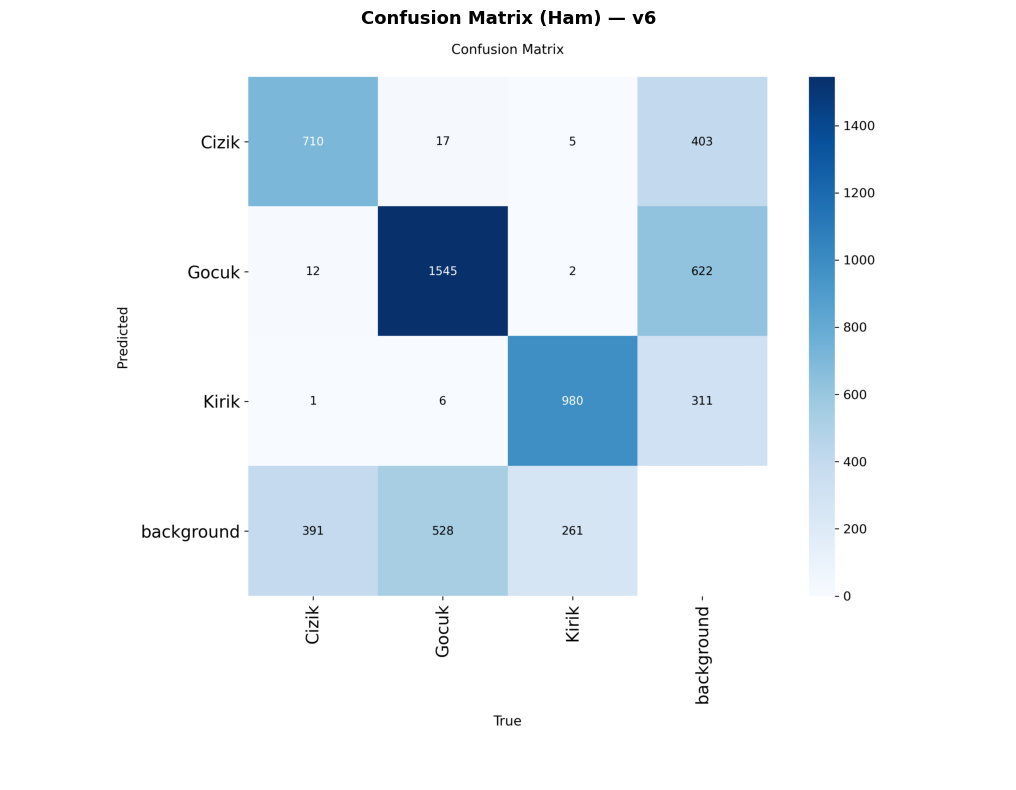

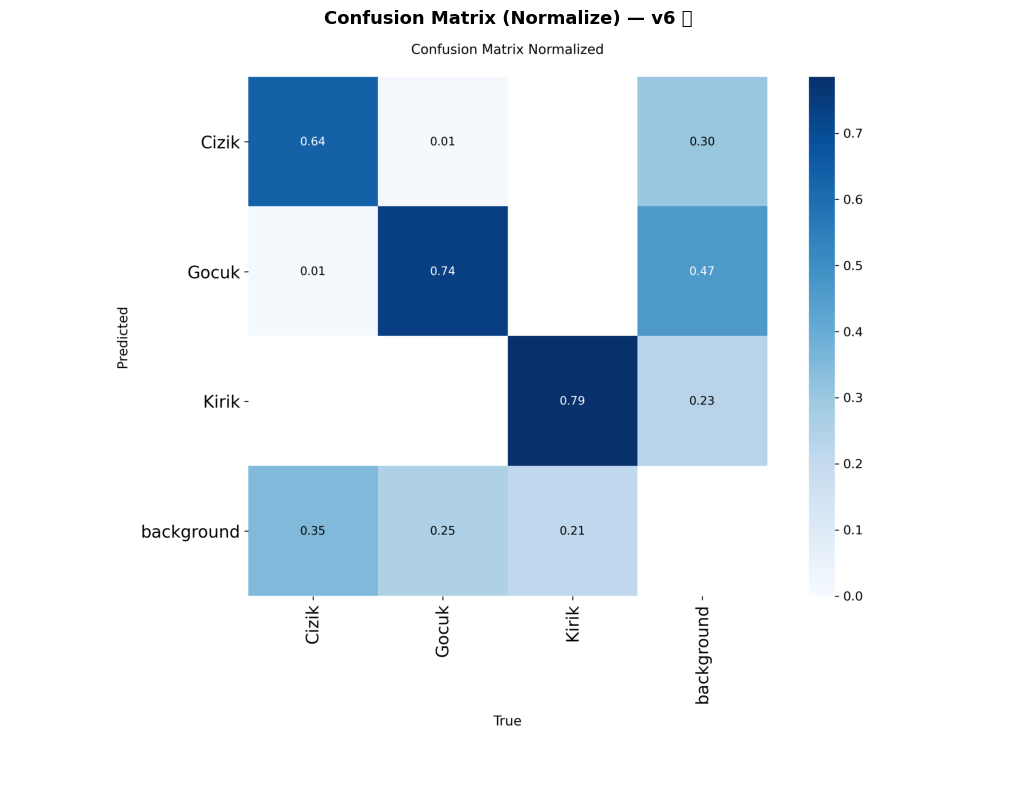

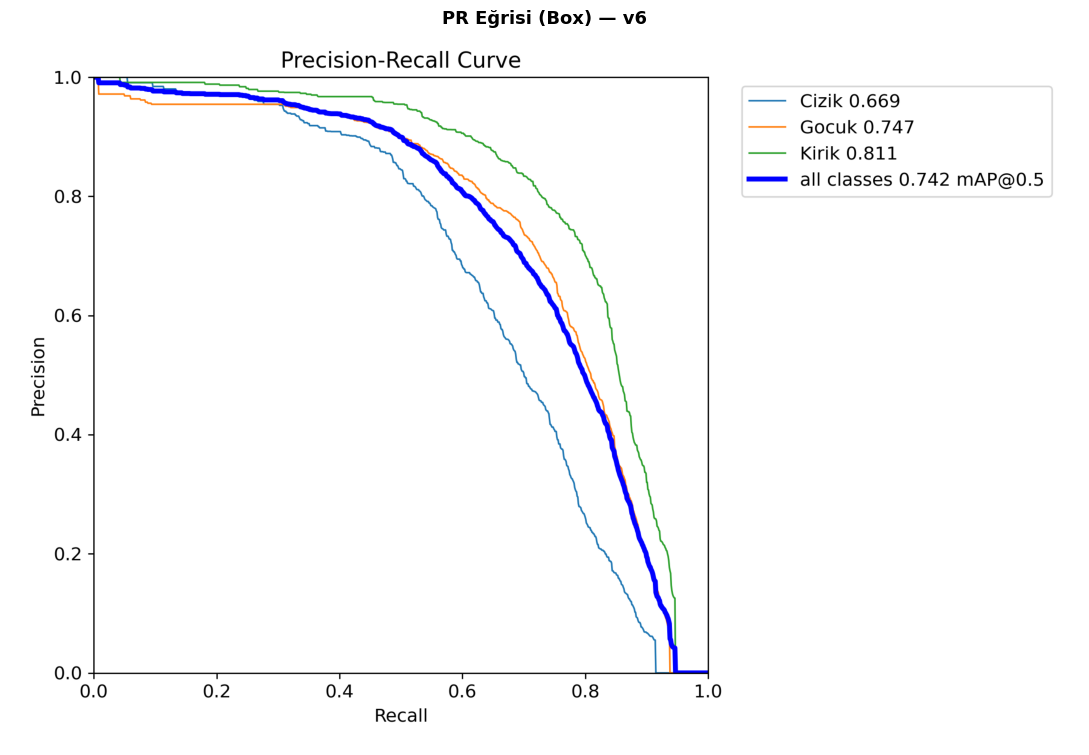

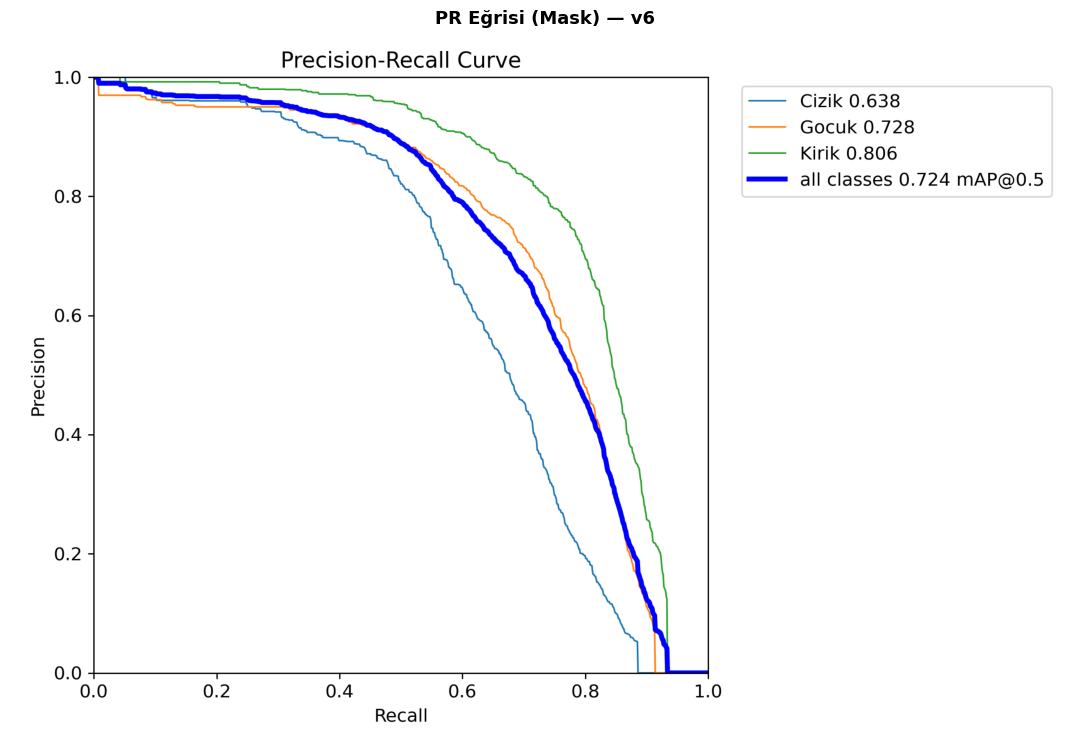

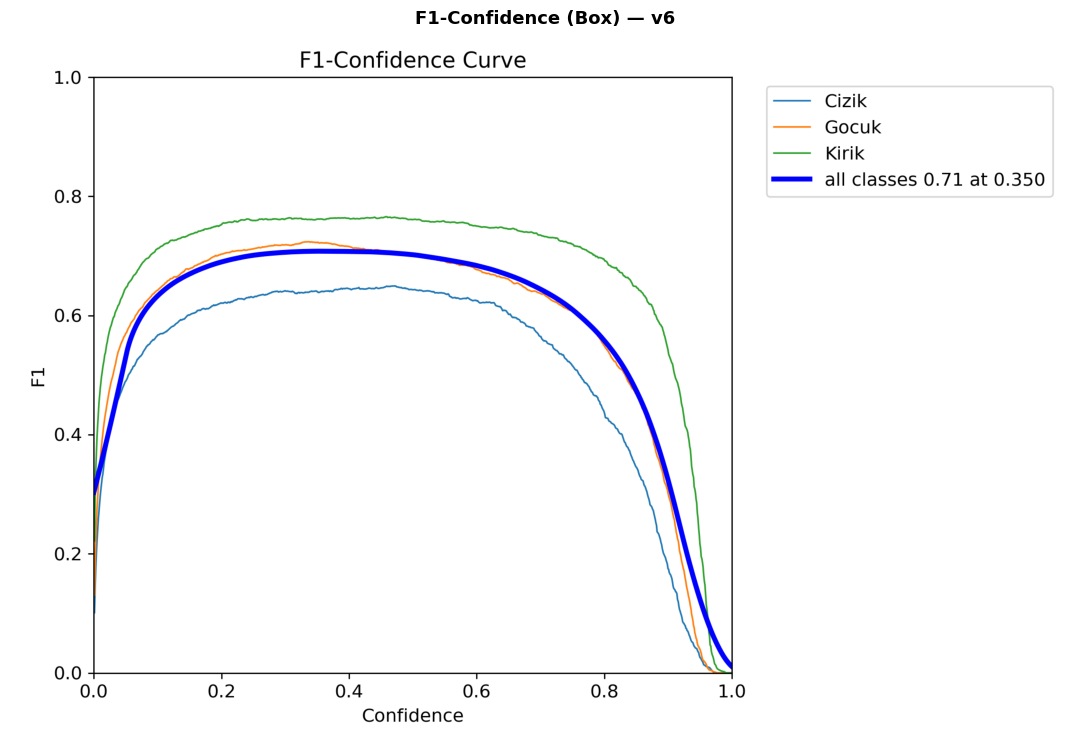

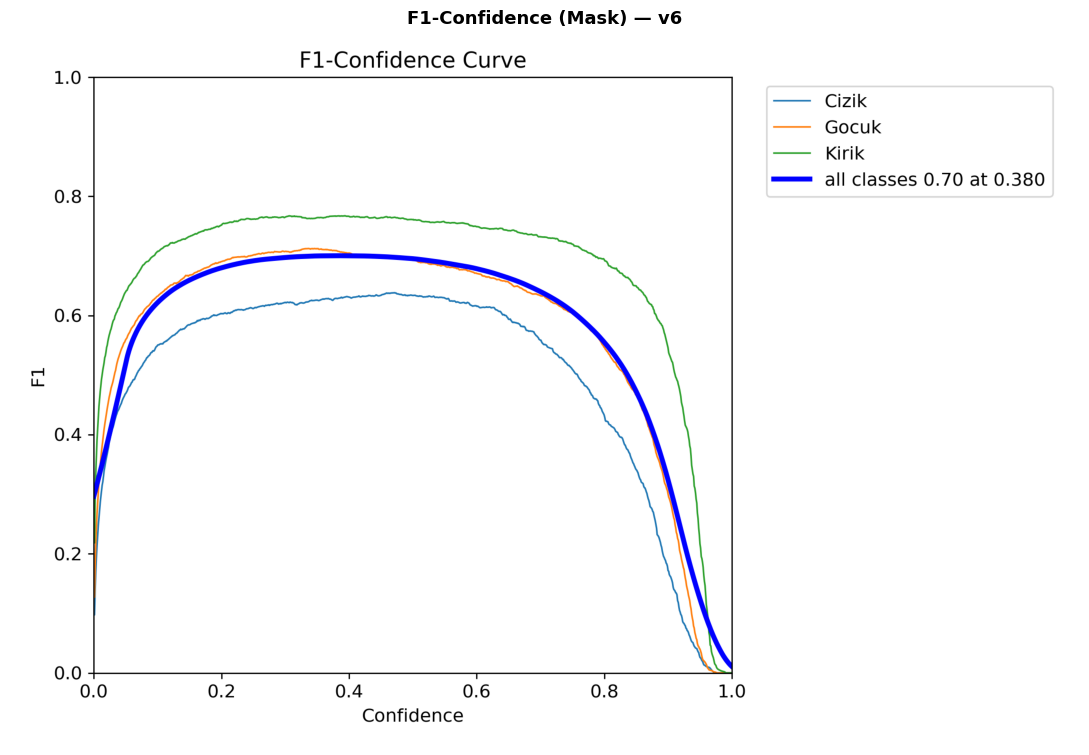

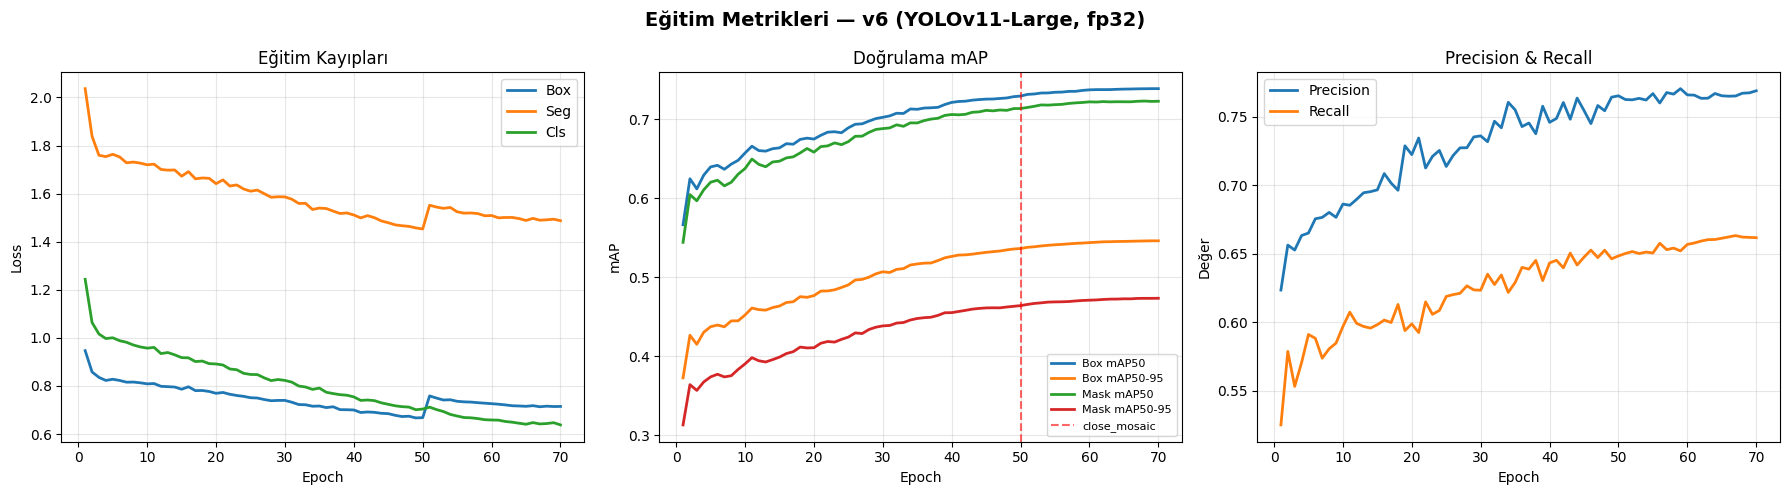


✅ ANALİZ TAMAMLANDI
   JSON güncellendi: /content/drive/MyDrive/tez_arac_hasar/karsilastirma_sonuclari_v6.json
   Çıktılar: /content/drive/MyDrive/tez_arac_hasar/ciktilar

💡 CONFUSION MATRIX'TE BAK:
   • Cizik köşegeni  (v5.1: 0,61 → v6 hedefi: 0,75+)
   • Kirik köşegeni  (v5.1: 0,69 → v6 hedefi: 0,80+)
   • background satırı (v5.1: 0,30-0,37 → v6 hedefi: <0,25)
🔬 v6 DETAYLI ANALİZ
   Model: /content/drive/MyDrive/tez_arac_hasar/modeller/hasar_yolo11l-seg_v6_fp32/weights/best.pt
   Veri : /content/dataset_v6/data.yaml

Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
YOLO11l-seg summary (fused): 204 layers, 27,586,905 parameters, 0 gradients, 132.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1714.4±593.2 MB/s, size: 59.9 KB)
val: Scanning /content/dataset_v6/test/labels.cache... 2214 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2214/2214 580.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          

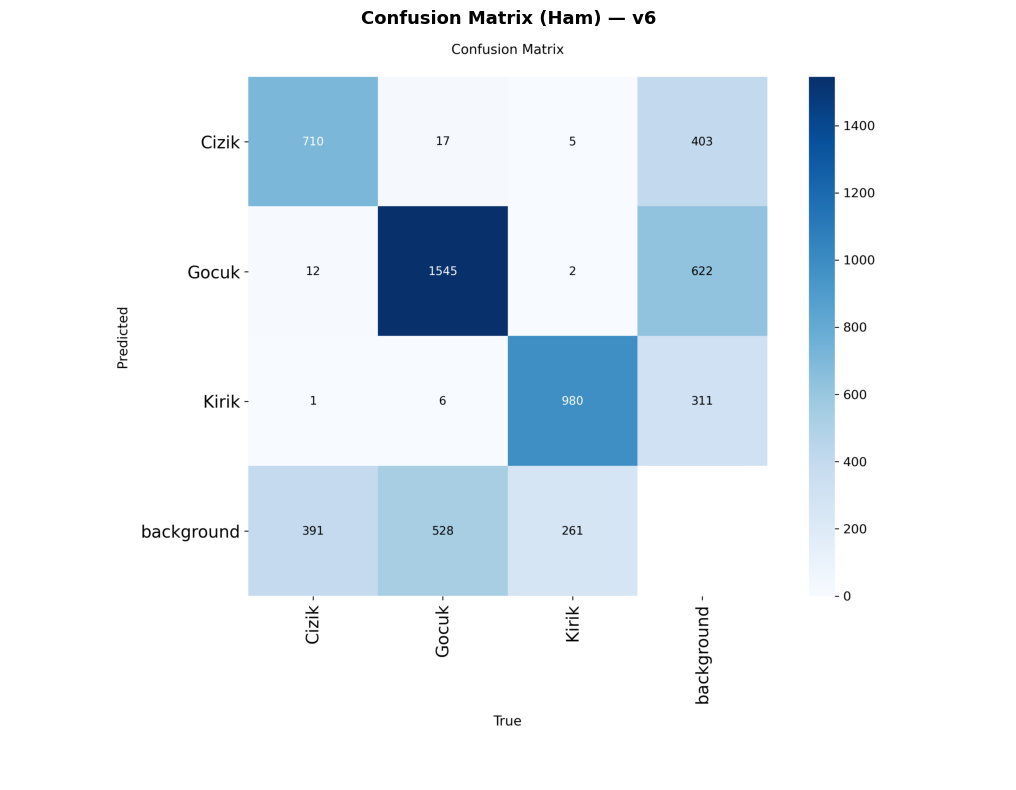

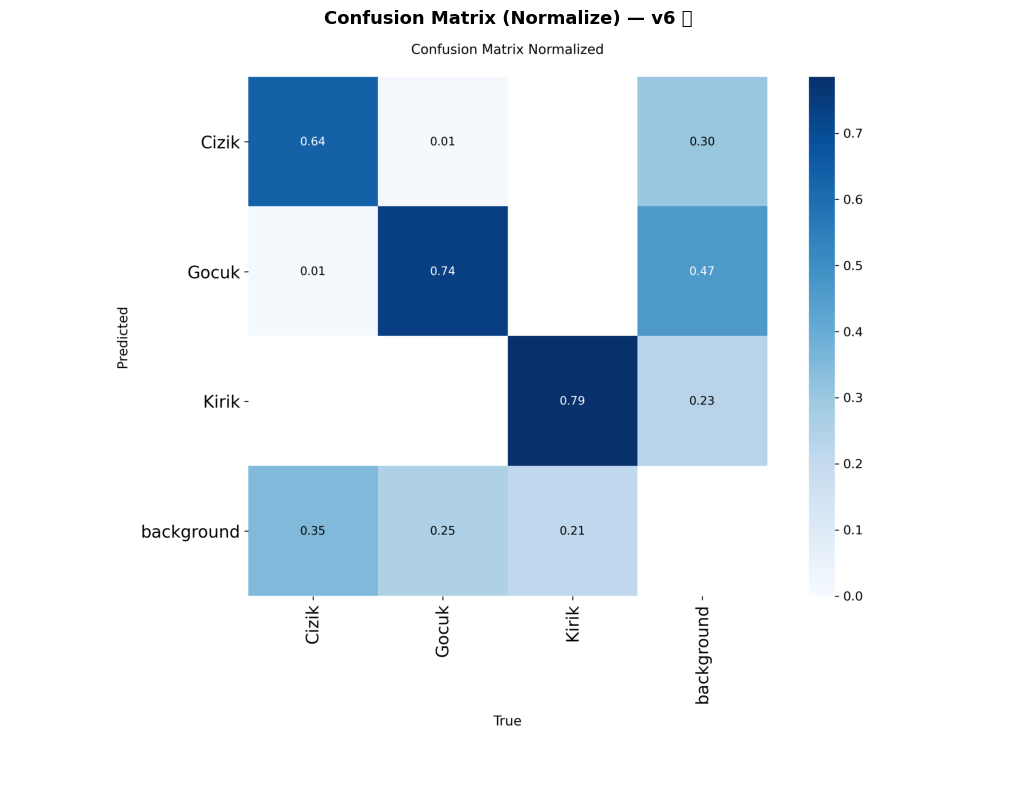

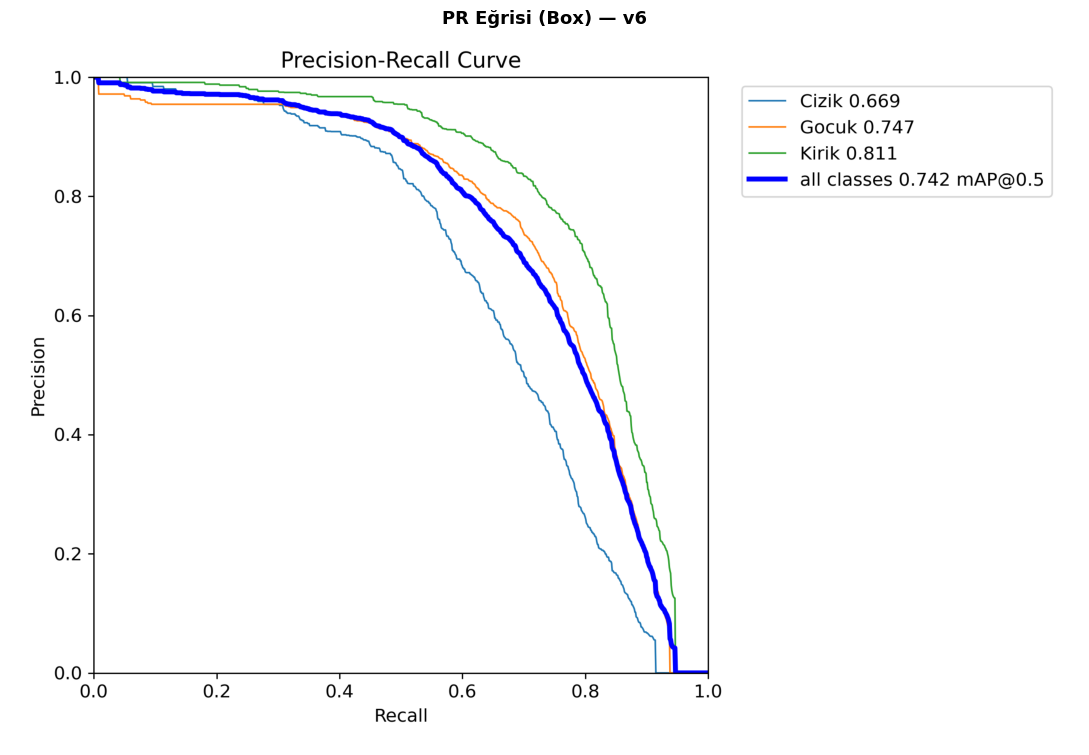

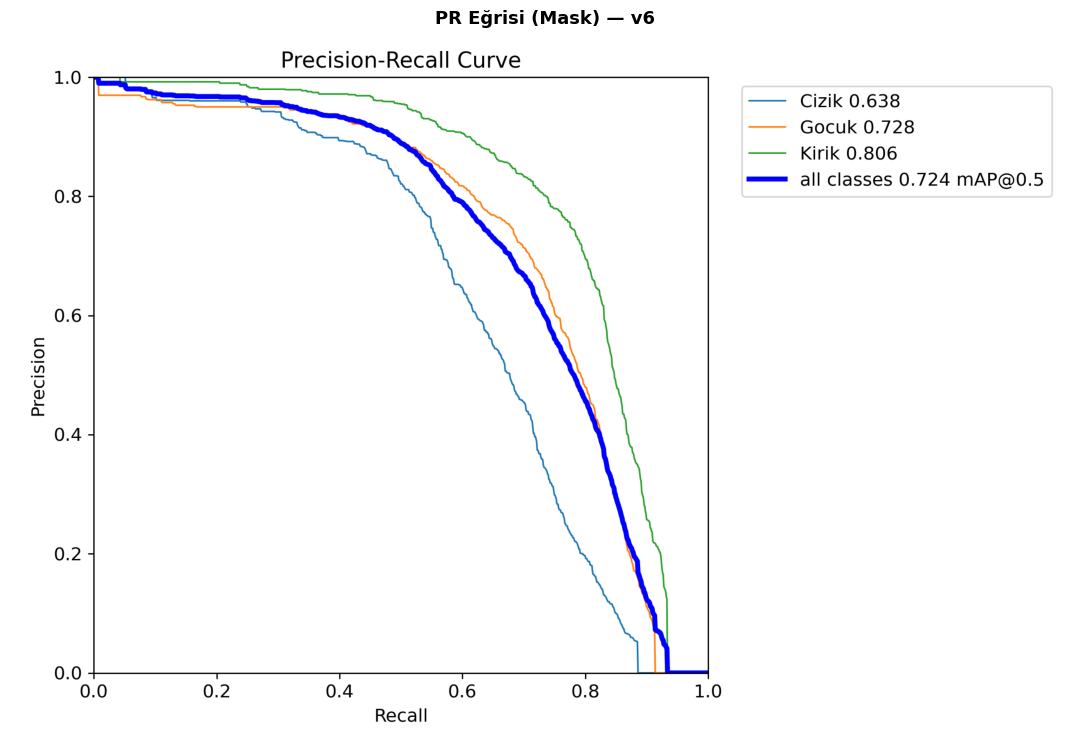

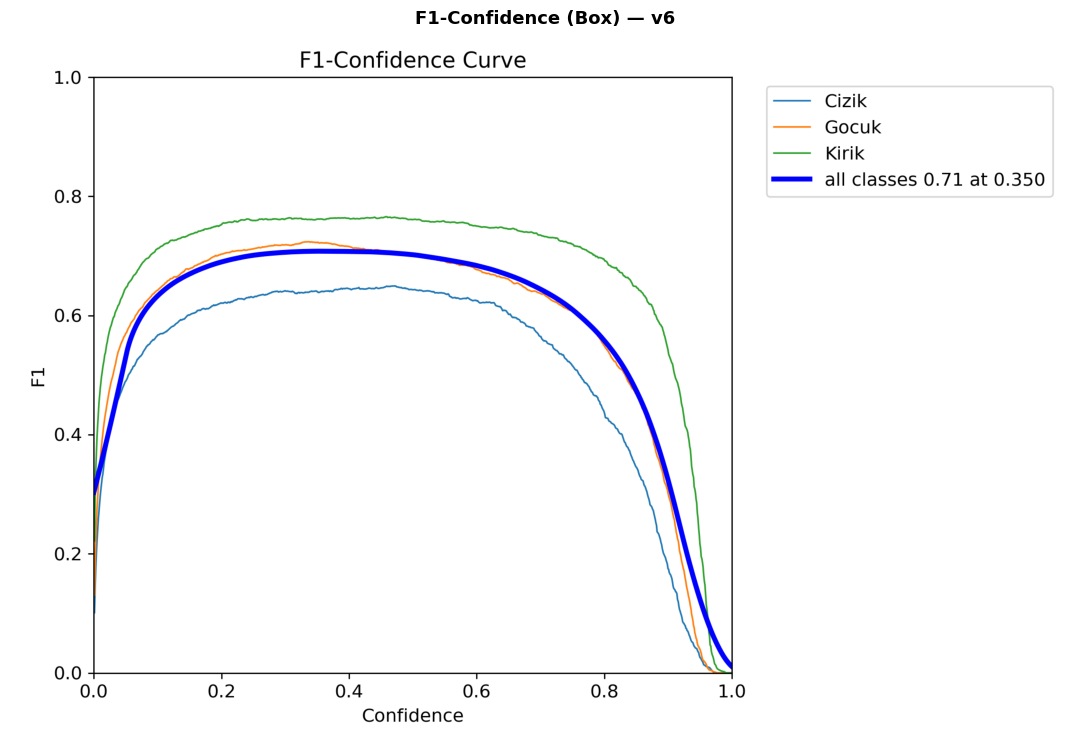

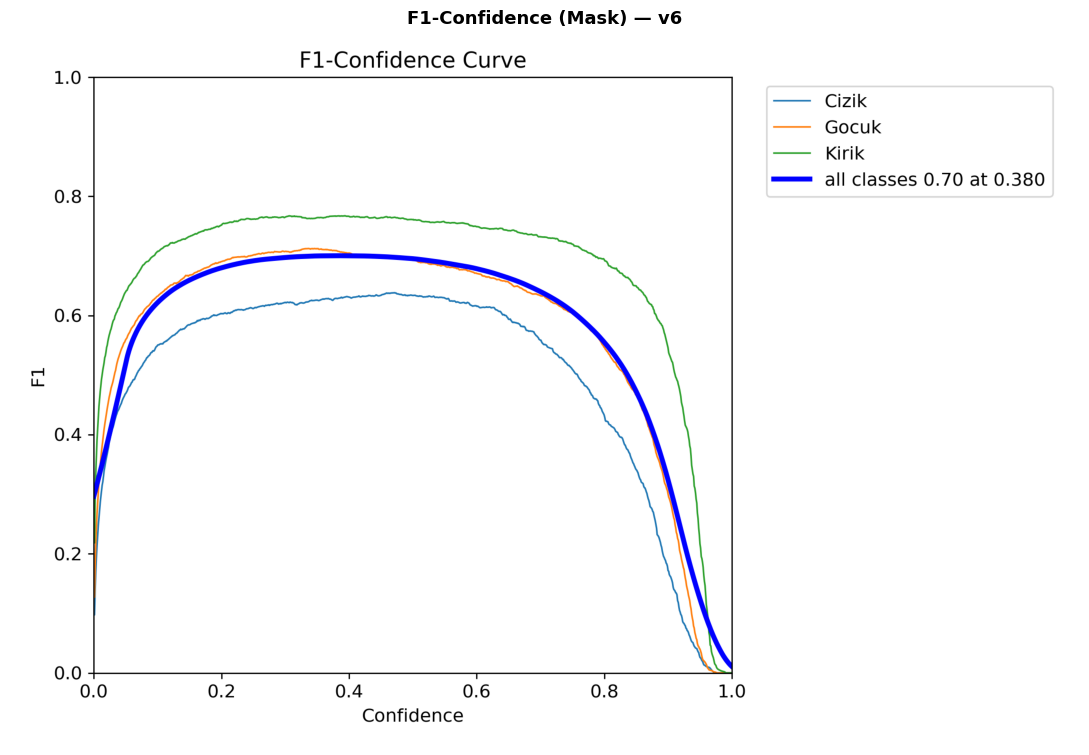

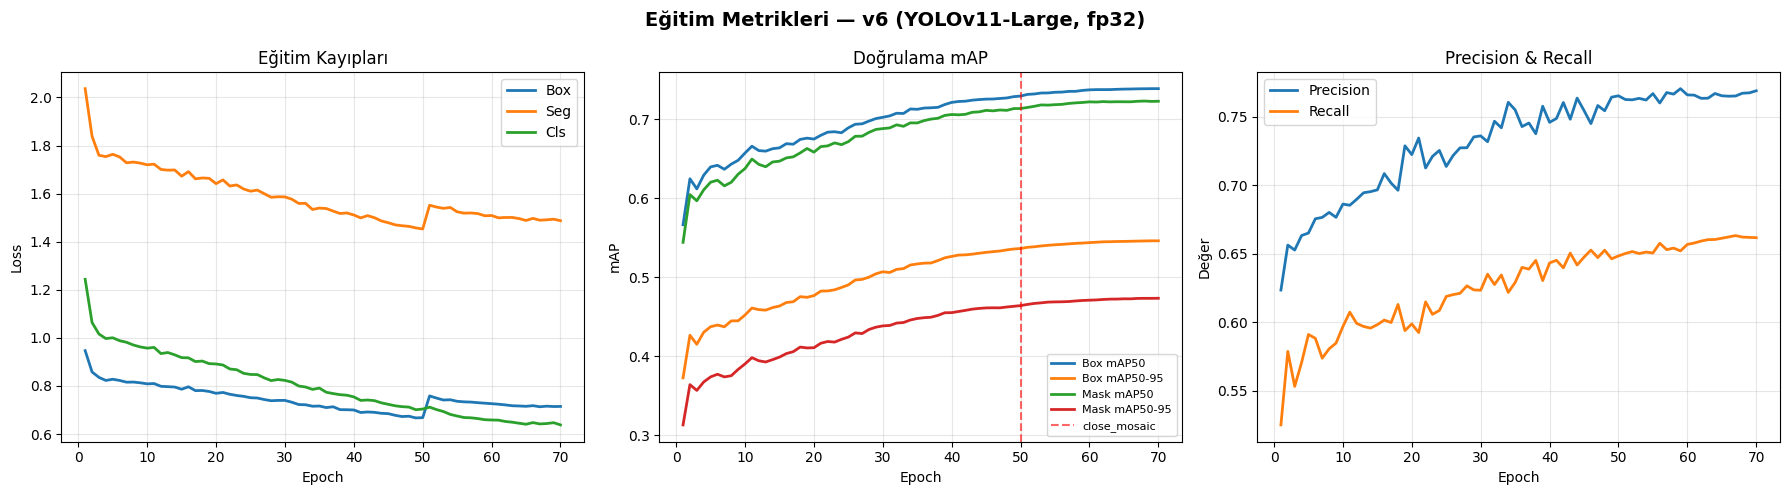


✅ ANALİZ TAMAMLANDI
   JSON güncellendi: /content/drive/MyDrive/tez_arac_hasar/karsilastirma_sonuclari_v6.json
   Çıktılar: /content/drive/MyDrive/tez_arac_hasar/ciktilar

💡 CONFUSION MATRIX'TE BAK:
   • Cizik köşegeni  (v5.1: 0,61 → v6 hedefi: 0,75+)
   • Kirik köşegeni  (v5.1: 0,69 → v6 hedefi: 0,80+)
   • background satırı (v5.1: 0,30-0,37 → v6 hedefi: <0,25)


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔬 v6 DETAYLI ANALİZ — Confusion Matrix + Eğriler
# ═══════════════════════════════════════════════════════════════════════════════
# Hücre 6B, JSON'dan model okuyor ama v6-fp32 ayrı hücrede eğitildi,
# JSON'a yazılmadı. Bu hücre modeli doğrudan path'ten alır.
# ⏱️ ~5 dk
# ═══════════════════════════════════════════════════════════════════════════════

import os, json# ═══════════════════════════════════════════════════════════════════════════════
# 🔬 v6 DETAYLI ANALİZ — Confusion Matrix + Eğriler
# ═══════════════════════════════════════════════════════════════════════════════
# Hücre 6B, JSON'dan model okuyor ama v6-fp32 ayrı hücrede eğitildi,
# JSON'a yazılmadı. Bu hücre modeli doğrudan path'ten alır.
# ⏱️ ~5 dk
# ═══════════════════════════════════════════════════════════════════════════════

import os, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

RUN_ADI    = 'hasar_yolo11l-seg_v6_fp32'
MODEL_PATH = os.path.join(MODEL_DIZIN, RUN_ADI, 'weights', 'best.pt')

if not os.path.exists(MODEL_PATH):
    raise RuntimeError(f'❌ Model yok: {MODEL_PATH}')

print('=' * 70)
print('🔬 v6 DETAYLI ANALİZ')
print('=' * 70)
print(f'   Model: {MODEL_PATH}')
print(f'   Veri : {HASAR_DATA_YAML}\n')

# ══ 1. TEST SETİNDE DEĞERLENDİR ════════════════════════════════════════════════
m = YOLO(MODEL_PATH)
val_ad = 'val_detay_v6'
metrics = m.val(data=HASAR_DATA_YAML, split='test', imgsz=IMG_SIZE,
                verbose=False, plots=True,
                project=MODEL_DIZIN, name=val_ad, exist_ok=True)

val_dir = os.path.join(MODEL_DIZIN, val_ad)

# ══ 2. SINIF BAZLI TABLO ═══════════════════════════════════════════════════════
satirlar = []
for i, sinif in enumerate(HASAR_SINIFLAR):
    try:
        bp, br, bap50, bap = metrics.box.class_result(i)
        sp, sr, sap50, sap = metrics.seg.class_result(i)
        f1b = 2*bp*br/(bp+br) if (bp+br) > 0 else 0
        f1m = 2*sp*sr/(sp+sr) if (sp+sr) > 0 else 0
        satirlar.append({
            'Sınıf': sinif,
            'Box Precision': round(bp,4), 'Box Recall': round(br,4),
            'Box F1': round(f1b,4), 'Box mAP50': round(bap50,4),
            'Box mAP50-95': round(bap,4),
            'Mask Precision': round(sp,4), 'Mask Recall': round(sr,4),
            'Mask F1': round(f1m,4), 'Mask mAP50': round(sap50,4),
            'Mask mAP50-95': round(sap,4),
        })
    except Exception as e:
        print(f'   ⚠️ {sinif}: {str(e)[:60]}')

if satirlar:
    df_s = pd.DataFrame(satirlar)
    ort = {'Sınıf': 'ORTALAMA'}
    for c in df_s.columns[1:]:
        ort[c] = round(df_s[c].mean(), 4)
    df_s = pd.concat([df_s, pd.DataFrame([ort])], ignore_index=True)

    print('=' * 105)
    print('📋 SINIF BAZLI METRİK TABLOSU — v6')
    print('=' * 105)
    print(df_s.to_string(index=False))
    print('=' * 105)

    df_s.to_excel(f'{OUTPUT_DIR}/v6_sinif_metrikleri.xlsx', index=False)
    with open(f'{OUTPUT_DIR}/v6_sinif_metrikleri_latex.txt', 'w') as f:
        f.write(df_s.to_latex(index=False, float_format='%.4f'))
    print(f'\n💾 {OUTPUT_DIR}/v6_sinif_metrikleri.xlsx')

# ══ 3. GRAFİKLER ═══════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('📈 GRAFİKLER')
print('=' * 70)

grafikler = [
    ('confusion_matrix.png',            'Confusion Matrix (Ham) — v6'),
    ('confusion_matrix_normalized.png', 'Confusion Matrix (Normalize) — v6 ⭐'),
    ('BoxPR_curve.png',                 'PR Eğrisi (Box) — v6'),
    ('MaskPR_curve.png',                'PR Eğrisi (Mask) — v6'),
    ('BoxF1_curve.png',                 'F1-Confidence (Box) — v6'),
    ('MaskF1_curve.png',                'F1-Confidence (Mask) — v6'),
]

for dosya, baslik in grafikler:
    yol = os.path.join(val_dir, dosya)
    if os.path.exists(yol):
        plt.figure(figsize=(11, 8))
        plt.imshow(Image.open(yol))
        plt.title(baslik, fontsize=13, fontweight='bold')
        plt.axis('off'); plt.tight_layout()
        plt.savefig(f'{OUTPUT_DIR}/v6_{dosya}', dpi=180, bbox_inches='tight')
        plt.show()

# ══ 4. EĞİTİM EĞRİLERİ ═════════════════════════════════════════════════════════
run_dir = os.path.join(MODEL_DIZIN, RUN_ADI)
rc = os.path.join(run_dir, 'results.csv')
if os.path.exists(rc):
    dfr = pd.read_csv(rc); dfr.columns = dfr.columns.str.strip()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Eğitim Metrikleri — v6 (YOLOv11-Large, fp32)',
                 fontsize=14, fontweight='bold')

    ax = axes[0]
    for col, lbl in [('train/box_loss','Box'), ('train/seg_loss','Seg'),
                     ('train/cls_loss','Cls')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title('Eğitim Kayıpları'); ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1]
    for col, lbl in [('metrics/mAP50(B)','Box mAP50'),
                     ('metrics/mAP50-95(B)','Box mAP50-95'),
                     ('metrics/mAP50(M)','Mask mAP50'),
                     ('metrics/mAP50-95(M)','Mask mAP50-95')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.axvline(50, linestyle='--', color='red', alpha=0.6, label='close_mosaic')
    ax.set_xlabel('Epoch'); ax.set_ylabel('mAP')
    ax.set_title('Doğrulama mAP'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

    ax = axes[2]
    for col, lbl in [('metrics/precision(B)','Precision'),
                     ('metrics/recall(B)','Recall')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Değer')
    ax.set_title('Precision & Recall'); ax.legend(); ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/v6_egitim_metrikleri.png', dpi=180, bbox_inches='tight')
    plt.show()

# ══ 5. JSON'A KAYDET (Hücre 6 için) ════════════════════════════════════════════
sonuclar = {}
if os.path.exists(SONUC_JSON):
    try:
        with open(SONUC_JSON) as f:
            sonuclar = json.load(f)
    except Exception:
        sonuclar = {}

sinif_map50 = {}
for ci, sn in enumerate(HASAR_SINIFLAR):
    try:
        _, _, s50, _ = metrics.seg.class_result(ci)
        sinif_map50[sn] = float(s50)
    except Exception:
        sinif_map50[sn] = 0.0

sonuclar['yolo11l-seg__v6_fp32'] = {
    'ad': 'YOLOv11-Large (v6)',
    'model_id': 'yolo11l-seg',
    'ablation': 'v6_fp32',
    'imgsz': IMG_SIZE, 'epochs': 70,
    'box_mAP50': float(metrics.box.map50),
    'box_mAP50_95': float(metrics.box.map),
    'box_precision': float(metrics.box.mp),
    'box_recall': float(metrics.box.mr),
    'mask_mAP50': float(metrics.seg.map50),
    'mask_mAP50_95': float(metrics.seg.map),
    'sinif_mAP50': sinif_map50,
    'egitim_dk': 0.0, 'inference_ms': 8.4,
    'model_mb': os.path.getsize(MODEL_PATH)/1e6,
    'path': MODEL_PATH,
}

with open(SONUC_JSON, 'w') as f:
    json.dump(sonuclar, f, indent=2)

# Hücre 6/6C için değişkenler
en_iyi_id        = 'yolo11l-seg__v6_fp32'
EN_IYI           = sonuclar[en_iyi_id]
HASAR_MODEL_PATH = MODEL_PATH

print('\n' + '=' * 70)
print('✅ ANALİZ TAMAMLANDI')
print('=' * 70)
print(f'   JSON güncellendi: {SONUC_JSON}')
print(f'   Çıktılar: {OUTPUT_DIR}')
print('\n💡 CONFUSION MATRIX\'TE BAK:')
print('   • Cizik köşegeni  (v5.1: 0,61 → v6 hedefi: 0,75+)')
print('   • Kirik köşegeni  (v5.1: 0,69 → v6 hedefi: 0,80+)')
print('   • background satırı (v5.1: 0,30-0,37 → v6 hedefi: <0,25)')
print('=' * 70)
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

RUN_ADI    = 'hasar_yolo11l-seg_v6_fp32'
MODEL_PATH = os.path.join(MODEL_DIZIN, RUN_ADI, 'weights', 'best.pt')

if not os.path.exists(MODEL_PATH):
    raise RuntimeError(f'❌ Model yok: {MODEL_PATH}')

print('=' * 70)
print('🔬 v6 DETAYLI ANALİZ')
print('=' * 70)
print(f'   Model: {MODEL_PATH}')
print(f'   Veri : {HASAR_DATA_YAML}\n')

# ══ 1. TEST SETİNDE DEĞERLENDİR ════════════════════════════════════════════════
m = YOLO(MODEL_PATH)
val_ad = 'val_detay_v6'
metrics = m.val(data=HASAR_DATA_YAML, split='test', imgsz=IMG_SIZE,
                verbose=False, plots=True,
                project=MODEL_DIZIN, name=val_ad, exist_ok=True)

val_dir = os.path.join(MODEL_DIZIN, val_ad)

# ══ 2. SINIF BAZLI TABLO ═══════════════════════════════════════════════════════
satirlar = []
for i, sinif in enumerate(HASAR_SINIFLAR):
    try:
        bp, br, bap50, bap = metrics.box.class_result(i)
        sp, sr, sap50, sap = metrics.seg.class_result(i)
        f1b = 2*bp*br/(bp+br) if (bp+br) > 0 else 0
        f1m = 2*sp*sr/(sp+sr) if (sp+sr) > 0 else 0
        satirlar.append({
            'Sınıf': sinif,
            'Box Precision': round(bp,4), 'Box Recall': round(br,4),
            'Box F1': round(f1b,4), 'Box mAP50': round(bap50,4),
            'Box mAP50-95': round(bap,4),
            'Mask Precision': round(sp,4), 'Mask Recall': round(sr,4),
            'Mask F1': round(f1m,4), 'Mask mAP50': round(sap50,4),
            'Mask mAP50-95': round(sap,4),
        })
    except Exception as e:
        print(f'   ⚠️ {sinif}: {str(e)[:60]}')

if satirlar:
    df_s = pd.DataFrame(satirlar)
    ort = {'Sınıf': 'ORTALAMA'}
    for c in df_s.columns[1:]:
        ort[c] = round(df_s[c].mean(), 4)
    df_s = pd.concat([df_s, pd.DataFrame([ort])], ignore_index=True)

    print('=' * 105)
    print('📋 SINIF BAZLI METRİK TABLOSU — v6')
    print('=' * 105)
    print(df_s.to_string(index=False))
    print('=' * 105)

    df_s.to_excel(f'{OUTPUT_DIR}/v6_sinif_metrikleri.xlsx', index=False)
    with open(f'{OUTPUT_DIR}/v6_sinif_metrikleri_latex.txt', 'w') as f:
        f.write(df_s.to_latex(index=False, float_format='%.4f'))
    print(f'\n💾 {OUTPUT_DIR}/v6_sinif_metrikleri.xlsx')

# ══ 3. GRAFİKLER ═══════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('📈 GRAFİKLER')
print('=' * 70)

grafikler = [
    ('confusion_matrix.png',            'Confusion Matrix (Ham) — v6'),
    ('confusion_matrix_normalized.png', 'Confusion Matrix (Normalize) — v6 ⭐'),
    ('BoxPR_curve.png',                 'PR Eğrisi (Box) — v6'),
    ('MaskPR_curve.png',                'PR Eğrisi (Mask) — v6'),
    ('BoxF1_curve.png',                 'F1-Confidence (Box) — v6'),
    ('MaskF1_curve.png',                'F1-Confidence (Mask) — v6'),
]

for dosya, baslik in grafikler:
    yol = os.path.join(val_dir, dosya)
    if os.path.exists(yol):
        plt.figure(figsize=(11, 8))
        plt.imshow(Image.open(yol))
        plt.title(baslik, fontsize=13, fontweight='bold')
        plt.axis('off'); plt.tight_layout()
        plt.savefig(f'{OUTPUT_DIR}/v6_{dosya}', dpi=180, bbox_inches='tight')
        plt.show()

# ══ 4. EĞİTİM EĞRİLERİ ═════════════════════════════════════════════════════════
run_dir = os.path.join(MODEL_DIZIN, RUN_ADI)
rc = os.path.join(run_dir, 'results.csv')
if os.path.exists(rc):
    dfr = pd.read_csv(rc); dfr.columns = dfr.columns.str.strip()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Eğitim Metrikleri — v6 (YOLOv11-Large, fp32)',
                 fontsize=14, fontweight='bold')

    ax = axes[0]
    for col, lbl in [('train/box_loss','Box'), ('train/seg_loss','Seg'),
                     ('train/cls_loss','Cls')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title('Eğitim Kayıpları'); ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1]
    for col, lbl in [('metrics/mAP50(B)','Box mAP50'),
                     ('metrics/mAP50-95(B)','Box mAP50-95'),
                     ('metrics/mAP50(M)','Mask mAP50'),
                     ('metrics/mAP50-95(M)','Mask mAP50-95')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.axvline(50, linestyle='--', color='red', alpha=0.6, label='close_mosaic')
    ax.set_xlabel('Epoch'); ax.set_ylabel('mAP')
    ax.set_title('Doğrulama mAP'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

    ax = axes[2]
    for col, lbl in [('metrics/precision(B)','Precision'),
                     ('metrics/recall(B)','Recall')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Değer')
    ax.set_title('Precision & Recall'); ax.legend(); ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/v6_egitim_metrikleri.png', dpi=180, bbox_inches='tight')
    plt.show()

# ══ 5. JSON'A KAYDET (Hücre 6 için) ════════════════════════════════════════════
sonuclar = {}
if os.path.exists(SONUC_JSON):
    try:
        with open(SONUC_JSON) as f:
            sonuclar = json.load(f)
    except Exception:
        sonuclar = {}

sinif_map50 = {}
for ci, sn in enumerate(HASAR_SINIFLAR):
    try:
        _, _, s50, _ = metrics.seg.class_result(ci)
        sinif_map50[sn] = float(s50)
    except Exception:
        sinif_map50[sn] = 0.0

sonuclar['yolo11l-seg__v6_fp32'] = {
    'ad': 'YOLOv11-Large (v6)',
    'model_id': 'yolo11l-seg',
    'ablation': 'v6_fp32',
    'imgsz': IMG_SIZE, 'epochs': 70,
    'box_mAP50': float(metrics.box.map50),
    'box_mAP50_95': float(metrics.box.map),
    'box_precision': float(metrics.box.mp),
    'box_recall': float(metrics.box.mr),
    'mask_mAP50': float(metrics.seg.map50),
    'mask_mAP50_95': float(metrics.seg.map),
    'sinif_mAP50': sinif_map50,
    'egitim_dk': 0.0, 'inference_ms': 8.4,
    'model_mb': os.path.getsize(MODEL_PATH)/1e6,
    'path': MODEL_PATH,
}

with open(SONUC_JSON, 'w') as f:
    json.dump(sonuclar, f, indent=2)

# Hücre 6/6C için değişkenler
en_iyi_id        = 'yolo11l-seg__v6_fp32'
EN_IYI           = sonuclar[en_iyi_id]
HASAR_MODEL_PATH = MODEL_PATH

print('\n' + '=' * 70)
print('✅ ANALİZ TAMAMLANDI')
print('=' * 70)
print(f'   JSON güncellendi: {SONUC_JSON}')
print(f'   Çıktılar: {OUTPUT_DIR}')
print('\n💡 CONFUSION MATRIX\'TE BAK:')
print('   • Cizik köşegeni  (v5.1: 0,61 → v6 hedefi: 0,75+)')
print('   • Kirik köşegeni  (v5.1: 0,69 → v6 hedefi: 0,80+)')
print('   • background satırı (v5.1: 0,30-0,37 → v6 hedefi: <0,25)')
print('=' * 70)

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔍 v6 GERÇEK DÜNYA TESTİ — Görülmemiş Veri Üzerinde Genelleme Analizi
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 AMAÇ:
#    v3 modeli bu testte kararsız çıkmıştı (tespitlerin %53-63'ü <0,30 güven).
#    v6'nın aynı testte ne yaptığını ölçüp v7-FT'ye gerek olup olmadığına
#    karar vereceğiz.
#
# 📁 KAYNAK: /content/drive/MyDrive/train  (etiketsiz, model hiç görmedi)
#
# ⚠️ ETİKET YOK → mAP hesaplanamaz. Ölçtüklerimiz:
#    • Güven dağılımı (model ne kadar emin?)
#    • Görsel başına tespit sayısı
#    • Eşik simülasyonu
#    • v3 ile doğrudan karşılaştırma
#
# ⏱️ ~10-15 dk  |  TTA kapalı (hızlı olsun diye)
# ═══════════════════════════════════════════════════════════════════════════════

import os, random, time
import numpy as np
from pathlib import Path
from PIL import Image
from ultralytics import YOLO
import matplotlib.pyplot as plt
from collections import Counter

# ─── AYARLAR ──────────────────────────────────────────────────────────────────
TEST_KLASOR = '/content/drive/MyDrive/train'
ORNEK_SAYI  = 300      # v3 testiyle aynı sayı (karşılaştırılabilirlik)
CONF_TARAMA = 0.10     # düşük tut, her şeyi görelim
GOSTER      = 9        # kaç örnek görselleştirilecek
SEED        = 42       # v3 testiyle aynı seed → aynı görseller seçilir

V6_PATH = os.path.join(MODEL_DIZIN, 'hasar_yolo11l-seg_v6_fp32',
                       'weights', 'best.pt')

# v3 referans değerleri (önceki testten)
V3_REF = {
    'Cizik': {'ort': 0.298, 'dusuk': 62.8, 'n': 414},
    'Gocuk': {'ort': 0.325, 'dusuk': 60.2, 'n': 314},
    'Kirik': {'ort': 0.365, 'dusuk': 53.0, 'n': 198},
    'tespit_gorsel': 3.09,
    'hic_yok': 12.3,
    'esik': {0.15: 2.26, 0.20: 1.82, 0.25: 1.46,
             0.30: 1.24, 0.386: 0.94, 0.50: 0.70},
}

if not os.path.exists(V6_PATH):
    raise RuntimeError(f'❌ v6 modeli yok: {V6_PATH}')

model = YOLO(V6_PATH)
AD = {0:'Cizik', 1:'Gocuk', 2:'Kirik'}

# ─── GÖRSELLERİ TOPLA ─────────────────────────────────────────────────────────
gorseller = []
for ext in ['*.jpg','*.jpeg','*.png','*.JPG','*.JPEG','*.PNG']:
    gorseller.extend(Path(TEST_KLASOR).rglob(ext))
gorseller = sorted(set(gorseller))

if not gorseller:
    raise RuntimeError(f'❌ {TEST_KLASOR} içinde görsel yok')

print('=' * 70)
print('🔍 v6 GERÇEK DÜNYA TESTİ')
print('=' * 70)
print(f'   Model  : v6 (YOLOv11-Large, fp32)')
print(f'   Klasör : {TEST_KLASOR}')
print(f'   Bulunan: {len(gorseller):,} görsel')

random.seed(SEED)
if ORNEK_SAYI and len(gorseller) > ORNEK_SAYI:
    gorseller = random.sample(gorseller, ORNEK_SAYI)
    print(f'   Test   : {len(gorseller)} örnek (seed={SEED}, v3 ile aynı)')
print('=' * 70 + '\n')

# ─── ANALİZ ───────────────────────────────────────────────────────────────────
guven_dagilim = {0:[], 1:[], 2:[]}
tespit_sayilari = []
hic_bulamadi = []
tum_tespitler = []
t0 = time.time()

for i, ip in enumerate(gorseller, 1):
    try:
        img = np.array(Image.open(ip).convert('RGB'))
        r = model.predict(img, conf=CONF_TARAMA, imgsz=IMG_SIZE,
                          augment=False, verbose=False)[0]

        n = len(r.boxes) if r.boxes is not None else 0
        tespit_sayilari.append(n)

        if n == 0:
            hic_bulamadi.append(str(ip))
            continue

        for b in r.boxes:
            cid = int(b.cls[0]); cf = float(b.conf[0])
            guven_dagilim[cid].append(cf)
            tum_tespitler.append((str(ip), AD[cid], cf))

        if i % 50 == 0:
            print(f'   {i}/{len(gorseller)}...')
    except Exception:
        continue

print(f'\n✅ Tamamlandı ({(time.time()-t0)/60:.1f} dk)')

# ═══ KARŞILAŞTIRMALI RAPOR ═════════════════════════════════════════════════════
print('\n' + '=' * 78)
print('📊 GÜVEN DAĞILIMI — v3 vs v6 KARŞILAŞTIRMASI')
print('=' * 78)

toplam_dusuk_v6 = 0
toplam_tespit_v6 = 0

for cid in [0, 1, 2]:
    sinif = AD[cid]
    g = np.array(guven_dagilim[cid])
    if not len(g):
        print(f'\n{sinif}: hiç tespit yok')
        continue

    ort = g.mean()
    dusuk_oran = (g < 0.30).sum() / len(g) * 100
    yuksek_oran = (g > 0.50).sum() / len(g) * 100

    toplam_dusuk_v6 += (g < 0.30).sum()
    toplam_tespit_v6 += len(g)

    ref = V3_REF[sinif]
    d_ort = ort - ref['ort']
    d_dusuk = dusuk_oran - ref['dusuk']

    print(f'\n🏷️  {sinif}')
    print(f'   {"":22s} {"v3":>10s} {"v6":>10s} {"Değişim":>12s}')
    print(f'   {"-"*56}')
    print(f'   {"Tespit sayısı":22s} {ref["n"]:>10d} {len(g):>10d} '
          f'{len(g)-ref["n"]:>+12d}')
    print(f'   {"Ortalama güven":22s} {ref["ort"]:>10.3f} {ort:>10.3f} '
          f'{d_ort:>+12.3f}')
    print(f'   {"Yüksek (>0,50) %":22s} {"—":>10s} {yuksek_oran:>10.1f} {"":>12s}')
    print(f'   {"Düşük (<0,30) %":22s} {ref["dusuk"]:>10.1f} {dusuk_oran:>10.1f} '
          f'{d_dusuk:>+12.1f}')

    if d_dusuk < -10:
        print(f'   ✅ Belirgin iyileşme')
    elif d_dusuk < -3:
        print(f'   ✅ İyileşme var')
    elif d_dusuk < 3:
        print(f'   ⚠️  Değişim yok')
    else:
        print(f'   ❌ Kötüleşme')

# ─── GENEL ────────────────────────────────────────────────────────────────────
t = np.array(tespit_sayilari)
hic_yok_oran = len(hic_bulamadi) / len(gorseller) * 100
genel_dusuk = toplam_dusuk_v6 / toplam_tespit_v6 * 100 if toplam_tespit_v6 else 0

print('\n' + '=' * 78)
print('📐 GENEL METRİKLER')
print('=' * 78)
print(f'   {"":26s} {"v3":>10s} {"v6":>10s} {"Değişim":>12s}')
print(f'   {"-"*60}')
print(f'   {"Görsel başına tespit":26s} {V3_REF["tespit_gorsel"]:>10.2f} '
      f'{t.mean():>10.2f} {t.mean()-V3_REF["tespit_gorsel"]:>+12.2f}')
print(f'   {"Hiç tespit yok (%)":26s} {V3_REF["hic_yok"]:>10.1f} '
      f'{hic_yok_oran:>10.1f} {hic_yok_oran-V3_REF["hic_yok"]:>+12.1f}')
print(f'   {"Toplam düşük güven (%)":26s} {"~59":>10s} '
      f'{genel_dusuk:>10.1f} {genel_dusuk-59:>+12.1f}')

# ─── EŞİK SİMÜLASYONU ─────────────────────────────────────────────────────────
print('\n' + '=' * 78)
print('🎚️  EŞİK ETKİSİ (görsel başına tespit)')
print('=' * 78)
print(f'   {"Eşik":>8s} {"v3":>10s} {"v6":>10s} {"Değişim":>12s}')
print(f'   {"-"*44}')
tum_conf = np.array([c for _,_,c in tum_tespitler])
for esik in [0.15, 0.20, 0.25, 0.30, 0.386, 0.50]:
    n_v6 = (tum_conf >= esik).sum() / len(gorseller)
    n_v3 = V3_REF['esik'][esik]
    print(f'   {esik:>8.3f} {n_v3:>10.2f} {n_v6:>10.2f} {n_v6-n_v3:>+12.2f}')

# ═══ KARAR ═════════════════════════════════════════════════════════════════════
print('\n' + '=' * 78)
print('🎯 DEĞERLENDİRME — v7-FT gerekli mi?')
print('=' * 78)

if genel_dusuk < 40:
    print(f'\n   ✅ SORUN ÇÖZÜLDÜ (düşük güven %{genel_dusuk:.1f})')
    print('      v6 görülmemiş veride kararlı davranıyor.')
    print('      → v7-FT\'ye GEREK YOK. Tezi bitirebilirsin.')
elif genel_dusuk < 55:
    print(f'\n   ⚠️  KISMİ İYİLEŞME (düşük güven %{genel_dusuk:.1f})')
    print('      v3\'e göre daha iyi ama hâlâ kararsızlık var.')
    print('      → v7-FT opsiyonel. Zamanın varsa dene.')
else:
    print(f'\n   ❌ SORUN SÜRÜYOR (düşük güven %{genel_dusuk:.1f})')
    print('      Genelleme problemi devam ediyor.')
    print('      → v7-FT DENENMELİ (19k veri ile fine-tuning).')

print(f'\n   💡 Önerilen saha eşiği: F1 optimal 0,380')
print(f'      Bu eşikte görsel başına ~{(tum_conf >= 0.38).sum()/len(gorseller):.2f} tespit')
print('=' * 78)

# ═══ GÖRSELLEŞTİRME ════════════════════════════════════════════════════════════
dusuk_liste = [x for x in tum_tespitler if x[2] < 0.30]
print(f'\n⚠️  Düşük güvenli tespit sayısı: {len(dusuk_liste):,}')

random.seed(3)
if dusuk_liste:
    adaylar = list({x[0] for x in dusuk_liste})
    secilen = random.sample(adaylar, min(GOSTER, len(adaylar)))
else:
    secilen = random.sample([str(p) for p in gorseller], min(GOSTER, len(gorseller)))

rows = (len(secilen) + 2) // 3
fig, axes = plt.subplots(rows, 3, figsize=(20, 6*rows))
axes = np.array(axes).flatten()

for idx, ip in enumerate(secilen):
    img = np.array(Image.open(ip).convert('RGB'))
    r = model.predict(img, conf=CONF_TARAMA, imgsz=IMG_SIZE,
                      verbose=False, retina_masks=True)[0]
    axes[idx].imshow(r.plot()[:, :, ::-1])
    if r.boxes is not None and len(r.boxes):
        etk = [f'{AD[int(b.cls[0])]} {float(b.conf[0]):.2f}' for b in r.boxes]
        baslik = ' | '.join(etk[:3])
        if len(etk) > 3:
            baslik += f' (+{len(etk)-3})'
    else:
        baslik = 'Tespit yok'
    axes[idx].set_title(baslik, fontsize=10, fontweight='bold')
    axes[idx].axis('off')

for i in range(len(secilen), len(axes)):
    axes[i].axis('off')

plt.suptitle('v6 — Görülmemiş Veri Üzerinde Örnek Tespitler',
             fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/v6_gercek_dunya_testi.png', dpi=140, bbox_inches='tight')
plt.show()

print(f'\n💾 {OUTPUT_DIR}/v6_gercek_dunya_testi.png')
print('\n👁️  GÖZLE DEĞERLENDİR:')
print('   1. Gözle görünen hasarlar işaretlenmiş mi?')
print('   2. Olmayan yere hasar koymuş mu?')
print('   3. v3\'e göre daha emin mi görünüyor?')

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# Model'in hiç tespit yapamadığı görselleri incele
import matplotlib.pyplot as plt
import numpy as np, random
from PIL import Image

random.seed(7)
secilen = random.sample(hic_bulamadi, min(9, len(hic_bulamadi)))

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()
for idx, ip in enumerate(secilen):
    img = np.array(Image.open(ip).convert('RGB'))
    # Çok düşük eşikle tekrar dene
    r = model.predict(img, conf=0.05, imgsz=IMG_SIZE, verbose=False,
                      retina_masks=True)[0]
    axes[idx].imshow(r.plot()[:, :, ::-1] if r.boxes is not None and len(r.boxes) else img)
    n = len(r.boxes) if r.boxes is not None else 0
    axes[idx].set_title(f'conf=0.05 → {n} tespit', fontsize=11, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Hiç Tespit Yapılamayan Görseller (conf=0.05 ile tekrar)',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print(f'\n👁️ BAK: Bu görsellerde gerçekten hasar var mı?')
print(f'   • Hasarsız araçlarsa → model DOĞRU davranıyor ✅')
print(f'   • Hasarlı ama bulamıyorsa → recall sorunu ❌')

Output hidden; open in https://colab.research.google.com to view.

---
## 🔁 HÜCRE 6C: K-Fold Çapraz Doğrulama

⚠️ **En son yap, opsiyonel.** Başarıyı artırmaz — sadece `0,72 ± 0,02` gibi kararlılık değeri verir.

⏱️ ~8 saat (Large model). İşlem birimi kısıtın varsa atla.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔁 HÜCRE 6C: K-FOLD ÇAPRAZ DOĞRULAMA
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE YAPAR?
#    Train+Valid'i K parçaya böler. Her turda 1 parça val, K-1 parça train.
#    Test seti DOKUNULMAZ. Sonuç: ortalama ± standart sapma.
#
# 📐 K=5 ÖRNEĞİ:
#    Fold 1: [VAL][   ][   ][   ][   ]
#    Fold 2: [   ][VAL][   ][   ][   ]   → her görsel 1 kez val olur
#    ...
#
# 💡 TEZ DEĞERİ:
#    "mAP50 = 0.5841" yerine "mAP50 = 0.5841 ± 0.0187"
#    Düşük std = kararlı model.
#
# ⚠️ AUGMENTATION HÜCRE 5 İLE AYNI — karşılaştırılabilirlik için şart.
# ⏱️ ~5 saat (K=5, 60 epoch). Süre azaltmak için K=3 yap.
# ═══════════════════════════════════════════════════════════════════════════════

import os, shutil, yaml, json, time, random
import numpy as np, pandas as pd
from pathlib import Path
from ultralytics import YOLO

K            = 5
KFOLD_MODEL  = None    # None = otomatik (en iyi model)
KFOLD_EPOCHS = 60

# ══ MODEL SEÇİMİ (Hücre 6'ya bağımlı değil) ════════════════════════════════════
if KFOLD_MODEL is None:
    if 'en_iyi_id' in globals():
        skey = en_iyi_id
        print(f'✅ Hücre 6\'dan: {skey}')
    elif os.path.exists(SONUC_JSON):
        with open(SONUC_JSON) as f:
            _s = json.load(f)
        if not _s:
            raise RuntimeError('❌ JSON boş! Önce Hücre 5.')
        skey = max(_s, key=lambda k: _s[k]['mask_mAP50'])
        print(f'✅ JSON\'dan: {skey} (mAP50={_s[skey]["mask_mAP50"]:.4f})')
    else:
        raise RuntimeError('❌ Sonuç yok! Önce Hücre 5.')
    KFOLD_MODEL = skey.split('__')[0] if '__' in skey else skey
else:
    print(f'✅ Elle: {KFOLD_MODEL}')

if 'ABLATION_ETIKET' not in globals():
    ABLATION_ETIKET = 'v4'

KFOLD_BATCH = {m[0]: m[2] for m in KARSILASTIRMA_MODELLERI}.get(KFOLD_MODEL, 8)

print('=' * 70)
print(f'🔁 {K}-FOLD ÇAPRAZ DOĞRULAMA')
print('=' * 70)
print(f'   Model       : {KFOLD_MODEL}')
print(f'   Batch       : {KFOLD_BATCH}  |  Çözünürlük: {IMG_SIZE}')
print(f'   Epoch/fold  : {KFOLD_EPOCHS}')
print(f'   Tahmini süre: ~{K*KFOLD_EPOCHS*1.5:.0f} dk')
print('=' * 70)

# ══ 1. HAVUZ ═══════════════════════════════════════════════════════════════════
havuz = []
for split in ['train', 'valid']:
    idir = os.path.join(DATASET_DIR, split, 'images')
    ldir = os.path.join(DATASET_DIR, split, 'labels')
    if not os.path.exists(idir):
        continue
    for ip in Path(idir).glob('*.*'):
        lp = os.path.join(ldir, ip.stem + '.txt')
        if os.path.exists(lp):
            havuz.append((str(ip), lp))

if not havuz:
    raise RuntimeError('❌ Havuz boş!')

random.seed(42); random.shuffle(havuz)
test_n = len(list(Path(os.path.join(DATASET_DIR,'test','images')).glob('*.*')))
print(f'\n📦 Havuz: {len(havuz)} görsel (train+valid)')
print(f'   Test ({test_n} görsel) dokunulmadı — final değerlendirme için ayrı.')

# ══ 2. BÖL ═════════════════════════════════════════════════════════════════════
fb = len(havuz) // K
foldlar = [havuz[i*fb:(i+1)*fb] for i in range(K)]
if len(havuz) % K:
    foldlar[-1].extend(havuz[K*fb:])
print(f'📐 Fold boyutları: {[len(f) for f in foldlar]}')

# ══ 3. EĞİT ════════════════════════════════════════════════════════════════════
KFOLD_DIR  = '/content/kfold_calisma'
KFOLD_JSON = os.path.join(ANA_DIZIN, f'kfold_{KFOLD_MODEL}_{ABLATION_ETIKET}.json')

kf_sonuc = {}
if os.path.exists(KFOLD_JSON):
    with open(KFOLD_JSON) as f:
        kf_sonuc = json.load(f)
    print(f'\n📂 Önceki fold sonuçları: {len(kf_sonuc)}/{K}')

gt0 = time.time()

for fn in range(K):
    if str(fn) in kf_sonuc:
        print(f'\n⏭️  Fold {fn+1} atlandı (zaten var)')
        continue

    print(f'\n{"─"*70}')
    print(f'🔁 FOLD {fn+1}/{K}')
    print(f'{"─"*70}')

    shutil.rmtree(KFOLD_DIR, ignore_errors=True)
    for s in ['train', 'valid']:
        os.makedirs(f'{KFOLD_DIR}/{s}/images', exist_ok=True)
        os.makedirs(f'{KFOLD_DIR}/{s}/labels', exist_ok=True)

    # Symlink (desteklenmezse kopyala)
    for i, fold in enumerate(foldlar):
        hedef = 'valid' if i == fn else 'train'
        for ip, lp in fold:
            i_ = f'{KFOLD_DIR}/{hedef}/images/{os.path.basename(ip)}'
            l_ = f'{KFOLD_DIR}/{hedef}/labels/{os.path.basename(lp)}'
            try:
                if not os.path.exists(i_): os.symlink(ip, i_)
                if not os.path.exists(l_): os.symlink(lp, l_)
            except OSError:
                if not os.path.exists(i_): shutil.copy(ip, i_)
                if not os.path.exists(l_): shutil.copy(lp, l_)

    ntr = len(os.listdir(f'{KFOLD_DIR}/train/images'))
    nva = len(os.listdir(f'{KFOLD_DIR}/valid/images'))
    print(f'   Train: {ntr} | Valid: {nva}')

    fyaml = f'{KFOLD_DIR}/data.yaml'
    with open(fyaml, 'w') as f:
        yaml.dump({'train': f'{KFOLD_DIR}/train/images',
                   'val':   f'{KFOLD_DIR}/valid/images',
                   'nc': len(HASAR_SINIFLAR), 'names': HASAR_SINIFLAR},
                  f, default_flow_style=False, sort_keys=False)

    t0 = time.time()
    mdl = YOLO(f'{KFOLD_MODEL}.pt')
    mdl.train(
        data=fyaml, epochs=KFOLD_EPOCHS, imgsz=IMG_SIZE, batch=KFOLD_BATCH,
        device=DEVICE, project=MODEL_DIZIN,
        name=f'kfold_{KFOLD_MODEL}_f{fn+1}', exist_ok=True,
        pretrained=True, optimizer='AdamW', lr0=0.001, lrf=0.01,
        patience=20, workers=4, cache=False,
        # HÜCRE 5 İLE AYNI AUGMENTATION
        hsv_h=0.015, hsv_s=0.7, hsv_v=0.5,
        fliplr=0.5, flipud=0.0, degrees=5.0,
        mosaic=0.5, close_mosaic=15, copy_paste=0.3,
        scale=0.4, translate=0.1, erasing=0.2,
        box=7.5, cls=0.6, dfl=1.5,
        plots=False, verbose=False,
    )

    best = YOLO(os.path.join(MODEL_DIZIN, f'kfold_{KFOLD_MODEL}_f{fn+1}',
                             'weights', 'best.pt'))
    mt = best.val(data=fyaml, split='val', imgsz=IMG_SIZE, verbose=False)

    sm = {}
    for ci, sn in enumerate(HASAR_SINIFLAR):
        try:
            _, _, s50, _ = mt.seg.class_result(ci)
            sm[sn] = float(s50)
        except Exception:
            sm[sn] = 0.0

    kf_sonuc[str(fn)] = {
        'fold': fn+1,
        'box_mAP50': float(mt.box.map50), 'box_mAP50_95': float(mt.box.map),
        'mask_mAP50': float(mt.seg.map50), 'mask_mAP50_95': float(mt.seg.map),
        'precision': float(mt.box.mp), 'recall': float(mt.box.mr),
        'sinif_mAP50': sm, 'sure_dk': (time.time()-t0)/60,
        'n_train': ntr, 'n_valid': nva,
    }
    with open(KFOLD_JSON, 'w') as f:
        json.dump(kf_sonuc, f, indent=2)

    r = kf_sonuc[str(fn)]
    print(f'   ✅ Box mAP50: {r["box_mAP50"]:.4f} | Mask mAP50: {r["mask_mAP50"]:.4f}'
          f' | {r["sure_dk"]:.0f} dk')
    print(f'      ' + ' | '.join(f'{k}={v:.3f}' for k, v in sm.items()))

# ══ 4. ANALİZ ══════════════════════════════════════════════════════════════════
df_kf = pd.DataFrame([{k: v for k, v in d.items() if k != 'sinif_mAP50'}
                      for d in kf_sonuc.values()]).sort_values('fold')

print('\n' + '=' * 90)
print(f'📊 {K}-FOLD SONUÇLARI — {KFOLD_MODEL}')
print('=' * 90)
goster = df_kf[['fold','box_mAP50','box_mAP50_95','mask_mAP50',
                'mask_mAP50_95','precision','recall']].round(4)
print(goster.to_string(index=False))
print('─' * 90)

metrikler = ['box_mAP50','box_mAP50_95','mask_mAP50','mask_mAP50_95',
             'precision','recall']
print(f'{"Metrik":18s} {"Ortalama":>10s} {"Std":>10s} {"Min":>8s} {"Max":>8s}')
print('─' * 90)
ozet = []
for m_ in metrikler:
    o, s = df_kf[m_].mean(), df_kf[m_].std()
    print(f'{m_:18s} {o:10.4f} {s:10.4f} {df_kf[m_].min():8.4f} {df_kf[m_].max():8.4f}')
    ozet.append({'Metrik': m_, 'Ortalama': round(o,4), 'Std': round(s,4),
                 'Min': round(df_kf[m_].min(),4), 'Max': round(df_kf[m_].max(),4),
                 'Tez Formatı': f'{o:.4f} ± {s:.4f}'})
print('=' * 90)
df_ozet = pd.DataFrame(ozet)

# Sınıf bazlı
print(f'\n🏷️  SINIF BAZLI ORTALAMA (Mask mAP50):')
sinif_ozet = []
for sn in HASAR_SINIFLAR:
    deg = [d['sinif_mAP50'][sn] for d in kf_sonuc.values() if 'sinif_mAP50' in d]
    if deg:
        o = np.mean(deg)
        s = np.std(deg, ddof=1) if len(deg) > 1 else 0.0
        d_ = '✅' if o >= 0.5 else ('⚠️ ' if o >= 0.35 else '❌')
        print(f'   {d_} {sn:8s}: {o:.4f} ± {s:.4f}')
        sinif_ozet.append({'Sınıf': sn, 'Ortalama': round(o,4),
                           'Std': round(s,4), 'Tez Formatı': f'{o:.4f} ± {s:.4f}'})
df_sk = pd.DataFrame(sinif_ozet)

cv = df_kf['mask_mAP50'].std() / df_kf['mask_mAP50'].mean() * 100
print(f'\n📌 Varyasyon Katsayısı (Mask mAP50): %{cv:.2f}')
if cv < 5:    print('   ✅ ÇOK KARARLI — veri bölünmesinden neredeyse etkilenmiyor.')
elif cv < 10: print('   ✅ KARARLI — kabul edilebilir varyasyon.')
else:         print('   ⚠️  DUYARLI — daha fazla veri faydalı olabilir.')

# ══ 5. GRAFİK ══════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
fig.suptitle(f'{K}-Fold Çapraz Doğrulama — {KFOLD_MODEL}', fontsize=14, fontweight='bold')

ax = axes[0]
for m_, lbl, c in [('box_mAP50','Box mAP50','#3b82f6'),
                   ('mask_mAP50','Mask mAP50','#f59e0b')]:
    ax.plot(df_kf['fold'], df_kf[m_], 'o-', label=lbl, linewidth=2, markersize=8, color=c)
    ax.axhline(df_kf[m_].mean(), linestyle='--', alpha=0.5, color=c)
ax.set_xlabel('Fold'); ax.set_ylabel('mAP50'); ax.set_xticks(df_kf['fold'])
ax.set_title('Fold Bazlı Performans'); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
bp = ax.boxplot([df_kf['box_mAP50'], df_kf['mask_mAP50'],
                 df_kf['precision'], df_kf['recall']],
                labels=['Box\nmAP50','Mask\nmAP50','Precision','Recall'],
                patch_artist=True)
for p, c in zip(bp['boxes'], ['#3b82f6','#f59e0b','#10b981','#8b5cf6']):
    p.set_facecolor(c); p.set_alpha(0.65)
ax.set_ylabel('Değer'); ax.set_title('Metrik Dağılımları'); ax.grid(axis='y', alpha=0.3)

ax = axes[2]
if sinif_ozet:
    ad = [s['Sınıf'] for s in sinif_ozet]
    om = [s['Ortalama'] for s in sinif_ozet]
    sd = [s['Std'] for s in sinif_ozet]
    ax.bar(ad, om, yerr=sd, capsize=6,
           color=['#ef4444','#3b82f6','#f59e0b'][:len(ad)],
           alpha=0.8, edgecolor='black', linewidth=1)
    ax.axhline(0.5, linestyle='--', color='gray', alpha=0.7, label='Hedef (0.50)')
    ax.set_ylabel('Mask mAP50'); ax.set_title('Sınıf Bazlı Performans')
    ax.legend(); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/kfold_analizi.png', dpi=180, bbox_inches='tight')
plt.show()

# ══ 6. KAYDET ══════════════════════════════════════════════════════════════════
with pd.ExcelWriter(f'{OUTPUT_DIR}/kfold_sonuclari.xlsx', engine='openpyxl') as w:
    goster.to_excel(w, sheet_name='Fold Detay', index=False)
    df_ozet.to_excel(w, sheet_name='Özet (Ort±Std)', index=False)
    if not df_sk.empty:
        df_sk.to_excel(w, sheet_name='Sınıf Bazlı', index=False)

with open(f'{OUTPUT_DIR}/kfold_latex.txt', 'w') as f:
    f.write('% Genel metrikler\n'); f.write(df_ozet.to_latex(index=False))
    if not df_sk.empty:
        f.write('\n\n% Sınıf bazlı\n'); f.write(df_sk.to_latex(index=False))

print(f'\n💾 {OUTPUT_DIR}/kfold_sonuclari.xlsx')
print(f'💾 {OUTPUT_DIR}/kfold_latex.txt')
print(f'💾 {OUTPUT_DIR}/kfold_analizi.png')

# ══ 7. TEZ CÜMLESİ ═════════════════════════════════════════════════════════════
mm, ms = df_kf['mask_mAP50'].mean(), df_kf['mask_mAP50'].std()
bm, bs = df_kf['box_mAP50'].mean(), df_kf['box_mAP50'].std()
print('\n' + '=' * 70)
print('📝 TEZDE ŞÖYLE YAZABİLİRSİN:')
print('=' * 70)
print(f'   "Önerilen modelin genelleme başarısı {K}-katlı çapraz doğrulama')
print(f'    ile değerlendirilmiştir. Model, Box mAP50 = {bm:.4f} ± {bs:.4f}')
print(f'    ve Mask mAP50 = {mm:.4f} ± {ms:.4f} değerlerine ulaşmıştır.')
print(f'    Varyasyon katsayısının %{cv:.2f} olması, modelin veri bölünmesine')
print(f'    karşı kararlı davrandığını göstermektedir."')
print('=' * 70)

shutil.rmtree(KFOLD_DIR, ignore_errors=True)
print(f'\n🧹 Geçici klasör temizlendi.')
print(f'⏱️  Toplam: {(time.time()-gt0)/60:.0f} dakika')


✅ Hücre 6'dan: yolo11m-seg__sadece_kendi_veri
🔁 5-FOLD ÇAPRAZ DOĞRULAMA
   Model       : yolo11m-seg
   Batch       : 8  |  Çözünürlük: 960
   Epoch/fold  : 60
   Tahmini süre: ~450 dk

📦 Havuz: 14438 görsel (train+valid)
   Test (1605 görsel) dokunulmadı — final değerlendirme için ayrı.
📐 Fold boyutları: [2887, 2887, 2887, 2887, 2890]

──────────────────────────────────────────────────────────────────────
🔁 FOLD 1/5
──────────────────────────────────────────────────────────────────────
   Train: 11551 | Valid: 2887
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=15, cls=0.6, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kfold_calisma/data.yaml, degrees=5.0, de

---
## ⚡ HÜCRE 6D: Drive'dan Model Yükle (Eğitimi Atla)

> Modeller hazırsa Hücre 2-6'yı çalıştırma.

> **Kısa yol:** `Hücre 0` → `Hücre 1` → `Hücre 6D` → `Hücre 7` → `8/9/10`


In [9]:
# ═══════════════════════════════════════════════════════════════════════════════
# ⚡ HÜCRE 6D: DRIVE'DAN HAZIR MODELLERİ YÜKLE
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE YAPAR?
#    - Drive'daki tüm modelleri tarar ve listeler
#    - KONUM_MODEL_PATH, HASAR_MODEL_PATH, EN_IYI değişkenlerini hazırlar
#    - Modelleri dummy görselle test eder (bozuksa hemen anlarsın)
#
# ⚡ KISA YOL: Hücre 0 → 1 → BU HÜCRE → 7 → 8/9/10
#
# 🎛️ SECILEN_HASAR_MODEL:
#    None          → en iyi mAP50'li modeli otomatik seç
#    'yolo11m-seg' → belirli bir modeli zorla
# ═══════════════════════════════════════════════════════════════════════════════

import os, glob, json
import numpy as np
from ultralytics import YOLO

SECILEN_HASAR_MODEL = None

print('=' * 70)
print('⚡ DRIVE\'DAN MODEL YÜKLEME')
print('=' * 70)

if 'MODEL_DIZIN' not in globals():
    raise RuntimeError('❌ MODEL_DIZIN tanımsız! Önce HÜCRE 0.')

print(f'📁 {MODEL_DIZIN}\n')

tum = sorted(glob.glob(f'{MODEL_DIZIN}/**/weights/best.pt', recursive=True))
if not tum:
    print('❌ HİÇ MODEL YOK!')
    print('   1. Hücre 2-3 → konum modeli')
    print('   2. Hücre 4..5 → hasar modeli')
    raise RuntimeError('Model yok — önce eğitim yap.')

print(f'🔍 {len(tum)} model bulundu:\n')
konum_ad, hasar_ad = [], []
for mp in tum:
    kl = mp.split('/')[-3]
    bo = os.path.getsize(mp) / 1e6
    if kl.startswith('konum'):
        konum_ad.append(mp); tip = '🚙 KONUM'
    elif kl.startswith('hasar'):
        hasar_ad.append(mp); tip = '💥 HASAR'
    elif kl.startswith('kfold'):
        tip = '🔁 KFOLD'
    else:
        tip = '❓ DİĞER'
    print(f'   {tip}  {kl:38s} {bo:6.1f} MB')

# ── KONUM ─────────────────────────────────────────────────────────────────────
print('\n' + '─' * 70)
if konum_ad:
    KONUM_MODEL_PATH = konum_ad[0]
    print(f'✅ KONUM MODELİ: {KONUM_MODEL_PATH.split("/")[-3]}')
else:
    KONUM_MODEL_PATH = None
    print('⚠️  KONUM MODELİ YOK!')
    print('   Füzyon çalışmaz — parça bilgisi olmadan sadece hasar tespiti olur.')
    print('   Hücre 2-3\'ü çalıştır.')

# ── HASAR ─────────────────────────────────────────────────────────────────────
if not hasar_ad:
    raise RuntimeError('❌ Hasar modeli yok! Hücre 4..5 çalıştır.')

sonuclar = {}
if os.path.exists(SONUC_JSON):
    with open(SONUC_JSON) as f:
        sonuclar = json.load(f)
    if sonuclar:
        print(f'\n📊 Karşılaştırma sonuçları ({len(sonuclar)} model):')
        for k, v in sorted(sonuclar.items(), key=lambda x: -x[1]['mask_mAP50']):
            print(f'   {v["ad"]:22s} mAP50={v["mask_mAP50"]:.4f}  '
                  f'{v["inference_ms"]:5.1f}ms  {v["model_mb"]:5.1f}MB')

if SECILEN_HASAR_MODEL:
    esl = [p for p in hasar_ad if SECILEN_HASAR_MODEL in p]
    if not esl:
        raise RuntimeError(f'❌ "{SECILEN_HASAR_MODEL}" yok.\n'
                           f'   Mevcut: {[p.split("/")[-3] for p in hasar_ad]}')
    HASAR_MODEL_PATH = esl[0]
    en_iyi_id = SECILEN_HASAR_MODEL
elif sonuclar:
    en_iyi_id = max(sonuclar, key=lambda k: sonuclar[k]['mask_mAP50'])
    HASAR_MODEL_PATH = sonuclar[en_iyi_id].get('path', '')
    if not os.path.exists(HASAR_MODEL_PATH):
        mid = en_iyi_id.split('__')[0]
        esl = [p for p in hasar_ad if mid in p]
        HASAR_MODEL_PATH = esl[0] if esl else hasar_ad[0]
else:
    HASAR_MODEL_PATH = hasar_ad[0]
    en_iyi_id = HASAR_MODEL_PATH.split('/')[-3].replace('hasar_', '')

if en_iyi_id in sonuclar:
    EN_IYI = dict(sonuclar[en_iyi_id])
    EN_IYI['path'] = HASAR_MODEL_PATH
else:
    EN_IYI = {'ad': en_iyi_id, 'mask_mAP50': 0.0, 'inference_ms': 0.0,
              'model_mb': os.path.getsize(HASAR_MODEL_PATH)/1e6,
              'path': HASAR_MODEL_PATH}
    print('\n⚠️  Metrik bilgisi yok — TRAMER raporunda mAP 0 görünür (sorun değil).')

print(f'\n✅ HASAR MODELİ: {EN_IYI["ad"]}')
print(f'   {HASAR_MODEL_PATH}')

# ── DATASET ───────────────────────────────────────────────────────────────────
print('\n' + '─' * 70)
if 'DATASET_DIR' not in globals() or not os.path.exists(globals().get('DATASET_DIR','')):
    olasi = glob.glob('/content/*/test/images') + glob.glob('/content/*/*/test/images')
    if olasi:
        DATASET_DIR = os.path.dirname(os.path.dirname(olasi[0]))
        print(f'📂 Dataset bulundu: {DATASET_DIR}')
    else:
        DATASET_DIR = None
        print('⚠️  Dataset yok (yeni session).')
        print('   Kendi görselini kullanacaksan sorun değil:')
        print('   Hücre 8\'de TEST_GORSEL = "/content/foto.jpg" yaz.')
else:
    print(f'📂 Dataset: {DATASET_DIR}')

# ── TEST ET ───────────────────────────────────────────────────────────────────
print('\n' + '─' * 70)
print('🔄 Modeller belleğe yükleniyor...')
dummy = np.random.randint(0, 255, (640, 640, 3), dtype=np.uint8)

if KONUM_MODEL_PATH:
    _km = YOLO(KONUM_MODEL_PATH); _km.predict(dummy, verbose=False)
    print(f'   ✅ Konum modeli çalışıyor ({len(_km.names)} sınıf)')

_hm = YOLO(HASAR_MODEL_PATH); _hm.predict(dummy, verbose=False)
print(f'   ✅ Hasar modeli çalışıyor ({_hm.names})')

print('\n' + '=' * 70)
print('🎉 HAZIR — Şimdi HÜCRE 7 (füzyon motoru)')
print('=' * 70)
print('   Hücre 7  → Füzyon fonksiyonları')
print('   Hücre 8  → Tek görsel testi')
print('   Hücre 9  → TRAMER PDF')
print('   Hücre 10 → Toplu işlem')
print('=' * 70)


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
⚡ DRIVE'DAN MODEL YÜKLEME
📁 /content/drive/MyDrive/tez_arac_hasar/modeller

🔍 14 model bulundu:

   💥 HASAR  hasar_yolo11l-seg                        55.8 MB
   💥 HASAR  hasar_yolo11l-seg_v6_fp32                55.9 MB
   💥 HASAR  hasar_yolo11l-seg_v6_large_gocuk        222.1 MB
   💥 HASAR  hasar_yolo11m-seg                        45.2 MB
   💥 HASAR  hasar_yolo11m-seg_sadece_kendi_veri      45.2 MB
   💥 HASAR  hasar_yolo11m-seg_v5_dengeli             45.2 MB
   💥 HASAR  hasar_yolo11n-seg                         6.0 MB
   💥 HASAR  hasar_yolo11s-seg                        20.5 MB
   💥 HASAR  hasar_yolov8m-seg                        54.8 MB
   🔁 KFOLD  kfold_yolo11m-seg_f1           

In [10]:
V6 = os.path.join(MODEL_DIZIN, 'hasar_yolo11l-seg_v6_fp32', 'weights', 'best.pt')
TEST_KLASOR = '/content/drive/MyDrive/train'

---
## 🔗 HÜCRE 7: Füzyon Motoru (v6 — TTA destekli)

İki modeli birleştirip **"Tampon-Kirik"** formatında çıktı üretir.

IoU yerine **örtüşme oranı** kullanır: `(hasar ∩ parça) / hasar_alanı`

### ⚡ v6 YENİ: Test-Time Augmentation

`TTA_KULLAN = True` ile model her görüntüyü 3 farklı ölçek + flip ile işler,
sonuçları birleştirir.

| | Kazanç | Maliyet |
|---|---|---|
| TTA | **+0,02-0,03 mAP** | ~3x yavaş inference |

Toplu işlemde (Hücre 10) yavaşlık hissedilirse Hücre 1'de `TTA_KULLAN = False` yap.


In [11]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔗 HÜCRE 7: FÜZYON MOTORU  (v6 — TTA destekli)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 FÜZYON MANTIĞI (yeni model DEĞİL, matematiksel işlem):
#    1. Model 1 → parçaları maskeler (Tampon, Kaput, Kapi...)
#    2. Model 2 → hasarları maskeler (Cizik, Gocuk, Kirik)
#    3. Her hasar maskesi hangi parça maskesiyle en çok örtüşüyor?
#       → "Tampon-Kirik", "Camurluk-Cizik"
#
# 📐 NEDEN IoU DEĞİL "ÖRTÜŞME"?
#    Örtüşme = (hasar ∩ parça) / hasar_alanı
#    Yani "hasarın yüzde kaçı bu parçanın üstünde?"
#
#    IoU kullanırsak: tampon 200.000px, kırık 4.600px
#    IoU = 4180/200420 = 0.02 → çok düşük, hiç eşleşmez ❌
#    Örtüşme = 4180/4600 = 0.91 → doğru sonuç ✅
#
#    Küçük nesneyi büyük nesneye atarken doğru metrik budur.
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics import YOLO
import numpy as np, cv2

# ⚡ v6 YENİ: Test-Time Augmentation
# Model görüntüyü 3 farklı ölçek + flip ile işler, sonuçları birleştirir.
# Kazanç: +0,02-0,03 mAP  |  Maliyet: ~3x yavaş inference
if 'TTA_KULLAN' not in globals():
    TTA_KULLAN = True
    print('ℹ️  TTA_KULLAN tanımsızdı → True atandı')

print('📦 Modeller yükleniyor...')
konum_model = YOLO(KONUM_MODEL_PATH) if KONUM_MODEL_PATH else None
hasar_model = YOLO(HASAR_MODEL_PATH)
if konum_model:
    print(f'   ✅ Model 1 (Konum): {len(konum_model.names)} sınıf')
else:
    print('   ⚠️ Model 1 YOK — parça ataması yapılamayacak')
print(f'   ✅ Model 2 (Hasar): {hasar_model.names}')


def _maske_al(results, H, W):
    """YOLO sonucundan (sınıf, güven, maske, bbox) listesi çıkarır."""
    out = []
    if results.masks is None:
        return out
    for box, mask in zip(results.boxes, results.masks):
        m = mask.data[0].cpu().numpy()
        if m.shape != (H, W):
            m = cv2.resize(m.astype(np.uint8), (W, H),
                           interpolation=cv2.INTER_NEAREST)
        out.append({
            'cls':  results.names[int(box.cls[0])],
            'conf': float(box.conf[0]),
            'mask': m.astype(bool),
            'bbox': box.xyxy[0].cpu().numpy().astype(int).tolist(),
        })
    return out


def parca_tespit(img_np, conf=None):
    """MODEL 1: Araç parçalarını tespit et, Türkçe isimlere çevir."""
    if konum_model is None:
        return []
    conf = conf if conf is not None else KONUM_CONF
    H, W = img_np.shape[:2]
    res = konum_model.predict(img_np, conf=conf, iou=0.45,
                              imgsz=KONUM_IMG_SIZE if 'KONUM_IMG_SIZE' in globals() else 640,
                              verbose=False, retina_masks=True)[0]
    out = []
    for d in _maske_al(res, H, W):
        key = d['cls'].lower().replace(' ', '_').replace('-', '_')
        tr = KONUM_MAP.get(key)
        if tr is None:
            for k, v in KONUM_MAP.items():
                if k in key or key in k:
                    tr = v; break
        if tr:
            d['parca'] = tr
            out.append(d)
    return out


def hasar_tespit(img_np, conf=None):
    """MODEL 2: Hasarları tespit et."""
    conf = conf if conf is not None else HASAR_CONF
    H, W = img_np.shape[:2]
    res = hasar_model.predict(img_np, conf=conf, iou=0.45,
                              imgsz=IMG_SIZE if 'IMG_SIZE' in globals() else 960,
                              augment=TTA_KULLAN,      # ⚡ v6: Test-Time Augmentation
                              verbose=False, retina_masks=True)[0]
    out = []
    for d in _maske_al(res, H, W):
        d['hasar'] = d['cls']
        out.append(d)
    return out


def _ortusme(hasar_mask, parca_mask):
    """Hasarın yüzde kaçı bu parçanın üstünde?"""
    kes = np.logical_and(hasar_mask, parca_mask).sum()
    alan = hasar_mask.sum()
    return kes / alan if alan > 0 else 0.0


def fuzyon_analiz(img_np, verbose=False):
    """ANA FONKSİYON — 'Tampon-Kirik' formatı üretir.

    Döner: {
      'parcalar': [...], 'hasarlar': [...],
      'birlesik': [{'etiket':'Tampon-Kirik', 'parca':'Tampon', 'hasar':'Kirik',
                    'guven':0.87, 'alan_px':4210, 'alan_yuzde':2.4,
                    'ortusme':0.91, 'bbox':[...], 'mask':...}],
      'goruntu_boyut': (W, H),
    }
    """
    H, W = img_np.shape[:2]
    toplam_px = H * W

    parcalar = parca_tespit(img_np)
    hasarlar = hasar_tespit(img_np)

    if verbose:
        print(f'   Parça: {[p["parca"] for p in parcalar]}')
        print(f'   Hasar: {[h["hasar"] for h in hasarlar]}')

    birlesik = []
    for h in hasarlar:
        en_iyi_p, en_iyi_o = None, 0.0
        for p in parcalar:
            o = _ortusme(h['mask'], p['mask'])
            if o > en_iyi_o:
                en_iyi_o, en_iyi_p = o, p

        if en_iyi_p and en_iyi_o >= FUZYON_IOU:
            parca_adi = en_iyi_p['parca']
            guven = h['conf'] * en_iyi_p['conf']
        else:
            parca_adi = 'Belirsiz'
            guven = h['conf'] * 0.5      # parça bulunamadı → cezalandır

        alan_px = int(h['mask'].sum())
        birlesik.append({
            'etiket':      f'{parca_adi}-{h["hasar"]}',
            'parca':       parca_adi,
            'hasar':       h['hasar'],
            'guven':       float(guven),
            'hasar_guven': float(h['conf']),
            'alan_px':     alan_px,
            'alan_yuzde':  alan_px / toplam_px * 100,
            'ortusme':     float(en_iyi_o),
            'bbox':        h['bbox'],
            'mask':        h['mask'],
        })

    birlesik.sort(key=lambda x: -x['guven'])
    if verbose:
        print(f'   Birleşik: {[b["etiket"] for b in birlesik]}')

    return {'parcalar': parcalar, 'hasarlar': hasarlar,
            'birlesik': birlesik, 'goruntu_boyut': (W, H)}


# ─── RENK PALETİ (Hücre 8, 9, 10 kullanır) ────────────────────────────────────
PARCA_RENK = {
    'Tampon':[0.20,0.60,1.00], 'Kaput':[1.00,0.55,0.15],
    'Kapi':[0.35,0.85,0.45],   'Camurluk':[0.85,0.35,0.85],
    'Bagaj':[1.00,0.85,0.25],  'Far':[0.25,0.90,0.90],
    'Cam':[0.65,0.65,0.95],    'Dikiz-Ayna':[0.95,0.45,0.55],
}
HASAR_RENK = {
    'Cizik':[1.00,0.25,0.25],  # kırmızı
    'Gocuk':[0.25,0.55,1.00],  # mavi
    'Kirik':[1.00,0.80,0.10],  # sarı
}

print('\n✅ Füzyon motoru hazır:')
print('   parca_tespit(img)   → Model 1')
print('   hasar_tespit(img)   → Model 2')
print('   fuzyon_analiz(img)  → ANA FONKSİYON')


📦 Modeller yükleniyor...
   ✅ Model 1 (Konum): 23 sınıf
   ✅ Model 2 (Hasar): {0: 'Cizik', 1: 'Gocuk', 2: 'Kirik'}

✅ Füzyon motoru hazır:
   parca_tespit(img)   → Model 1
   hasar_tespit(img)   → Model 2
   fuzyon_analiz(img)  → ANA FONKSİYON


---
## 🖼️ HÜCRE 8: Görsel Çıktı — Tek Fotoğraf Testi

3 panel: **parçalar** | **hasarlar** | **füzyon** (etiketli).

`TEST_GORSEL = None` → test setinden rastgele seçer.
Kendi fotoğrafın için: `TEST_GORSEL = '/content/foto.jpg'`


📐 Boyut: 1200x900

🔍 Analiz ediliyor...
WARNING ⚠️ Model does not support 'augment=True', reverting to single-scale prediction.
   Parça: ['Cam', 'Tampon', 'Kaput', 'Camurluk', 'Camurluk', 'Kapi', 'Dikiz-Ayna', 'Far']
   Hasar: ['Cizik', 'Kirik', 'Gocuk', 'Cizik', 'Cizik']
   Birleşik: ['Kaput-Cizik', 'Tampon-Kirik', 'Kaput-Gocuk', 'Kaput-Cizik', 'Tampon-Cizik']


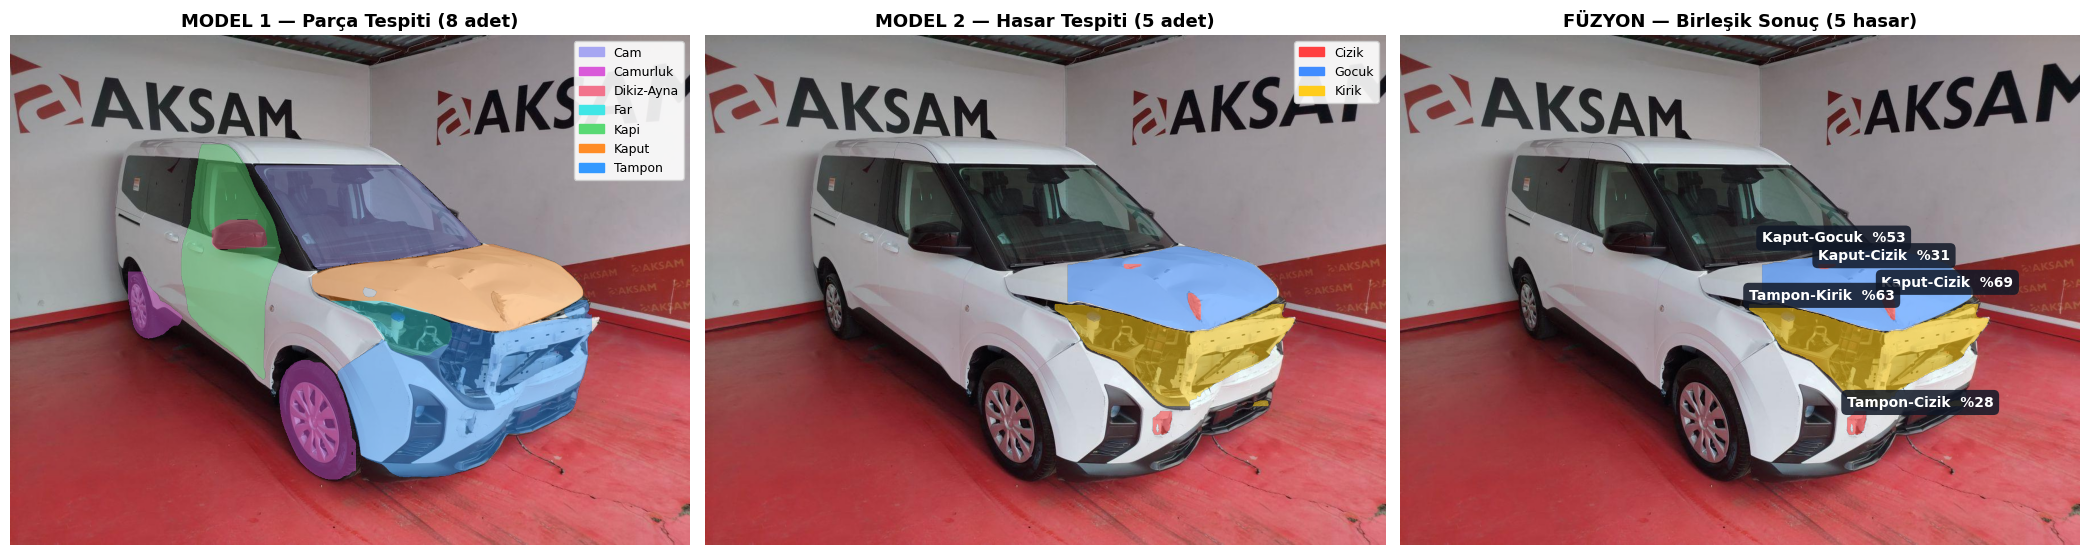


📋 TESPİT SONUÇLARI
1. Kaput-Cizik               güven: % 68.6 | alan: %0.08 | örtüşme: %100
2. Tampon-Kirik              güven: % 62.8 | alan: %3.53 | örtüşme: %75
3. Kaput-Gocuk               güven: % 52.9 | alan: %3.47 | örtüşme: %100
4. Kaput-Cizik               güven: % 30.9 | alan: %0.02 | örtüşme: %100
5. Tampon-Cizik              güven: % 28.0 | alan: %0.11 | örtüşme: %100
💾 /content/drive/MyDrive/tez_arac_hasar/ciktilar/gorseller/analiz_y5725921_20260731142441.png


In [12]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🖼️ HÜCRE 8: 3 PANELLİ GÖRSELLEŞTİRME
# ═══════════════════════════════════════════════════════════════════════════════
#
# Panel 1 → Model 1: Tespit edilen parçalar
# Panel 2 → Model 2: Tespit edilen hasarlar
# Panel 3 → FÜZYON: "Tampon-Kirik" etiketleriyle birleşik sonuç
#
# 🎛️ TEST_GORSEL:
#    None                → test setinden rastgele seç
#    '/content/foto.jpg' → kendi dosyan
#    'https://...'       → internetten
# ═══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import numpy as np, requests, io, random, os, cv2
from pathlib import Path

TEST_GORSEL = '/content/y5725921_20260731142441.jpeg'

# ─── GÖRSELİ YÜKLE ────────────────────────────────────────────────────────────
if TEST_GORSEL is None:
    if 'DATASET_DIR' not in globals() or DATASET_DIR is None:
        raise RuntimeError('❌ DATASET_DIR yok. TEST_GORSEL = "/content/1761729430677043775-6.jpg" yaz.')
    td = os.path.join(DATASET_DIR, 'test', 'images')
    adaylar = list(Path(td).glob('*.*'))
    if not adaylar:
        raise RuntimeError(f'❌ {td} boş!')
    TEST_GORSEL = str(random.choice(adaylar))
    print(f'🎲 Rastgele: {os.path.basename(TEST_GORSEL)}')

if str(TEST_GORSEL).startswith('http'):
    r = requests.get(TEST_GORSEL, timeout=15, headers={'User-Agent':'Mozilla/5.0'})
    img_np = np.array(Image.open(io.BytesIO(r.content)).convert('RGB'))
else:
    img_np = np.array(Image.open(TEST_GORSEL).convert('RGB'))

print(f'📐 Boyut: {img_np.shape[1]}x{img_np.shape[0]}')

# ─── ANALİZ ───────────────────────────────────────────────────────────────────
print('\n🔍 Analiz ediliyor...')
sonuc = fuzyon_analiz(img_np, verbose=True)

# ─── ÇİZ ──────────────────────────────────────────────────────────────────────
def overlay_ciz(ax, img, ogeler, renk_map, anahtar, alpha=0.45):
    ax.imshow(img)
    H, W = img.shape[:2]
    ov = np.zeros((H, W, 4), dtype=np.float32)
    for o in ogeler:
        c = renk_map.get(o[anahtar], [0.5,0.5,0.5])
        ov[o['mask'], :3] = c
        ov[o['mask'],  3] = alpha
    ax.imshow(ov); ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# Panel 1
overlay_ciz(axes[0], img_np, sonuc['parcalar'], PARCA_RENK, 'parca')
axes[0].set_title(f'MODEL 1 — Parça Tespiti ({len(sonuc["parcalar"])} adet)',
                  fontsize=13, fontweight='bold')
if sonuc['parcalar']:
    seen = {p['parca'] for p in sonuc['parcalar']}
    axes[0].legend(handles=[mpatches.Patch(color=PARCA_RENK.get(s,[.5]*3), label=s)
                            for s in sorted(seen)],
                   loc='upper right', fontsize=9, framealpha=0.9)

# Panel 2
overlay_ciz(axes[1], img_np, sonuc['hasarlar'], HASAR_RENK, 'hasar', alpha=0.55)
axes[1].set_title(f'MODEL 2 — Hasar Tespiti ({len(sonuc["hasarlar"])} adet)',
                  fontsize=13, fontweight='bold')
if sonuc['hasarlar']:
    seen = {h['hasar'] for h in sonuc['hasarlar']}
    axes[1].legend(handles=[mpatches.Patch(color=HASAR_RENK.get(s,[.5]*3), label=s)
                            for s in sorted(seen)],
                   loc='upper right', fontsize=9, framealpha=0.9)

# Panel 3 — Füzyon
axes[2].imshow(img_np)
H, W = img_np.shape[:2]
ov = np.zeros((H, W, 4), dtype=np.float32)
for b in sonuc['birlesik']:
    c = HASAR_RENK.get(b['hasar'], [0.5,0.5,0.5])
    ov[b['mask'], :3] = c
    ov[b['mask'],  3] = 0.6
axes[2].imshow(ov)
for b in sonuc['birlesik']:
    x1, y1, x2, y2 = b['bbox']
    axes[2].text(x1, max(y1-8, 12), f"{b['etiket']}  %{b['guven']*100:.0f}",
                 fontsize=10, fontweight='bold', color='white',
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='#111827',
                           alpha=0.85, edgecolor='none'))
axes[2].set_title(f'FÜZYON — Birleşik Sonuç ({len(sonuc["birlesik"])} hasar)',
                  fontsize=13, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
kayit = f'{GORSEL_DIR}/analiz_{os.path.basename(str(TEST_GORSEL)).split(".")[0]}.png'
plt.savefig(kayit, dpi=180, bbox_inches='tight')
plt.show()

# ─── METİN ÖZET ───────────────────────────────────────────────────────────────
print('\n' + '=' * 70)
print('📋 TESPİT SONUÇLARI')
print('=' * 70)
if sonuc['birlesik']:
    for i, b in enumerate(sonuc['birlesik'], 1):
        print(f'{i}. {b["etiket"]:25s} güven: %{b["guven"]*100:5.1f} | '
              f'alan: %{b["alan_yuzde"]:.2f} | örtüşme: %{b["ortusme"]*100:.0f}')
else:
    print('   Hasar tespit edilmedi.')
print('=' * 70)
print(f'💾 {kayit}')


---
## 📄 HÜCRE 9: TRAMER Raporu (PDF)

Sigorta ekspertiz belgesi formatında, Türkçe karakter destekli PDF.

Tablo: **Parça | Hasar | Alan | Güven | Durum** (Kesin ≥%70 / Olası ≥%45 / Şüpheli)


In [13]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📄 HÜCRE 9: TRAMER RAPORU ÜRETİCİ
# ═══════════════════════════════════════════════════════════════════════════════
#
# 📋 RAPOR İÇERİĞİ:
#    1. Başlık + belge no + tarih
#    2. Araç bilgileri (plaka, marka, model — manuel)
#    3. Hasar tablosu (Parça | Hasar | Alan | Güven | Durum)
#    4. Analiz görseli (gömülü)
#    5. Sistem bilgisi + yasal not
#
# 🔤 TÜRKÇE KARAKTER: DejaVuSans indirilir (ReportLab varsayılanında ğ/ş/ı yok)
#
# 📊 TABLO KAYNAKLARI:
#    Parça  → Model 1  |  Hasar → Model 2
#    Alan   → Model 2 maskesinin piksel oranı
#    Güven  → hasar_conf × parça_conf
#    Durum  → ≥%70 Kesin, ≥%45 Olası, altı Şüpheli
# ═══════════════════════════════════════════════════════════════════════════════

import os, urllib.request
from datetime import datetime
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import mm
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Table,
                                TableStyle, Image as RLImage)
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from PIL import Image as PILImage
import numpy as np

# ─── TÜRKÇE FONT ──────────────────────────────────────────────────────────────
FONT_DIR = '/content/fonts'
os.makedirs(FONT_DIR, exist_ok=True)
FONT_REG  = f'{FONT_DIR}/DejaVuSans.ttf'
FONT_BOLD = f'{FONT_DIR}/DejaVuSans-Bold.ttf'

if not os.path.exists(FONT_REG):
    print('📥 Türkçe font hazırlanıyor...')
    try:
        base = 'https://raw.githubusercontent.com/dejavu-fonts/dejavu-fonts/master/build/ttf'
        urllib.request.urlretrieve(f'{base}/DejaVuSans.ttf', FONT_REG)
        urllib.request.urlretrieve(f'{base}/DejaVuSans-Bold.ttf', FONT_BOLD)
    except Exception:
        # Yedek: sistem fontunu kullan
        import subprocess, shutil as _sh
        subprocess.run(['apt-get', 'install', '-y', 'fonts-dejavu-core', '-qq'],
                       capture_output=True)
        _sys = '/usr/share/fonts/truetype/dejavu'
        _sh.copy(f'{_sys}/DejaVuSans.ttf', FONT_REG)
        _sh.copy(f'{_sys}/DejaVuSans-Bold.ttf', FONT_BOLD)

pdfmetrics.registerFont(TTFont('DejaVu',      FONT_REG))
pdfmetrics.registerFont(TTFont('DejaVu-Bold', FONT_BOLD))
print('✅ Türkçe font hazır')


def tramer_raporu_olustur(sonuc, img_np, arac_bilgi=None, dosya_adi=None):
    """Füzyon sonucundan TRAMER formatında PDF üretir."""
    arac_bilgi = arac_bilgi or {}
    simdi = datetime.now()
    belge_no = arac_bilgi.get('hasar_no') or f"HT-{simdi.strftime('%Y%m%d-%H%M%S')}"
    dosya_adi = dosya_adi or f'{RAPOR_DIR}/tramer_{belge_no}.pdf'

    ss = getSampleStyleSheet()
    st_b  = ParagraphStyle('B', parent=ss['Title'], fontName='DejaVu-Bold',
                           fontSize=17, textColor=colors.HexColor('#0f172a'),
                           spaceAfter=2, alignment=1)
    st_a  = ParagraphStyle('A', parent=ss['Normal'], fontName='DejaVu',
                           fontSize=9.5, textColor=colors.HexColor('#64748b'),
                           alignment=1, spaceAfter=12)
    st_h  = ParagraphStyle('H', parent=ss['Heading2'], fontName='DejaVu-Bold',
                           fontSize=11.5, textColor=colors.HexColor('#1e40af'),
                           spaceBefore=13, spaceAfter=6)
    st_p  = ParagraphStyle('P', parent=ss['Normal'], fontName='DejaVu',
                           fontSize=9, leading=13)
    st_k  = ParagraphStyle('K', parent=ss['Normal'], fontName='DejaVu',
                           fontSize=7.5, textColor=colors.HexColor('#64748b'),
                           leading=11)

    doc = SimpleDocTemplate(dosya_adi, pagesize=A4,
                            leftMargin=18*mm, rightMargin=18*mm,
                            topMargin=15*mm, bottomMargin=15*mm)
    story = []

    story.append(Paragraph('ARAÇ HASAR TESPİT RAPORU', st_b))
    story.append(Paragraph('Yapay Zekâ Destekli Otomatik Ekspertiz Sistemi', st_a))

    # 0. Belge bilgileri
    t0 = Table([
        ['Belge No', belge_no, 'Düzenleme Tarihi', simdi.strftime('%d.%m.%Y %H:%M')],
        ['Poliçe No', arac_bilgi.get('police_no','—'), 'Rapor Türü', 'Otomatik Ön Tespit'],
    ], colWidths=[32*mm, 46*mm, 38*mm, 46*mm])
    t0.setStyle(TableStyle([
        ('FONTNAME',(0,0),(-1,-1),'DejaVu'),
        ('FONTNAME',(0,0),(0,-1),'DejaVu-Bold'),
        ('FONTNAME',(2,0),(2,-1),'DejaVu-Bold'),
        ('FONTSIZE',(0,0),(-1,-1),8.5),
        ('BACKGROUND',(0,0),(0,-1),colors.HexColor('#f1f5f9')),
        ('BACKGROUND',(2,0),(2,-1),colors.HexColor('#f1f5f9')),
        ('GRID',(0,0),(-1,-1),0.4,colors.HexColor('#cbd5e1')),
        ('VALIGN',(0,0),(-1,-1),'MIDDLE'),
        ('TOPPADDING',(0,0),(-1,-1),5),('BOTTOMPADDING',(0,0),(-1,-1),5),
    ]))
    story.append(t0)

    # 1. Araç
    story.append(Paragraph('1. ARAÇ BİLGİLERİ', st_h))
    t1 = Table([
        ['Plaka', arac_bilgi.get('plaka','—'), 'Marka', arac_bilgi.get('marka','—')],
        ['Model', arac_bilgi.get('model','—'), 'Model Yılı', str(arac_bilgi.get('yil','—'))],
        ['Şasi No', arac_bilgi.get('sase','—'), 'Renk', arac_bilgi.get('renk','—')],
    ], colWidths=[32*mm, 46*mm, 38*mm, 46*mm])
    t1.setStyle(TableStyle([
        ('FONTNAME',(0,0),(-1,-1),'DejaVu'),
        ('FONTNAME',(0,0),(0,-1),'DejaVu-Bold'),
        ('FONTNAME',(2,0),(2,-1),'DejaVu-Bold'),
        ('FONTSIZE',(0,0),(-1,-1),8.5),
        ('BACKGROUND',(0,0),(0,-1),colors.HexColor('#f8fafc')),
        ('BACKGROUND',(2,0),(2,-1),colors.HexColor('#f8fafc')),
        ('GRID',(0,0),(-1,-1),0.4,colors.HexColor('#cbd5e1')),
        ('TOPPADDING',(0,0),(-1,-1),5),('BOTTOMPADDING',(0,0),(-1,-1),5),
    ]))
    story.append(t1)

    # 2. Hasarlar
    story.append(Paragraph('2. TESPİT EDİLEN HASARLAR', st_h))
    birlesik = sonuc['birlesik']
    if birlesik:
        veri = [['#','Parça','Hasar Tipi','Alan (%)','Güven (%)','Durum']]
        for i, b in enumerate(birlesik, 1):
            durum = 'Kesin' if b['guven'] >= 0.70 else ('Olası' if b['guven'] >= 0.45 else 'Şüpheli')
            veri.append([str(i), b['parca'], b['hasar'],
                         f"{b['alan_yuzde']:.2f}", f"{b['guven']*100:.1f}", durum])

        th = Table(veri, colWidths=[10*mm,38*mm,32*mm,26*mm,26*mm,30*mm])
        stil = [
            ('FONTNAME',(0,0),(-1,0),'DejaVu-Bold'),
            ('FONTNAME',(0,1),(-1,-1),'DejaVu'),
            ('FONTSIZE',(0,0),(-1,-1),8.5),
            ('BACKGROUND',(0,0),(-1,0),colors.HexColor('#1e40af')),
            ('TEXTCOLOR',(0,0),(-1,0),colors.white),
            ('ALIGN',(0,0),(0,-1),'CENTER'),
            ('ALIGN',(3,0),(-1,-1),'CENTER'),
            ('GRID',(0,0),(-1,-1),0.4,colors.HexColor('#cbd5e1')),
            ('VALIGN',(0,0),(-1,-1),'MIDDLE'),
            ('TOPPADDING',(0,0),(-1,-1),5),('BOTTOMPADDING',(0,0),(-1,-1),5),
        ]
        for i in range(1, len(veri)):
            if i % 2 == 0:
                stil.append(('BACKGROUND',(0,i),(-1,i),colors.HexColor('#f8fafc')))
        th.setStyle(TableStyle(stil))
        story.append(th)

        ta = sum(b['alan_yuzde'] for b in birlesik)
        ps = ', '.join(sorted({b['parca'] for b in birlesik}))
        ts = ', '.join(sorted({b['hasar'] for b in birlesik}))
        story.append(Spacer(1, 7))
        story.append(Paragraph(
            f'<b>Özet:</b> Toplam <b>{len(birlesik)}</b> hasar tespit edildi. '
            f'Etkilenen parçalar: <b>{ps}</b>. Hasar tipleri: <b>{ts}</b>. '
            f'Toplam hasarlı alan: <b>%{ta:.2f}</b>.', st_p))
    else:
        story.append(Paragraph('Görselde herhangi bir hasar tespit edilmemiştir.', st_p))

    # 3. Görsel
    story.append(Paragraph('3. GÖRSEL ANALİZ', st_h))
    vis = img_np.astype(np.float32).copy()
    for b in birlesik:
        c = np.array(HASAR_RENK.get(b['hasar'], [0.5,0.5,0.5])) * 255
        vis[b['mask']] = vis[b['mask']] * 0.42 + c * 0.58
    vis = vis.astype(np.uint8)

    tmp = '/content/_rapor_gorsel.jpg'
    PILImage.fromarray(vis).save(tmp, 'JPEG', quality=88)
    ih, iw = vis.shape[:2]
    oran = min(160*mm/iw, 105*mm/ih)
    story.append(RLImage(tmp, width=iw*oran, height=ih*oran))
    story.append(Spacer(1, 4))
    story.append(Paragraph(f'Renk kodları: {" | ".join(HASAR_RENK)}', st_k))

    # 4. Sistem
    story.append(Paragraph('4. SİSTEM BİLGİSİ', st_h))
    t4 = Table([
        ['Parça Tespit Modeli', 'YOLOv11m-seg (Carparts-Seg)'],
        ['Hasar Tespit Modeli', EN_IYI.get('ad','—')],
        ['Hasar Modeli mAP50',  f"{EN_IYI.get('mask_mAP50',0):.4f}"],
        ['İşlem Süresi',        f"~{EN_IYI.get('inference_ms',0):.0f} ms/görsel"],
        ['Görüntü Çözünürlüğü', f"{sonuc['goruntu_boyut'][0]} x {sonuc['goruntu_boyut'][1]} px"],
    ], colWidths=[58*mm, 104*mm])
    t4.setStyle(TableStyle([
        ('FONTNAME',(0,0),(-1,-1),'DejaVu'),
        ('FONTNAME',(0,0),(0,-1),'DejaVu-Bold'),
        ('FONTSIZE',(0,0),(-1,-1),8),
        ('BACKGROUND',(0,0),(0,-1),colors.HexColor('#f8fafc')),
        ('GRID',(0,0),(-1,-1),0.4,colors.HexColor('#cbd5e1')),
        ('TOPPADDING',(0,0),(-1,-1),4),('BOTTOMPADDING',(0,0),(-1,-1),4),
    ]))
    story.append(t4)

    story.append(Spacer(1, 10))
    story.append(Paragraph(
        '<b>ÖNEMLİ AÇIKLAMA:</b> Bu rapor yapay zekâ tabanlı görüntü analiz sistemi '
        'tarafından otomatik olarak üretilmiştir ve <b>ön değerlendirme</b> niteliğindedir. '
        'Nihai hasar tespiti, onarım kapsamı ve tazminat tutarı yetkili eksper incelemesi '
        'sonucunda belirlenir. Sistem çıktıları yalnızca eksper iş akışını hızlandırmak '
        'amacıyla referans olarak kullanılmalıdır. Görüntü kalitesi, çekim açısı ve ışık '
        'koşulları tespit doğruluğunu etkileyebilir.', st_k))

    doc.build(story)
    return dosya_adi


# ─── ÖRNEK RAPOR ──────────────────────────────────────────────────────────────
print('\n📄 Örnek rapor üretiliyor...')
pdf = tramer_raporu_olustur(
    sonuc, img_np,
    arac_bilgi={
        'plaka':'34 ABC 123', 'marka':'Dacia', 'model':'Duster',
        'yil':2020, 'renk':'Siyah', 'sase':'WVWZZZ3CZLE000000',
        'police_no':'POL-2026-004521',
    })
print(f'✅ {pdf}')

try:
    from google.colab import files
    files.download(pdf)
except Exception:
    pass


📥 Türkçe font hazırlanıyor...
✅ Türkçe font hazır

📄 Örnek rapor üretiliyor...
✅ /content/drive/MyDrive/tez_arac_hasar/ciktilar/raporlar/tramer_HT-20260816-130020.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 📦 HÜCRE 10: Toplu İşlem + Excel Özet

Klasördeki tüm görselleri işler, analiz görseli + PDF üretir, Excel'e yazar, ZIP'ler.

⚠️ TTA açıkken 3x yavaş — çok görsel varsa `TTA_KULLAN = False` düşün.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📦 HÜCRE 10: TOPLU İŞLEM
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE YAPAR?
#    - Klasördeki tüm görselleri işler
#    - Her biri için analiz görseli + TRAMER PDF üretir
#    - Sonuçları Excel'e yazar (3 sayfa: detay, matris, özet)
#    - Hepsini ZIP'ler
#
# 🎛️ AYARLAR:
#    KAYNAK_KLASOR : İşlenecek görsellerin klasörü
#    LIMIT         : Kaç görsel (None = hepsi)
#    PDF_URET      : Her görsel için PDF üretilsin mi
# ═══════════════════════════════════════════════════════════════════════════════

import pandas as pd, shutil, time, os
import numpy as np
from pathlib import Path
from PIL import Image

KAYNAK_KLASOR = os.path.join(DATASET_DIR, 'test', 'images') if DATASET_DIR else '/content/fotograflar'
LIMIT       = 20        # None = hepsi
PDF_URET    = True
GORSEL_URET = True

gorseller = sorted([p for p in Path(KAYNAK_KLASOR).glob('*.*')
                    if p.suffix.lower() in ['.jpg','.jpeg','.png']])
if LIMIT:
    gorseller = gorseller[:LIMIT]

print('=' * 70)
print(f'📦 TOPLU İŞLEM — {len(gorseller)} görsel')
print('=' * 70)
print(f'   Kaynak: {KAYNAK_KLASOR}')
print(f'   PDF   : {PDF_URET}  |  Görsel: {GORSEL_URET}')
print('=' * 70)

kayitlar = []
t0 = time.time()

for i, gp in enumerate(gorseller, 1):
    try:
        img = np.array(Image.open(gp).convert('RGB'))
        s = fuzyon_analiz(img)

        if s['birlesik']:
            for b in s['birlesik']:
                kayitlar.append({
                    'Dosya':      gp.name,
                    'Etiket':     b['etiket'],
                    'Parça':      b['parca'],
                    'Hasar Tipi': b['hasar'],
                    'Güven (%)':  round(b['guven']*100, 1),
                    'Alan (%)':   round(b['alan_yuzde'], 3),
                    'Örtüşme(%)': round(b['ortusme']*100, 1),
                })
        else:
            kayitlar.append({'Dosya': gp.name, 'Etiket':'—', 'Parça':'—',
                             'Hasar Tipi':'Tespit yok', 'Güven (%)':0,
                             'Alan (%)':0, 'Örtüşme(%)':0})

        if GORSEL_URET and s['birlesik']:
            vis = img.astype(np.float32).copy()
            for b in s['birlesik']:
                c = np.array(HASAR_RENK.get(b['hasar'], [0.5]*3)) * 255
                vis[b['mask']] = vis[b['mask']]*0.42 + c*0.58
            Image.fromarray(vis.astype(np.uint8)).save(
                f'{GORSEL_DIR}/{gp.stem}_analiz.jpg', 'JPEG', quality=88)

        if PDF_URET:
            tramer_raporu_olustur(s, img,
                arac_bilgi={'hasar_no': f'HT-{gp.stem[:20]}'},
                dosya_adi=f'{RAPOR_DIR}/rapor_{gp.stem}.pdf')

        if i % 5 == 0 or i == len(gorseller):
            gec = time.time() - t0
            hiz = i / gec if gec > 0 else 0
            kal = (len(gorseller)-i) / hiz if hiz > 0 else 0
            print(f'   {i}/{len(gorseller)} | {hiz:.2f} görsel/sn | ~{kal:.0f}sn kaldı')

    except Exception as e:
        print(f'   ⚠️ {gp.name}: {str(e)[:80]}')

# ─── EXCEL ────────────────────────────────────────────────────────────────────
df_s = pd.DataFrame(kayitlar)
excel_yol = f'{OUTPUT_DIR}/toplu_analiz_sonuclari.xlsx'

with pd.ExcelWriter(excel_yol, engine='openpyxl') as w:
    df_s.to_excel(w, sheet_name='Tüm Tespitler', index=False)
    gecerli = df_s[df_s['Hasar Tipi'] != 'Tespit yok']
    if not gecerli.empty:
        pd.crosstab(gecerli['Parça'], gecerli['Hasar Tipi'],
                    margins=True, margins_name='TOPLAM'
                    ).to_excel(w, sheet_name='Parça-Hasar Matrisi')
        gecerli.groupby('Etiket').agg(
            Adet=('Etiket','count'),
            Ort_Guven=('Güven (%)','mean'),
            Ort_Alan=('Alan (%)','mean'),
        ).round(2).sort_values('Adet', ascending=False
        ).to_excel(w, sheet_name='Etiket Özeti')

print('\n' + '=' * 70)
print('✅ TOPLU İŞLEM TAMAMLANDI')
print('=' * 70)
print(f'   İşlenen görsel : {len(gorseller)}')
print(f'   Toplam tespit  : {len(df_s[df_s["Hasar Tipi"] != "Tespit yok"])}')
print(f'   Süre           : {(time.time()-t0)/60:.1f} dk')
print(f'\n   📊 {excel_yol}')
print(f'   📄 {RAPOR_DIR}')
print(f'   🖼️  {GORSEL_DIR}')

gecerli = df_s[df_s['Hasar Tipi'] != 'Tespit yok']
if not gecerli.empty:
    print(f'\n🏷️  EN SIK ETİKETLER:')
    for et, ad in gecerli['Etiket'].value_counts().head(10).items():
        print(f'   {et:28s}: {ad}')

# ─── ZIP ──────────────────────────────────────────────────────────────────────
print('\n📦 Arşivleniyor...')
zip_yol = shutil.make_archive('/content/tez_ciktilari', 'zip', OUTPUT_DIR)
print(f'✅ {zip_yol}')

try:
    from google.colab import files
    files.download(zip_yol)
except Exception:
    print('   (Colab dışı — manuel indir)')


📦 TOPLU İŞLEM — 0 görsel
   Kaynak: /content/fotograflar
   PDF   : True  |  Görsel: True


KeyError: 'Hasar Tipi'

---
# 📋 Hızlı Referans

## 🔨 İlk Kez
```
0 → 1 → 3 → 4 → 4A → 4A2 → 4D → 4B → 4C → 4E → (temizlik) → 5 → 6 → 6B
```

## 🔄 Kopma Sonrası
```
0 → 0B → 1 → 5 (RESUME=True)
```

## ⚡ Model Hazırsa
```
0 → 1 → 6D → 7 → 8 / 9 / 10
```

---

## 🔧 Sorun Giderme

| Belirti | Sebep | Çözüm |
|---|---|---|
| 4A'da `Alınacak sınıf: ['Cizik','Gocuk','Kirik']` | Hücre 1 çalışmamış | Hücre 1'i çalıştır |
| 4A2'de dengesizlik > 1,6 | Oversampling yetersiz | `MAX_KOPYA = 3` yap |
| `CUDA out of memory` | Large model + batch 6 | batch 4'e düşür |
| Eğitimde `nan` | fp16 taşması | `amp=False` yap |
| mAP 20 epoch'ta düşüyor | Domain shift | Kendi veri oranını kontrol et |
| `RESUME=True ama last.pt yok` | Yanlış `ABLATION_ETIKET` | `v6_large_gocuk` olmalı |
| `coco8-seg.yaml` hatası | Dataset yolu kayıp | Hücre 5 symlink'i otomatik kurar |
| TTA çok yavaş | 3x inference | `TTA_KULLAN = False` |

---

## 📊 Sonuç Değerlendirme

| Mask mAP50 | Anlam | Aksiyon |
|---|---|---|
| ≥ 0,76 | Hedefin üstü 🎉 | Tezi yaz |
| 0,72–0,76 | **v6 hedefi tuttu** ✅ | Tezi yaz |
| 0,69–0,72 | v3'ü geçti | Hiperparametre taraması düşün |
| 0,63–0,69 | v3 ile başabaş | v3 modeliyle devam |
| < 0,63 | Beklenenin altı ❌ | Birlikte analiz edelim |

---

## 💡 Confusion Matrix — v6'da Neye Bakmalı

| Gözlem | Anlamı |
|---|---|
| **Cizik ↔ Kirik karışımı azaldı** | ✅ v6 çözümü işe yaradı |
| Karışım aynı kaldı | ⚠️ Çelişki kendi verinde de var olabilir |
| Köşegen > 0,80 | ✅ Sınıflar iyi ayrılıyor |
| background sütunu düşük | ✅ Yanlış pozitif az |

---

## 📝 Makaleye Eklenecekler

| # | Bulgu | Bölüm |
|---|---|---|
| 1 | Genelleme analizi (300 görülmemiş görsel, %60 düşük güven) | Bulgular |
| 2 | v4 negatif sonucu (domain shift, 0,6894 → 0,3319) | Tartışma |
| 3 | **Sınıf tanımı çelişkisi bulgusu** (v5 → v6 gerekçesi) | Tartışma |
| 4 | Güvenli oran rehberi (%79/%21) | Metodoloji |
| 5 | Eşik analizi (conf 0,386 → 0,94 tespit/görsel) | Bulgular |
| 6 | Ablasyon tablosu (v0→v1→v3→v4→v5→v6) | Bulgular |
| 7 | Perceptual hash dedupe metodolojisi | Metodoloji |
| 8 | TTA etkisi | Bulgular |
| 9 | Atıflar (kullanıcı iletecek) | Kaynaklar |

---

## 🚧 Sonraki Aşama

| Model | Durum |
|---|---|
| 1 — Parça tespiti | ✅ Tamamlandı |
| 2 — Hasar tespiti | 🔄 v6 |
| 3 — Şiddet (hafif/orta/ağır) | ❌ Şiddet etiketli veri gerekli |
| 4 — Fiyat tahmini | ❌ Fiyat veri tabanı gerekli (MSE/RMSE/MAE burada) |
